配图网站，http://lcpmgh.com/colors/
https://github.com/lcpmgh/colors

In [2]:
import numpy as np
import time
from scipy.linalg import expm
import scipy as sy
import matplotlib.pyplot as plt
from matplotlib import colors
from numba import jit, cuda
import matplotlib as mpl

sigma_0 = np.array([[1., 0.], [0., 1.]], dtype='complex')
sigma_x = np.array([[0., 1.], [1., 0.]], dtype='complex')
sigma_y = np.array([[0., -1j], [1j, 0.]], dtype='complex')
sigma_z = np.array([[1., 0.], [0.,-1.]], dtype='complex')
np.random.seed(1)

def Calculate_IPR(state):
    # smaller than 1, skin state have O(1/Ly) but corner state have O(1) 'IPR'
    temp_state = np.abs(state) ** 2
    popu_state = temp_state[::2] + temp_state[1::2]
    denominator = np.sum(popu_state) ** 2
    nominator = np.sum(np.abs(popu_state) ** 2)
    return nominator / denominator

def Plot_Lattice1(state, num_xsite, num_ysite, num_sub, pattern='2D', cnorm=None):
    """
    The aim of this function is to plot the edge state or corner state.
    In order to plot the degenerate eigenfunction simultaneously, we save the eigenstate in a dict.
    :param state: dict
        The state we want to plot
    :param num_xsite: the number of site in x direction
    :param num_ysite: the number of site in y direction
    :param num_sub: the number of atoms in one unit cell
    :param pattern: The picture we plot is '2D' or '3D'?
    :return:
    """
    if type(state) == np.ndarray:
        state1 = {}
        state1[0] = state
        state = state1
    # state = np.array(state)
    popu_state = np.zeros((num_xsite * num_ysite))
    for key in state.keys():
        # plot several eigenstate.
        for i in range(num_sub):
            popu_state += np.abs(state[key][i::num_sub]) ** 2
    new_state = popu_state.reshape([num_xsite, num_ysite])
    #new_state = new_state[::-1]

    # 2D
    if pattern == '2D':
        fig = plt.figure(figsize=(10, 8))
        dx = np.arange(0, num_xsite)
        dy = np.arange(0, num_ysite)
        plt.pcolormesh(dx, dy, new_state, cmap='seismic', norm=cnorm)
        plt.colorbar()
        plt.show()
    # 3D
    elif pattern == '3D':
        fig = plt.figure(figsize=(10, 8))
        width = depth = 1
        dx = np.arange(0, num_xsite)
        dy = np.arange(0, num_ysite)
        dx, dy = np.meshgrid(dx, dy)
        dx_l = dx.ravel()
        dy_l = dy.ravel()
        # print(type(x))
        new_state_l = new_state.ravel()
        bottom = np.zeros_like(new_state_l)
        ax1 = fig.add_subplot(111, projection='3d')
        # ax3 = plt.axes(projection='3d')
        ax1.bar3d(dx_l, dy_l, bottom, width, depth, new_state_l, cmap='seismic')
        ax1.set_title('1')
        plt.show()
    else:
        return new_state


def RealHam_QWZ_Dissapation(u, A, gamma, num_xsite, num_ysite, boundary='open', B=1):
    """
    Give out the Hamiltonian in real space of QiWuZhang model.
    :param u: parameter u
    :param A:
    :param num_xsite: how many sites in x direction
    :param num_ysite: how many sites in y direction
    :return:
    """
    ham = np.zeros((2 * num_xsite * num_ysite, 2 * num_xsite * num_ysite), dtype='complex')
    for delta_x in range(num_xsite):
        for delta_y in range(num_ysite):
            row = 2 * (delta_x * num_ysite + delta_y)
            ham[row:row + 2, row:row + 2] = [[u, 0], [0, -u]]
    for delta_x in range(num_xsite - 1):
        for delta_y in range(num_ysite):
            # A site to A site in x direction.
            delta_col = 2 * (delta_x * num_ysite + delta_y)
            delta_row = 2 * ((delta_x + 1) * num_ysite + delta_y)
            ham[delta_row:delta_row + 2, delta_col:delta_col + 2] = [[1 / 2, A * 1j / 2], [A * 1j / 2, -1 / 2]]
            ham[delta_col:delta_col + 2, delta_row:delta_row + 2] = [[1 / 2, -A * 1j / 2], [-A * 1j / 2, -1 / 2]]
    for delta_x in range(num_xsite):
        for delta_y in range(num_ysite - 1):
            # A site to A site
            delta_col = 2 * (delta_x * num_ysite + delta_y)
            delta_row = 2 * ((delta_x) * num_ysite + delta_y + 1)
            ham[delta_row:delta_row + 2, delta_col:delta_col + 2] = [[1 / 2, B / 2], [-B / 2, -1 / 2]]
            ham[delta_col:delta_col + 2, delta_row:delta_row + 2] = [[1 / 2, -B / 2], [B / 2, -1 / 2]]
    if boundary=='close_x':
        # x方向封闭，但是y方向open
        site_constant = 2*num_ysite*(num_xsite-1)
        for i in range(num_ysite):
            ham[2 * i:2 * i + 2, site_constant + 2 * i:site_constant + 2 * i + 2] = [[1 / 2, A * 1j / 2],[A * 1j / 2, -1 / 2]]
            ham[site_constant + 2 * i:site_constant + 2 * i + 2, 2 * i:2 * i + 2] = [[1 / 2, -A * 1j / 2],
                                                                                     [-A * 1j / 2, -1 / 2]]
    if boundary=='close':
        # close x
        site_constant = 2 * num_ysite * (num_xsite - 1)
        for i in range(num_ysite):
            ham[2 * i:2 * i + 2, site_constant + 2 * i:site_constant + 2 * i + 2] = [[1 / 2, A * 1j / 2],[A * 1j / 2, -1 / 2]]
            ham[site_constant + 2 * i:site_constant + 2 * i + 2, 2 * i:2 * i + 2] = [[1 / 2, -A * 1j / 2],[-A * 1j / 2, -1 / 2]]
        # close y
        site_constant = 2 * (num_ysite - 1)
        for i in range(num_xsite):
            ham[2 * i * num_ysite:2 * i * num_ysite + 2,
            2 * i * num_ysite + site_constant:2 * i * num_ysite + 2 + site_constant] = [[1 / 2, 1 / 2], [-1 / 2, -1 / 2]]
            ham[2 * i * num_ysite + site_constant:2 * i * num_ysite + 2 + site_constant,
            2 * i * num_ysite:2 * i * num_ysite + 2] = [[1 / 2, -1 / 2], [1 / 2, -1 / 2]]
    # 在x=0的边界出加decay.  
    # 2 5
    # 1 4
    # 0 3
    # edge dissipation
    # for delta_x in range(num_xsite):
    #     row = 2 * (delta_x * num_ysite + 0)
    #     ham[row:row + 2, row:row + 2] += [[-1j*gamma, 0.], [0., -1j*gamma]]
    # dissipation at the edge y=0,上面写错了
    for delta_y in range(num_xsite):
        row = 2 * (delta_y * num_ysite + 0)
        ham[row:row + 2, row:row + 2] += [[-1j*gamma, 0.], [0., -1j*gamma]]
    return ham

def GeneratePOVM(gamma, T, num_xsite, num_ysite, position):
    # position used to be the x edge(y=0). Now we choose which position is dissipative.
    # 其实直接展开的方案与直接通过非厄米计算得到的也不是完全相等。
    # the hopping from edge to ancilla is different from 'gamma'.
    povm_list = np.zeros((len(position), 2 * num_xsite * num_ysite, 2 * num_xsite * num_ysite), dtype='complex')
    para = np.sqrt(np.exp(2*gamma*T)-1)  # approxition, np.sqrt(2*gamma * T), np.sqrt(1-(1-T*gamma)**2).
    print(gamma)
    if position==None:
        position = [0] * num_xsite
        for i in range(num_xsite):
            position[i] = i*num_ysite
    for site in range(len(position)):
        temp_povm = np.identity(2 * num_xsite * num_ysite, dtype='complex')
        row = 2*position[site]
        #temp_povm[row:row + 2, row:row + 2] += [[-T*gamma, 0.], [0., -T*gamma]]
        #temp_povm[row, row] += -T*gamma
        #temp_povm[row+1, row+1] += -T*gamma
        # loss non-Hermitian Hamiltonian
        temp_povm[row, row] += -1+np.exp(-gamma*T)  # The one we take is better.
        temp_povm[row+1, row + 1] += -1+np.exp(-gamma*T)  #np.sqrt(1-(1-T*gamma)**2)
        povm_list[site] = temp_povm
        '''
        # gain non-Hermitian Hamiltonian
        #temp_povm[row, row] += -1 + np.exp(gamma * T)  # The one we take is better.
        #temp_povm[row + 1, row + 1] += -1 + np.exp(gamma * T)  # np.sqrt(1-(1-T*gamma)**2)
        #povm_list[site] = temp_povm'''

    return povm_list


def GenerateHeff(p, N, num_xsite, num_ysite, u, gamma=0.2, T=0.001, position=None, boundary='open', ret_type='ham'):
    # 如果在这里的采用@jit, 那么最后得到的ham不会有区别，也不知道为啥。
    evo_ham = RealHam_QWZ_Dissapation(u, 1, 0, num_xsite, num_ysite, boundary)
    evo = expm(-1j*evo_ham*T)
    Mj_plus = GeneratePOVM(gamma, T, num_xsite, num_ysite, position)
    fps = np.identity((2*num_xsite*num_ysite), dtype='complex')
    for i in range(N):
        random_num = np.random.random(num_xsite)
        total_measure = np.identity(2*num_xsite*num_ysite, dtype='complex')
        #  这一个不太方便采用半满时候同样的分析，因为site太大了，也就是说需要储存很多。还是这种方式更方便。
        for j in range(num_xsite):
            if random_num[j] <= p:
                total_measure = np.dot(Mj_plus[j], total_measure)
        #for j in range(len(total_measure[0])):
        #    total_measure[:, j] = total_measure[:, j] / np.sqrt(np.sum(np.abs(total_measure[:, j]) ** 2))
        Fps = np.dot(total_measure, evo)
        # 这里对每一个列向量进行归一化就对应遍历了不同的初态。
        # 但是这里存在一个问题，不能对态进行归一化，归一化就不能得到正确的结果，就抹去了测量的效果。所以不在对应测量？
        fps = np.dot(Fps, fps)
    heff = 1j/(N*T) * sy.linalg.logm(fps)
    if ret_type == 'evo':
        return fps
    else:
        return heff

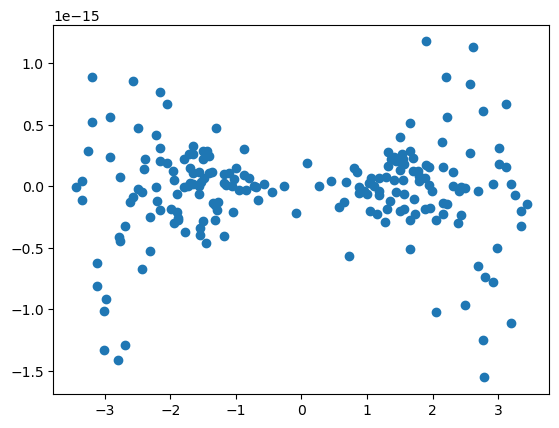

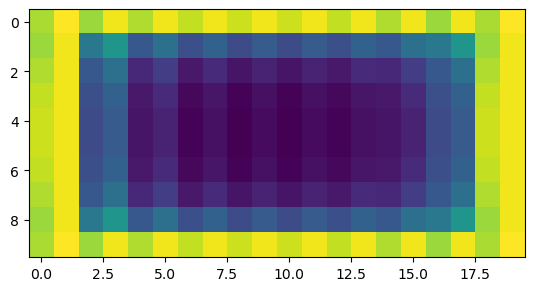

In [3]:
u = -1.5 # u 太大之后使topological trivial的。
gamma = 0.0
num_xsite = 10
num_ysite = 10
ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from scipy.linalg import expm

# 参数设置
Lx, Ly = num_xsite, num_ysite
N = 2 * Lx * Ly      # 总格点数
t_vals = np.linspace(0, 30, 400)  # 时间序列

# 初态 (1,1)
psi0 = np.zeros(N, dtype=np.complex128)
psi0[0] = 1.0  # (1,1) 的索引是 1*Ly + 1

# 计算所有时刻的波函数和概率密度
psi_t_list = []
U_Deltat = U_t = expm(-1j * ham22 * t_vals[1])
for t in t_vals:
    U_t = expm(-1j * ham22 * t)
    psi_t = U_t @ psi0
    psi_t = psi_t / np.linalg.norm(psi_t)
    prob_density = np.abs(psi_t.reshape(Lx, 2*Ly))**2
    psi_t_list.append(prob_density)

# 创建动画
fig, ax = plt.subplots()
cax = ax.imshow(psi_t_list[0], origin='lower', interpolation='none', vmin=0, vmax=0.1)
fig.colorbar(cax)
title = ax.set_title("t = 0.0")

def update(frame):
    cax.set_data(psi_t_list[frame])
    title.set_text(f"t = {t_vals[frame]:.2f}")
    return cax, title

ani = animation.FuncAnimation(fig, update, frames=len(t_vals), interval=50)
ani.save("DataPicture/quantum_evolution.mp4", writer='ffmpeg')
plt.close()

eigval, eigvec = np.linalg.eig(ham22)
eigvec = eigvec[:, np.argsort(np.abs(eigval))]
eigval = eigval[np.argsort(np.abs(eigval))]
plt.plot(eigval.real, eigval.imag, 'o')
plt.show()

plt.imshow(np.abs(eigvec[:,0].reshape(Lx, 2*Ly))**2)
plt.show()

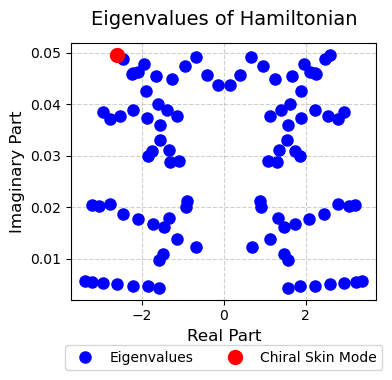

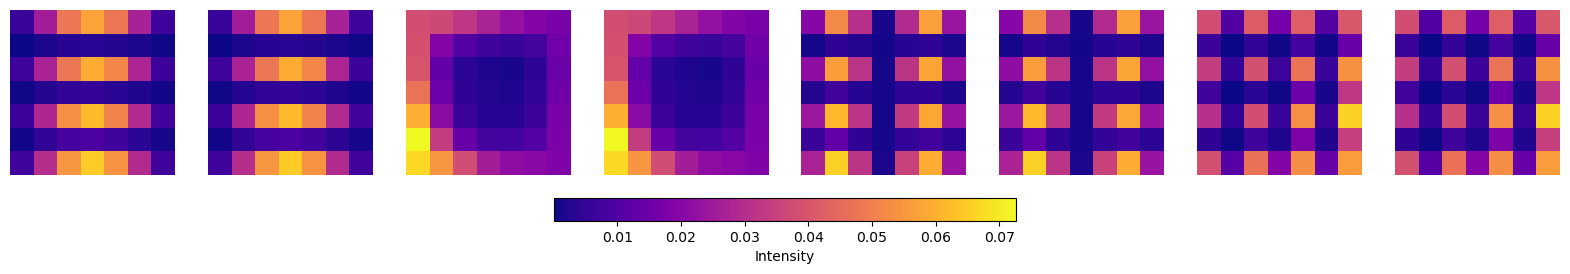

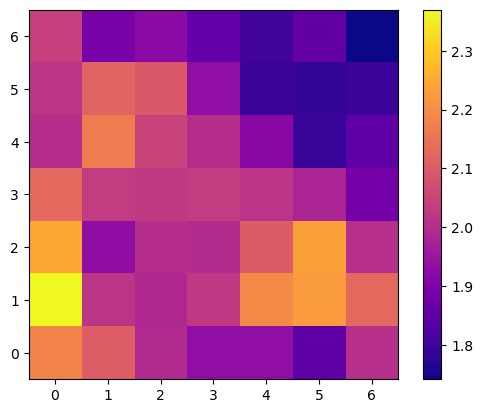

[6.99811637e-03 2.82849324e-04 7.65447303e-04 8.55527669e-05
 6.08303090e-03 2.19092399e-04 3.54857697e-04 1.20350411e-04
 6.71192140e-03 2.58166570e-04 1.01076435e-04 1.66056400e-04
 5.63919799e-03 2.84083834e-04 3.02033351e-02 1.06463772e-04
 3.70803455e-03 8.65575221e-04 2.86371213e-02 3.22778344e-05
 1.67167930e-03 9.26518334e-04 2.73295967e-02 5.63492453e-05
 7.25743978e-04 9.62235415e-04 2.56255918e-02 1.64225034e-04
 5.46741246e-02 4.02836439e-05 6.40518579e-03 2.02225216e-03
 5.34313585e-02 3.10602352e-05 2.63734453e-03 1.97987397e-03
 4.81755316e-02 2.54316991e-06 1.33507837e-03 1.94327961e-03
 4.79982617e-02 6.35092932e-05 6.47747937e-02 1.11850167e-04
 6.66480651e-03 2.69848347e-03 6.17177019e-02 1.88907517e-04
 2.49461282e-03 2.55190184e-03 5.91389442e-02 4.93302473e-05
 1.16001964e-03 2.46348910e-03 5.70411630e-02 4.66128711e-05
 5.38304080e-02 2.67729476e-04 4.81090381e-03 2.41554655e-03
 5.04709982e-02 3.52910180e-04 1.73059783e-03 2.25805150e-03
 5.13717317e-02 1.921206

In [89]:
u = -1.5 # u 太大之后使topological trivial的。
gamma = -0.2
num_xsite = 7
num_ysite = 7
ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
eigval, eigvec = np.linalg.eig(ham22)
# eigvec = eigvec[:, np.argsort(np.abs(eigval.real))]
# eigval = eigval[np.argsort(np.abs(eigval.real))]
eigvec = eigvec[:, np.argsort(-np.imag(eigval))]
eigval = eigval[np.argsort(-np.imag(eigval))]
plt.figure(figsize=(4, 4))
plt.plot(eigval.real, eigval.imag, 'o', label='Eigenvalues', markersize=8, color='blue')
plt.plot(eigval[0].real, eigval[0].imag, 'ro', label='Chiral Skin Mode', markersize=10)  # 突出显示基态
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlabel('Real Part', fontsize=12)
plt.ylabel('Imaginary Part', fontsize=12)
plt.title('Eigenvalues of Hamiltonian', fontsize=14, y=1.04)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),fontsize=10,ncol=2)
plt.tight_layout()
plt.show()

# plt.rcParams.update({
#     'lines.linewidth': 2,      # 默认线宽
#     'lines.markersize': 10,    # 默认标记大小
#     'font.size': 12,           # 默认字体大小
#     'axes.labelsize': 14,      # 坐标轴标签大小
#     'axes.titlesize': 16,      # 标题大小
#     'legend.fontsize': 12       # 图例文字大小
# })

#Plot_Lattice1(eigvec[:, 0], num_xsite, num_ysite, 2, pattern='2D')#, cnorm=vnorm)
# 画出所有本征态
# fig, ax = plt.subplots(1,8, figsize=(20, 3))
# vnorm = mpl.colors.Normalize(vmin=0.2, vmax=0.3)
# for i in range(8):
#     popu_state = np.zeros((num_xsite * num_ysite))
#     popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2,i]) ** 2
#     new_state = popu_state.reshape([num_xsite, num_ysite])
#     ax[i].imshow(new_state, cmap='seismic', norm=vnorm)
#     #dx = np.arange(0, num_xsite)
#     #dy = np.arange(0, num_ysite)
#     #plt.pcolormesh(dx, dy, new_state, cmap='seismic', norm=vnorm)
#     print(new_state)
# plt.colorbar()
# plt.show()
fig, ax = plt.subplots(1, 8, figsize=(20, 3))
vmin, vmax = 0.2, 0.3  # 统一的颜色范围
# 计算所有数据的最小值和最大值
all_data = []
for i in range(8):
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    all_data.append(popu_state)
all_data = np.concatenate(all_data)
vmin, vmax = np.min(all_data), np.max(all_data)

color_string = 'plasma'  # 'seismic'这一个就完全使红蓝的。
# 创建一个 ScalarMappable 对象用于 colorbar
sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])  # 空数组，仅用于 colorbar

for i in range(8):
    popu_state = np.zeros((num_xsite * num_ysite))
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    new_state = popu_state.reshape([num_xsite, num_ysite]).T
    im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax,origin='lower')

    # 在每个格子中心添加数值文本
    # for x in range(num_xsite):
    #     for y in range(num_ysite):
    #         ax[i].text(y, x, f'{new_state[x, y]:.2f}', ha='center', va='center', color='black', fontsize=10)

    ax[i].axis('off')  # 关闭坐标轴

# 添加 colorbar
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
cbar.set_label('Intensity')

plt.show()

a = np.zeros(num_xsite*num_ysite)
for i in range(len(eigvec)):
    a += np.abs(eigvec[::2,i])**2 + np.abs(eigvec[1::2,i])**2
    
new_state = a.reshape([num_xsite, num_ysite]).T
im = plt.imshow(new_state, cmap=color_string, origin='lower')
plt.colorbar()
plt.show()
print(np.abs(eigvec[:,0])**2)

## Chiral skin

C:\Users\18349\AppData\Local\Temp\ipykernel_170160\1580017926.py:145: RuntimeWarning: invalid value encountered in sqrt
  para = np.sqrt(np.exp(2*gamma*T)-1)  # approxition, np.sqrt(2*gamma * T), np.sqrt(1-(1-T*gamma)**2).


-0.2
logm result may be inaccurate, approximate err = 1.3186143253223207e-10


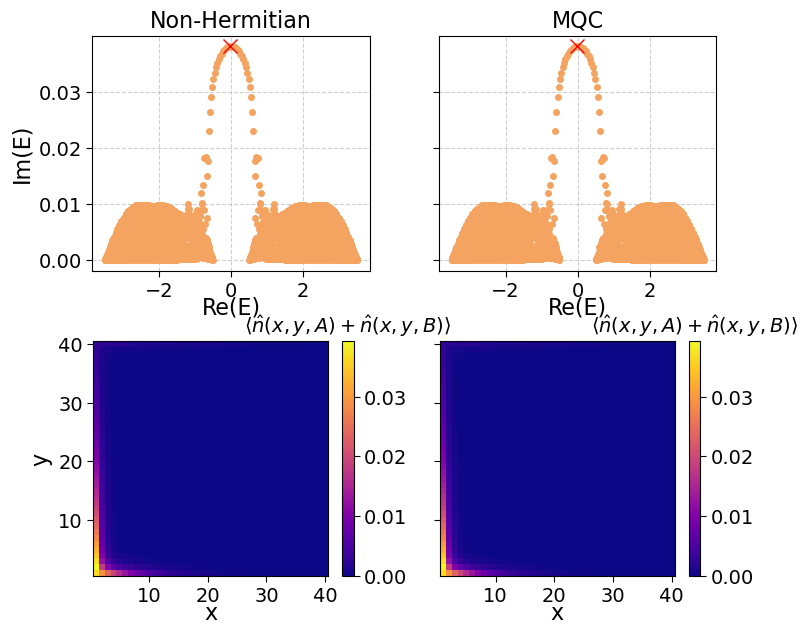

In [ ]:
u = -1.5
gamma = -0.2
p = 1.0  # 0.05, 0.95
N = 200
T = 0.001
num_xsite = 40 # 93min for 40*40
num_ysite = 40
position = []
for i in range(num_xsite):
    position.append(i*num_ysite)
ham_non = RealHam_QWZ_Dissapation(u, 1, gamma*p, num_xsite, num_ysite, boundary='open')
ham_1scheme = GenerateHeff(p, N, num_xsite, num_ysite, u, gamma=gamma, T=T, position=position, boundary='open', ret_type='ham')
color_bar = '#F4A460'

# the results of non-Hermitian Hamiltonian.
eigval_non, eigvec_non = np.linalg.eig(ham_non)
eigvec_non = eigvec_non[:, np.argsort(np.abs(eigval_non.real))]
eigval_non = eigval_non[np.argsort(np.abs(eigval_non.real))]
# the results of the first scheme.
eigval_1scheme, eigvec_1scheme = np.linalg.eig(ham_1scheme)
eigvec_1scheme = eigvec_1scheme[:, np.argsort(np.abs(eigval_1scheme.real))]
eigval_1scheme = eigval_1scheme[np.argsort(np.abs(eigval_1scheme.real))]

fontsize_label = 16
labelsize = 14
labelpad = -3
title_y = 1.
fig, ax = plt.subplots(2,2,figsize=(8, 6),sharey='row')
#plt.figure(figsize=(4, 4))
ax[0, 0].plot(eigval_non.real, eigval_non.imag, 'o', label='Eigenvalues', markersize=4, color=color_bar)
ax[0, 0].plot(eigval_non[0].real, eigval_non[0].imag, 'rx', label='Chiral Skin Mode', markersize=10)  # 突出显示基态
ax[0, 0].grid(True, linestyle='--', alpha=0.6)
ax[0,0].set_xlabel('Re(E)', fontsize=fontsize_label, labelpad=labelpad)
ax[0,0].set_ylabel('Im(E)', fontsize=fontsize_label)
ax[0,0].set_title('Non-Hermitian', fontsize=fontsize_label, y=title_y)
ax[0, 0].tick_params(axis='both', which='major', labelsize=labelsize)

ax[0, 1].plot(eigval_1scheme.real, eigval_1scheme.imag, 'o', label='Eigenvalues', markersize=4, color=color_bar)
ax[0, 1].plot(eigval_1scheme[0].real, eigval_1scheme[0].imag, 'rx', label='Chiral Skin Mode', markersize=10)  # 突出显示基态
ax[0, 1].grid(True, linestyle='--', alpha=0.6)
ax[0, 1].set_xlabel('Re(E)', fontsize=fontsize_label, labelpad=labelpad)
#ax[0, 1].set_ylabel('Imaginary Part', fontsize=12)
ax[0, 1].set_title('MQC', fontsize=fontsize_label, y=title_y)
ax[0, 1].tick_params(axis='both', which='major', labelsize=labelsize)
# plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),fontsize=10,ncol=2)

# 处理本征态，首先定义颜色范围
# all_data = []
# for i in range(1):
#     popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
#     all_data.append(popu_state)
# all_data = np.concatenate(all_data)
# vmin, vmax = np.min(all_data), np.max(all_data)
popu_non = np.abs(eigvec_non[::2, 0]) ** 2 + np.abs(eigvec_non[1::2, 0]) ** 2
popu_1scheme = np.abs(eigvec_1scheme[::2, 0]) ** 2 + np.abs(eigvec_1scheme[1::2, 0]) ** 2
vmin, vmax = np.min(popu_non), np.max(popu_non)

color_string = 'plasma'#'viridis'#'cividis' # 'plasma'  # 'seismic'这一个就完全使红蓝的。
# 创建一个 ScalarMappable 对象用于 colorbar
sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])  # 空数组，仅用于 colorbar


new_state_non = popu_non.reshape([num_xsite, num_ysite]).T
im1 = ax[1, 0].imshow(new_state_non, cmap=color_string, vmin=vmin, vmax=vmax,origin='lower')
ax[1, 0].set_xlabel('x',fontsize=fontsize_label, labelpad=labelpad)
ax[1, 0].set_ylabel('y',fontsize=fontsize_label)
ax[1, 0].tick_params(axis='both', which='major', labelsize=labelsize)

cbar1 = plt.colorbar(im1, ax=ax[1,0], fraction=0.1)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.set_title(r'$\langle \hat{n}(x,y,A) + \hat{n}(x,y,B) \rangle$', fontsize=labelsize)

# 在每个格子中心添加数值文本
# for x in range(num_xsite):
#     for y in range(num_ysite):
#         ax[i].text(y, x, f'{new_state[x, y]:.2f}', ha='center', va='center', color='black', fontsize=10)
#ax[1, 0].axis('off')  # 关闭坐标轴
# ax[1,0].colorbar()

new_state_1scheme = popu_1scheme.reshape([num_xsite, num_ysite]).T
im2 = ax[1, 1].imshow(new_state_1scheme, cmap=color_string, vmin=vmin, vmax=vmax,origin='lower')
ax[1, 1].set_xlabel('x',fontsize=fontsize_label, labelpad=labelpad)
ax[1, 1].tick_params(axis='both', which='major', labelsize=labelsize)
ax[1, 0].set_yticks(ticks=[9, 19,29, 39], labels=[10,20,30,40])
ax[1, 1].set_yticks(ticks=[9, 19,29, 39], labels=[10,20,30,40])
ax[1, 0].set_xticks(ticks=[9, 19,29, 39], labels=[10,20,30,40])
ax[1, 1].set_xticks(ticks=[9, 19,29, 39], labels=[10,20,30,40])

cbar2 = plt.colorbar(im2, ax=ax[1,1], fraction=0.1)
cbar2.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar2.ax.set_title(r'$\langle \hat{n}(x,y,A) + \hat{n}(x,y,B) \rangle$', fontsize=labelsize)

# 添加 colorbar
#cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
# cbar = fig.colorbar(sm, ax=ax[1], orientation='horizontal', fraction=0.1, pad=0.1)
# cbar = fig.colorbar(
#     sm,
#     ax=ax[1,:],            # 关联到第二行所有子图
#     #orientation='horizontal',
#     aspect=30,
#     shrink=1.0,
#     pad=0.
# )
# 添加整体colorbar（关键修改部分）
# cbar = fig.colorbar(
#     sm, 
#     ax=[ax[1,0], ax[1,1]],  # 绑定到两个子图
#     orientation='horizontal',
#     fraction=0.05,          # 调整colorbar宽度比例
#     pad=0.15,               # 调整与子图的间距
#     aspect=40               # 控制colorbar长宽比
# )
# # 添加colorbar
# cax = fig.add_axes([0.13, 0.08, 0.77, 0.03]) # [左，下，宽，高]
# cbar = plt.colorbar(
#     sm,
#     cax=cax,
#     orientation="horizontal"
# )
# cax.tick_params(axis='both', which='major', labelsize=labelsize)

# 调整子图间距
plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.05,
    top=0.95,
    hspace=0.3,
    wspace=0.25
)
# cbar.set_label(r'$\vert \phi_i(x,y,A)\vert^2+\vert \phi_i(x,y,B)\vert^2$',fontsize=fontsize_label)
# plt.tight_layout()
plt.show()
fig.savefig('DataPicture/SingleExcitation_Comp_New.pdf', bbox_inches='tight')
# 推荐颜色：从浅灰色到深灰色（或从白色到黑色）。

## 画等间距的⚪

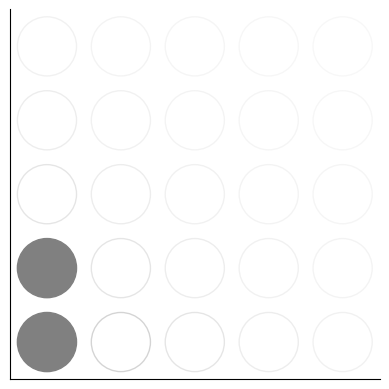

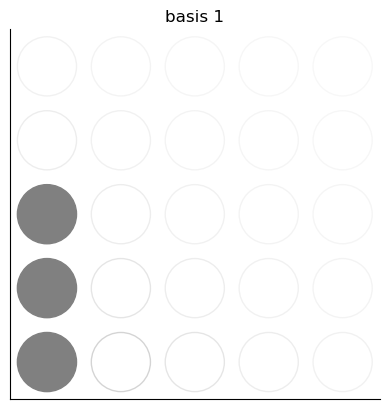

In [5]:
import numpy as np
import matplotlib.pyplot as plt

rows = 5                          # 行数
cols = 5                          # 列数
spacing = 2.0                    # 圆心间距
radius = 0.8                     # 圆的半径

# 创建画布和坐标轴
def ShowTwoExcitationPlot(ax, fill_number=2):
    ax.set_aspect('equal')           # 设置坐标轴比例相等

    # 计算起始坐标（基于中心对称）
    # start_x = -(cols-1)*spacing / 2
    # start_y = -(rows-1)*spacing / 2
    start_x = 0
    start_y = 0

    # 绘制每个圆
    for i in range(cols):
        for j in range(rows):
            x = start_x + i * spacing
            y = start_y + j * spacing
            
            if fill_number>0:
                circle = plt.Circle(
                    (x, y),
                    radius,
                    edgecolor='gray',
                    facecolor='gray',
                    fill=True
                )
                ax.add_patch(circle)
                fill_number-=1
            else:
                circle = plt.Circle(
                    (x, y),
                    radius,
                    edgecolor='gray',
                    fill=False,
                    alpha = 1/(x+y+1)
                )
                # print(x,y)
                ax.add_patch(circle)

    # 设置坐标范围和关闭坐标轴
    # plt.axis('off')
    # ax.set_xticks(ticks=[0,4,8], labels=[1,3,5])
    # ax.set_yticks(ticks=[0,4,8], labels=[1,3,5])
    ax.set_xticks(ticks=[0,4,8], labels=[])
    ax.set_yticks(ticks=[0,4,8], labels=[])
    ax.set_ylim([-1,9])
    ax.set_xlim([-1,9])
    ax.tick_params(axis='both', which='both', length=0)
    ax.spines['top'].set_visible(False)    # 隐藏顶部轴线
    ax.spines['right'].set_visible(False) # 隐藏右侧轴线
fig, ax = plt.subplots()
ShowTwoExcitationPlot(ax,2)
plt.show()
fig, ax = plt.subplots()
ShowTwoExcitationPlot(ax,3)
ax.set_title('basis 1')
plt.show()

## 线路的时间演化的

1.0
       ┌────┐ ┌─────┐┌─────┐                                                   »
 q_0: ─┤ U0 ├─┤0    ├┤0    ├───────────────────────────────────────────────────»
      ┌┴────┴┐│     ││     │                                          ┌───────┐»
 q_1: ┤ U0_d ├┤1    ├┤1    ├──────────────────────────────────────────┤0      ├»
      └┬────┬┘│     ││     │┌─────┐┌─────┐                            │       │»
 q_2: ─┤ U0 ├─┤2    ├┤2    ├┤0    ├┤0    ├────────────────────────────┤1      ├»
      ┌┴────┴┐│     ││     ││     ││     │                            │       │»
 q_3: ┤ U0_d ├┤3    ├┤3    ├┤1    ├┤1    ├────────────────────────────┤2      ├»
      └┬────┬┘│     ││     ││     ││     │┌─────┐┌─────┐              │       │»
 q_4: ─┤ U0 ├─┤4 Ux ├┤4    ├┤2    ├┤2    ├┤0    ├┤0    ├──────────────┤3      ├»
      ┌┴────┴┐│     ││  Uy ││     ││     ││     ││     │              │       │»
 q_5: ┤ U0_d ├┤5    ├┤5    ├┤3    ├┤3    ├┤1    ├┤1    ├──────────────┤4 Ux_d ├»
      └┬────┬┘│     ││  

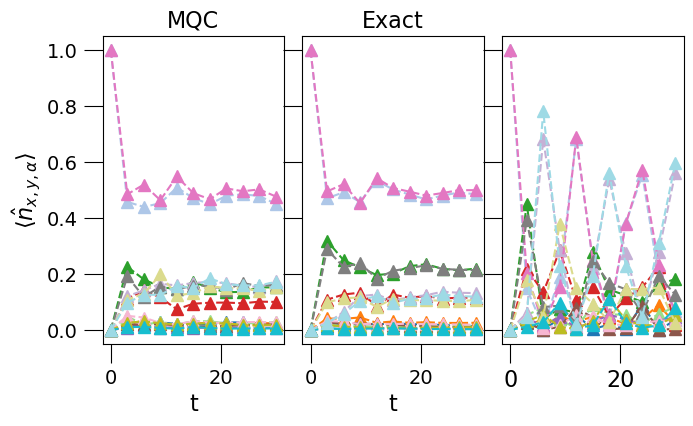

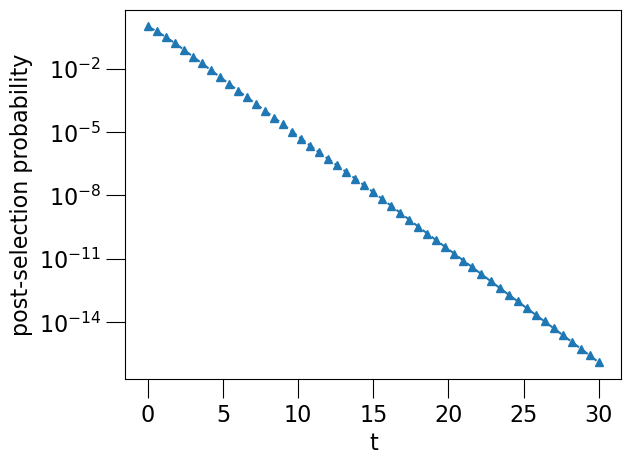

In [122]:
#colors = ['#2D8875', '#52AADC', '#7C7979', '#7FABD1', '#91ccc0', '#963B79', '#97D0C5', '#B5CE4E', '#BD7795', '#C7C1DE', '#C89736', '#D75B4E', '#EC6E66', '#EEB6D4', '#F39865', '#F7AC53']
from MeasureNonhermitianSkin.Experimental.Circuit_ManyBody import CircuitSystem
import numpy as np
import matplotlib.pyplot as plt
t_list = np.linspace(0,10,51)
num_x = 2
num_y = 4
total_particle = 2
U = 1.
init_state_record =  [1,9]

# 非厄米的结果
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ1 = ParticleConservedSystem(num_x, num_y, total_particle)
QWZ1.add_onsite_term(-1.5)
QWZ1.add_xhopping_term()
QWZ1.add_yhopping_term()
# QWZ1.add_interaction_inter(U)
QWZ1.add_NH(0.2)
ham1 = QWZ1.hamiltonian

circuit_qwz = CircuitSystem(num_x, num_y, total_particle, t_list, U=U)  # y大反而运行更快
circuit_qwz.add_HermtianCircuit()
circuit_qwz.add_interaction_inter()
circuit_qwz.nonHermitian_Circuit()
# results, result_popu, prob_list = circuit_qwz.evolve(t_list)
results, result_popu, prob_list = circuit_qwz.evolve(t_list, init_state_record=init_state_record)
fontsize = 16
labelsize=14
fig, ax = plt.subplots(1,3,figsize=(7, 4),sharex=True, sharey=True)
# for i in range(len(circuit_qwz.basis)//2):
#     ax[0].plot(t_list, results[0, i], 'o-')
#     ax[1].plot(t_list, results[1, i], 'o-')
colors = plt.cm.tab20(np.linspace(0, 1, len(result_popu[0])))
#colors = plt.cm.plasma(np.linspace(0, 1, len(result_popu[0])))
#colors = plt.cm.viridis(np.linspace(0, 1, len(result_popu[0])))
#colors = plt.cm.Greys(np.linspace(0, 1, len(result_popu[0])))
for i in range(len(result_popu[0])):
    ax[0].plot(t_list[::5], result_popu[0, i][::5], '^--', alpha=1., color=colors[i], markersize=8)
    ax[1].plot(t_list[::5], result_popu[1, i][::5], '^--', alpha=1., color=colors[i], markersize=8)
ax[0].set_title('MQC',fontsize=fontsize)
ax[0].tick_params(axis='both', which='major', labelsize=labelsize)
ax[1].set_title('Exact',fontsize=fontsize)
ax[1].tick_params(axis='both', which='major', labelsize=labelsize)
ax[0].set_xlabel('t', fontsize=fontsize)
ax[1].set_xlabel('t', fontsize=fontsize)
# ax[0].set_ylabel(r'$\langle \hat{n}_{x,y,A} + \hat{n}_{x,y,B} \rangle$', fontsize=fontsize)
ax[0].set_ylabel(r'$\langle \hat{n}_{x,y,\alpha} \rangle$', fontsize=fontsize) # 是否需要label出来？

from ComputationalPhysics.Package.BitOperation import ReadBit
evol_comp = np.zeros_like(result_popu[0])
init_label = 0
init_state = np.zeros(2**QWZ1.total_mode, dtype=np.complex128)
for idx in init_state_record:
    init_label += 1<<idx
init_state[init_label] = 1.0
initial_pick = init_state[QWZ1.basis].copy()

for i in range(len(t_list)):
    temp_state = expm(-1j*ham1*t_list[i]) @ initial_pick
    temp_state = temp_state / np.linalg.norm(temp_state)

    population = np.zeros(QWZ1.total_mode)
    for idx, state in enumerate(QWZ1.basis):
        #print(eigen_state[idx]**2, np.array([ReadBit(state, i) for i in range(self.total_mode)]))
        population += np.abs(temp_state[idx])**2 * np.array([ReadBit(state, i) for i in range(QWZ1.total_mode)])

    evol_comp[:,i] = population
for i in range(len(result_popu[0])):
    ax[2].plot(t_list[::5], evol_comp[i][::5], '^--', alpha=1., color=colors[i], markersize=8)

plt.subplots_adjust(
    left=0.12,
    right=0.95,
    bottom=0.15,
    top=0.92,
    hspace=0.1,
    wspace=0.1
)
# plt.savefig('custom_circuit.png', dpi=300, bbox_inches='tight')
# plt.savefig('DataPicture/CircuitEvolve_ManyBody.pdf') 
plt.show()
np.savez('RunCircuit_Comp_Data_Excitation%d.npz'%(len(init_state_record)), popu_NH = evol_comp, popu_NHMany=result_popu[1] , popu_NHMany_Circuit=result_popu[0], t_list= t_list, prob_list=prob_list)

plt.plot(t_list, prob_list, '^--')
plt.yscale('log')
plt.xlabel('t')
plt.ylabel('post-selection probability')
plt.show()

# 可以发现在5的时候就能看出非常大的不同。

1.0
       ┌────┐ ┌─────┐┌─────┐                                                   »
 q_0: ─┤ U0 ├─┤0    ├┤0    ├───────────────────────────────────────────────────»
      ┌┴────┴┐│     ││     │                                          ┌───────┐»
 q_1: ┤ U0_d ├┤1    ├┤1    ├──────────────────────────────────────────┤0      ├»
      └┬────┬┘│     ││     │┌─────┐┌─────┐                            │       │»
 q_2: ─┤ U0 ├─┤2    ├┤2    ├┤0    ├┤0    ├────────────────────────────┤1      ├»
      ┌┴────┴┐│     ││     ││     ││     │                            │       │»
 q_3: ┤ U0_d ├┤3    ├┤3    ├┤1    ├┤1    ├────────────────────────────┤2      ├»
      └┬────┬┘│     ││     ││     ││     │┌─────┐┌─────┐              │       │»
 q_4: ─┤ U0 ├─┤4 Ux ├┤4    ├┤2    ├┤2    ├┤0    ├┤0    ├──────────────┤3      ├»
      ┌┴────┴┐│     ││  Uy ││     ││     ││     ││     │              │       │»
 q_5: ┤ U0_d ├┤5    ├┤5    ├┤3    ├┤3    ├┤1    ├┤1    ├──────────────┤4 Ux_d ├»
      └┬────┬┘│     ││  

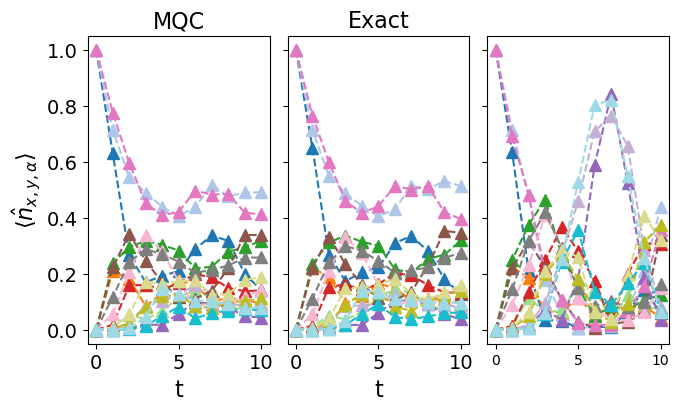

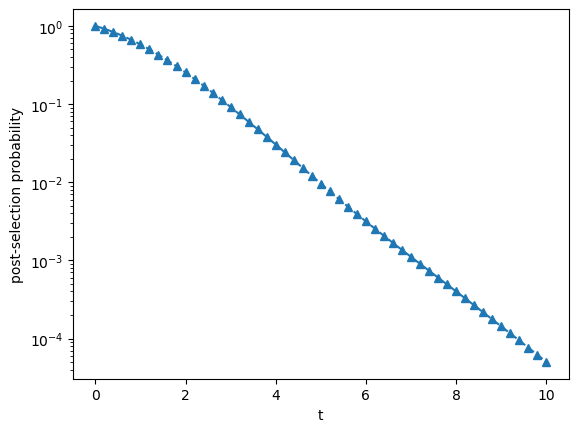

In [84]:
#colors = ['#2D8875', '#52AADC', '#7C7979', '#7FABD1', '#91ccc0', '#963B79', '#97D0C5', '#B5CE4E', '#BD7795', '#C7C1DE', '#C89736', '#D75B4E', '#EC6E66', '#EEB6D4', '#F39865', '#F7AC53']
from MeasureNonhermitianSkin.Experimental.Circuit_ManyBody import CircuitSystem
import numpy as np
import matplotlib.pyplot as plt
t_list = np.linspace(0,10,51)
num_x = 2
num_y = 4
total_particle = 3
U = 1.
init_state_record =  [0,1,9]

# 非厄米的结果
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ1 = ParticleConservedSystem(num_x, num_y, total_particle)
QWZ1.add_onsite_term(-1.5)
QWZ1.add_xhopping_term()
QWZ1.add_yhopping_term()
# QWZ1.add_interaction_inter(U)
QWZ1.add_NH(0.2)
ham1 = QWZ1.hamiltonian

circuit_qwz = CircuitSystem(num_x, num_y, total_particle, t_list, U=U)  # y大反而运行更快
circuit_qwz.add_HermtianCircuit()
circuit_qwz.add_interaction_inter()
circuit_qwz.nonHermitian_Circuit()
# results, result_popu, prob_list = circuit_qwz.evolve(t_list)
results, result_popu, prob_list = circuit_qwz.evolve(t_list, init_state_record=init_state_record)
fontsize = 16
labelsize=14
fig, ax = plt.subplots(1,3,figsize=(7, 4),sharex=True, sharey=True)
# for i in range(len(circuit_qwz.basis)//2):
#     ax[0].plot(t_list, results[0, i], 'o-')
#     ax[1].plot(t_list, results[1, i], 'o-')
colors = plt.cm.tab20(np.linspace(0, 1, len(result_popu[0])))
#colors = plt.cm.plasma(np.linspace(0, 1, len(result_popu[0])))
#colors = plt.cm.viridis(np.linspace(0, 1, len(result_popu[0])))
#colors = plt.cm.Greys(np.linspace(0, 1, len(result_popu[0])))
for i in range(len(result_popu[0])):
    ax[0].plot(t_list[::5], result_popu[0, i][::5], '^--', alpha=1., color=colors[i], markersize=8)
    ax[1].plot(t_list[::5], result_popu[1, i][::5], '^--', alpha=1., color=colors[i], markersize=8)
ax[0].set_title('MQC',fontsize=fontsize)
ax[0].tick_params(axis='both', which='major', labelsize=labelsize)
ax[1].set_title('Exact',fontsize=fontsize)
ax[1].tick_params(axis='both', which='major', labelsize=labelsize)
ax[0].set_xlabel('t', fontsize=fontsize)
ax[1].set_xlabel('t', fontsize=fontsize)
# ax[0].set_ylabel(r'$\langle \hat{n}_{x,y,A} + \hat{n}_{x,y,B} \rangle$', fontsize=fontsize)
ax[0].set_ylabel(r'$\langle \hat{n}_{x,y,\alpha} \rangle$', fontsize=fontsize) # 是否需要label出来？

from ComputationalPhysics.Package.BitOperation import ReadBit
evol_comp = np.zeros_like(result_popu[0])
init_label = 0
init_state = np.zeros(2**QWZ1.total_mode, dtype=np.complex128)
for idx in init_state_record:
    init_label += 1<<idx
init_state[init_label] = 1.0
initial_pick = init_state[QWZ1.basis].copy()

for i in range(len(t_list)):
    temp_state = expm(-1j*ham1*t_list[i]) @ initial_pick
    temp_state = temp_state / np.linalg.norm(temp_state)

    population = np.zeros(QWZ1.total_mode)
    for idx, state in enumerate(QWZ1.basis):
        #print(eigen_state[idx]**2, np.array([ReadBit(state, i) for i in range(self.total_mode)]))
        population += np.abs(temp_state[idx])**2 * np.array([ReadBit(state, i) for i in range(QWZ1.total_mode)])

    evol_comp[:,i] = population
for i in range(len(result_popu[0])):
    ax[2].plot(t_list[::5], evol_comp[i][::5], '^--', alpha=1., color=colors[i], markersize=8)

plt.subplots_adjust(
    left=0.12,
    right=0.95,
    bottom=0.15,
    top=0.92,
    hspace=0.1,
    wspace=0.1
)
# plt.savefig('custom_circuit.png', dpi=300, bbox_inches='tight')
# plt.savefig('DataPicture/CircuitEvolve_ManyBody.pdf') 
plt.show()
np.savez('RunCircuit_Comp_Data_Excitation%d.npz'%(len(init_state_record)), popu_NH = evol_comp, popu_NHMany=result_popu[1] , popu_NHMany_Circuit=result_popu[0], t_list= t_list, prob_list=prob_list)

plt.plot(t_list, prob_list, '^--')
plt.yscale('log')
plt.xlabel('t')
plt.ylabel('post-selection probability')
plt.show()

# 可以发现在5的时候就能看出非常大的不同。

X ['X', '*', '1']


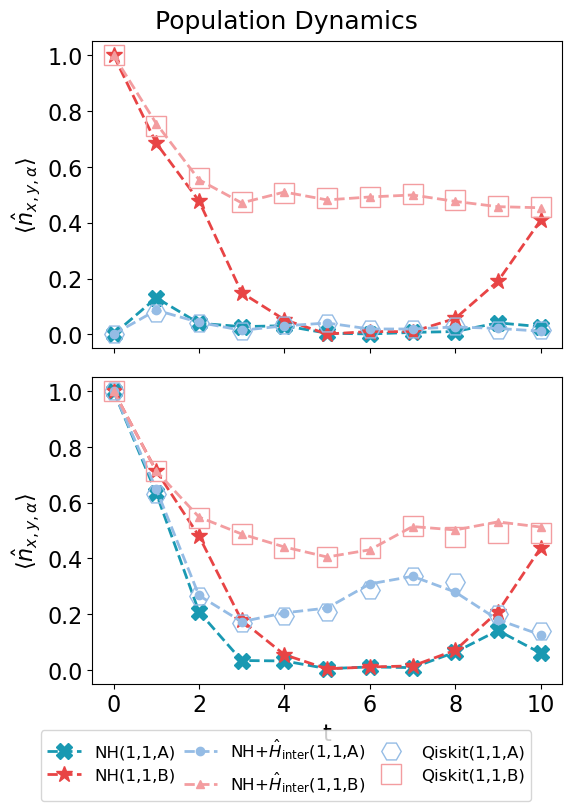

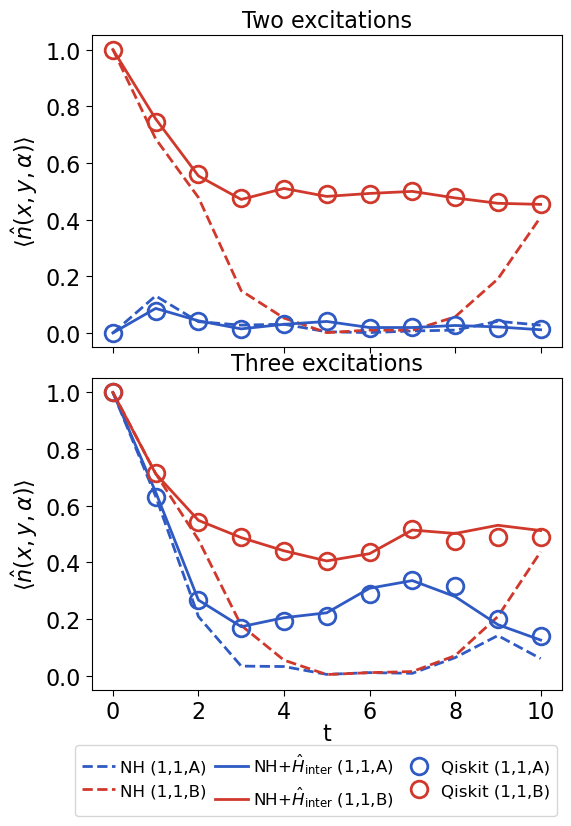

In [8]:
import numpy as np
import matplotlib.pyplot as plt
# 将上面的数据画出来
with np.load('RunCircuit_Comp_Data_Excitation2.npz') as files:
    popu_NH2 = files['popu_NH']
    popu_NHMany2 = files['popu_NHMany']
    popu_NHMany_Circuit2 = files['popu_NHMany_Circuit']
    t_list = files['t_list']
with np.load('RunCircuit_Comp_Data_Excitation3.npz') as files:
    popu_NH3 = files['popu_NH']
    popu_NHMany3 = files['popu_NHMany']
    popu_NHMany_Circuit3 = files['popu_NHMany_Circuit']
    t_list = files['t_list']

init_state_record =  [0,1]
init_label = ['(1,1,A)', '(1,1,B)']
fontsize = 16
tick_size = 14
markersize = 12
import matplotlib.pyplot as plt
# 设置全局字体大小和刻度大小
plt.rcParams.update({'font.size': 16})
fig, ax = plt.subplots(2, 1, sharex=True, sharey=True, figsize=(6, 8))
# 定义颜色和标记样式
colors = ['#2ecc71', '#e74c3c', '#3498db']
# markers = ['o', 's', 'D']
markers = [['X', '*', '1'], [ 'o', '^', 'd'], ['H', 's', 'D']]
#000000, #32183C, #36659E, #40B7AD, #A21A54, #E7724F
color_list = [['#1999B2','#E84445'],['#95BCE5','#F39DA0']]
# color_list = [['#383838', '#5CA7C7'], ['#D4352D', '#FBCE6A']]
# color_list = [['#98C897', '#9C6BA3'], ['#9DBAD2', '#FE9C9D']]

# 绘制第一条子图
# 'x', '*'
print(markers[0][0], markers[0])
for i in range(len(init_state_record)):
    ax[0].plot(t_list[::5], popu_NH2[init_state_record[i]][::5], 
               linestyle='--', linewidth=2, color=color_list[0][i],marker=markers[0][i], markersize=markersize,label='NH'+init_label[i])
    ax[1].plot(t_list[::5], popu_NH3[init_state_record[i]][::5], 
               linestyle='--', linewidth=2, color=color_list[0][i],marker=markers[0][i], markersize=markersize,label='NH'+init_label[i])

# 'o' '^'
for i in range(len(init_state_record)):
    ax[0].plot(t_list[::5], popu_NHMany2[init_state_record[i]][::5], 
               linestyle='--', linewidth=2, marker=markers[1][i], color=color_list[1][i],
               label='NH+'+r'$\hat{H}_{\mathrm{inter}}$'+init_label[i]) # marker=markers[1][i], markersize=markersize
    ax[1].plot(t_list[::5], popu_NHMany3[init_state_record[i]][::5], 
               linestyle='--', linewidth=2, color=color_list[1][i], marker=markers[1][i],
               label='NH+'+r'$\hat{H}_{\mathrm{inter}}$'+init_label[i])

# ['H', 'D']
for i in range(len(init_state_record)):
    ax[0].plot(t_list[::5], popu_NHMany_Circuit2[init_state_record[i]][::5], 
               linestyle='none', linewidth=2, color=color_list[1][i], 
               marker=markers[2][i], markersize=14, markerfacecolor='none', 
               label='Qiskit'+init_label[i])
    ax[1].plot(t_list[::5], popu_NHMany_Circuit3[init_state_record[i]][::5], 
               linestyle='none', linewidth=2, color=color_list[1][i], 
               marker=markers[2][i], markersize=14, markerfacecolor='none', 
               label='Qiskit'+init_label[i])

# 设置坐标轴标签和标题
ax[0].set_ylabel(r'$\langle \hat{n}_{x,y,\alpha}\rangle$', fontsize=16)
ax[1].set_ylabel(r'$\langle \hat{n}_{x,y,\alpha}\rangle$', fontsize=16)
ax[1].set_xlabel('t', fontsize=16)
plt.suptitle('Population Dynamics', y=0.95, fontsize=18)

# 添加图例
# ax[0].legend(fontsize=14, loc='upper right')
# ax[1].legend(fontsize=14, loc='upper right')
# 添加图例并调整位置

# 收集所有图例句柄和标签
handles = []
labels = []
# 从第一个子图中收集图例
for line in ax[0].get_lines():
    if line.get_label() not in labels:
        handles.append(line)
        labels.append(line.get_label())

# 在最下方添加一个统一的图例
fig.legend(handles, labels, 
          fontsize=12, 
          loc='lower center', 
          bbox_to_anchor=(0.5, -0.05),
          ncol=3,columnspacing=0.5)  # 你可以根据需要调整列数

# 调整子图布局
plt.tight_layout()

# 显示图形
plt.show()
fig.savefig("DataPicture/MQC_Comp.pdf", bbox_inches='tight') #




import matplotlib.pyplot as plt

# 初始化设置
init_state_record = [0, 1]
init_label = ['(1,1,A)', '(1,1,B)']
fontsize = 16
tick_size = 14
markersize = 10
linewidth = 2

# plt.rcParams.update({'font.size': fontsize})
# plt.rcParams['xtick.major.size'] = tick_size
# plt.rcParams['ytick.major.size'] = tick_size
plt.rcParams['xtick.major.size'] = 4  # 主刻度线长度
plt.rcParams['xtick.minor.size'] = 2   # 次刻度线长度
plt.rcParams['ytick.major.size'] = 4  # 主刻度线长度
plt.rcParams['ytick.minor.size'] = 2   # 次刻度线长度

fig, ax = plt.subplots(2, 1, sharex=True, sharey=True, figsize=(6, 8))

# 颜色配置：每个初始状态一个主题色
state_colors = ['#2F5AC3', '#D1382C']  # 蓝色系和红色系

# 方法样式配置：每个方法对应不同线型和标记
method_styles = {
    'NH': {'ls': '--', 'marker': '', 'label': 'NH'},          # 虚线，无标记
    'Theory': {'ls': '-', 'marker': '', 'label': r'NH+$\hat{H}_{\mathrm{inter}}$'},  # 实线，无标记
    'Experiment': {'ls': '', 'marker': 'o', 'mfc': 'none', 'label': 'Qiskit'}  # 仅空心标记
}

# 绘图循环
for i, state_idx in enumerate(init_state_record):
    # NH 数据
    ax[0].plot(t_list[::5], popu_NH2[state_idx][::5],
               color=state_colors[i],
               linestyle=method_styles['NH']['ls'],
               linewidth=linewidth,
               label=f"{method_styles['NH']['label']} {init_label[i]}")
    
    ax[1].plot(t_list[::5], popu_NH3[state_idx][::5],
               color=state_colors[i],
               linestyle=method_styles['NH']['ls'],
               linewidth=linewidth)
    
for i, state_idx in enumerate(init_state_record):
    # 理论数据 (NH+H_inter)
    ax[0].plot(t_list[::5], popu_NHMany2[state_idx][::5],
               color=state_colors[i],
               linestyle=method_styles['Theory']['ls'],
               linewidth=linewidth,
               label=f"{method_styles['Theory']['label']} {init_label[i]}")
    
    ax[1].plot(t_list[::5], popu_NHMany3[state_idx][::5],
               color=state_colors[i],
               linestyle=method_styles['Theory']['ls'],
               linewidth=linewidth)
    
for i, state_idx in enumerate(init_state_record):
    # 实验数据 (Qiskit)
    ax[0].plot(t_list[::5], popu_NHMany_Circuit2[state_idx][::5],
               color=state_colors[i],
               linestyle=method_styles['Experiment']['ls'],
               marker=method_styles['Experiment']['marker'],
               markersize=markersize+2,
               markeredgewidth=linewidth,
               markerfacecolor='none',
               linewidth=0,  # 不显示连接线
               label=f"{method_styles['Experiment']['label']} {init_label[i]}")
    
    ax[1].plot(t_list[::5], popu_NHMany_Circuit3[state_idx][::5],
               color=state_colors[i],
               linestyle=method_styles['Experiment']['ls'],
               marker=method_styles['Experiment']['marker'],
               markersize=markersize+2,
               markeredgewidth=linewidth,
               markerfacecolor='none',
               linewidth=0)

# 坐标轴设置
ax[0].set_ylabel(r'$\langle \hat{n}(x,y,\alpha)\rangle$', fontsize=fontsize)
ax[1].set_ylabel(r'$\langle \hat{n}(x,y,\alpha)\rangle$', fontsize=fontsize)
ax[1].set_xlabel('t', fontsize=fontsize, labelpad=-1)
ax[0].set_title('Two excitations', fontsize=fontsize)
ax[1].set_title('Three excitations', fontsize=fontsize)
# plt.suptitle('Population Dynamics', y=0.92, fontsize=fontsize+2)

# 智能图例配置
# handles, labels = ax[0].get_legend_handles_labels()
# legend_order = [0, 2, 4, 1, 3, 5]  # 调整条目顺序：先A后B
# ordered_handles = [handles[i] for i in legend_order]
# ordered_labels = [labels[i] for i in legend_order]
ordered_handles = []
ordered_labels = []
# 从第一个子图中收集图例
for line in ax[0].get_lines():
    if line.get_label() not in ordered_labels:
        ordered_handles.append(line)
        ordered_labels.append(line.get_label())

# 将图例放在子图之间
fig.legend(ordered_handles, ordered_labels,
           loc='upper center',
           bbox_to_anchor=(0.55, 0.04),
           ncol=3,
           columnspacing=0.5,
           handletextpad=0.3,
           fontsize=fontsize-4)

# 调整布局
plt.tight_layout(rect=[0, 0, 1, 0.98])  # 为顶部图例留出空间
plt.subplots_adjust(hspace=0.1)  # 减少子图间距

# 保存并显示
plt.show()
fig.savefig("DataPicture/MQC_Comp.pdf", bbox_inches='tight')

1.0
       ┌────┐ ┌─────┐┌─────┐                                                   »
 q_0: ─┤ U0 ├─┤0    ├┤0    ├───────────────────────────────────────────────────»
      ┌┴────┴┐│     ││     │                                          ┌───────┐»
 q_1: ┤ U0_d ├┤1    ├┤1    ├──────────────────────────────────────────┤0      ├»
      └┬────┬┘│     ││     │┌─────┐┌─────┐                            │       │»
 q_2: ─┤ U0 ├─┤2    ├┤2    ├┤0    ├┤0    ├────────────────────────────┤1      ├»
      ┌┴────┴┐│     ││     ││     ││     │                            │       │»
 q_3: ┤ U0_d ├┤3    ├┤3    ├┤1    ├┤1    ├────────────────────────────┤2      ├»
      └┬────┬┘│     ││     ││     ││     │┌─────┐┌─────┐              │       │»
 q_4: ─┤ U0 ├─┤4 Ux ├┤4    ├┤2    ├┤2    ├┤0    ├┤0    ├──────────────┤3      ├»
      ┌┴────┴┐│     ││  Uy ││     ││     ││     ││     │              │       │»
 q_5: ┤ U0_d ├┤5    ├┤5    ├┤3    ├┤3    ├┤1    ├┤1    ├──────────────┤4 Ux_d ├»
      └┬────┬┘│     ││  

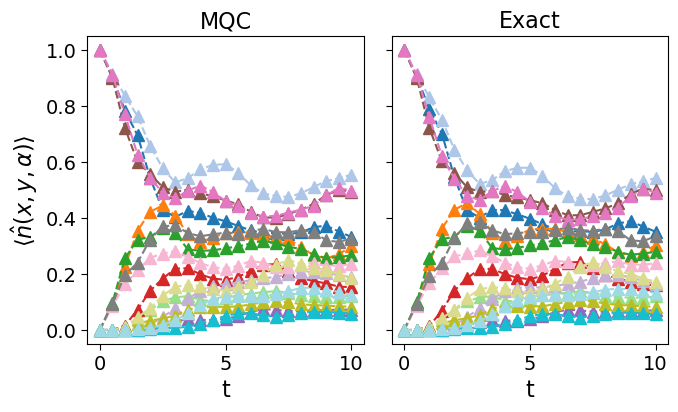

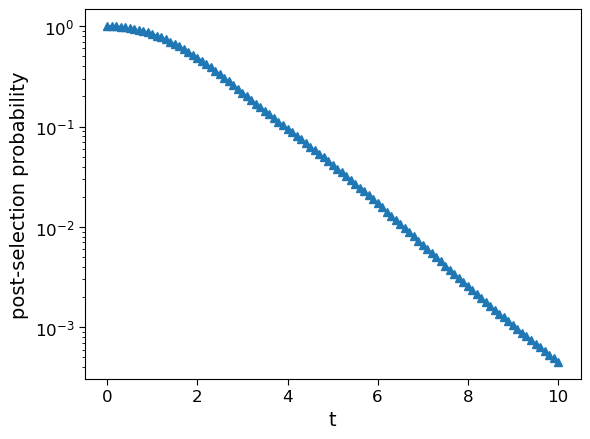

In [415]:
#colors = ['#2D8875', '#52AADC', '#7C7979', '#7FABD1', '#91ccc0', '#963B79', '#97D0C5', '#B5CE4E', '#BD7795', '#C7C1DE', '#C89736', '#D75B4E', '#EC6E66', '#EEB6D4', '#F39865', '#F7AC53']
from MeasureNonhermitianSkin.Experimental.Circuit_ManyBody import CircuitSystem
import numpy as np
import matplotlib.pyplot as plt
t_list = np.linspace(0,10,101)
circuit_qwz = CircuitSystem(2, 4, 4, t_list, U=1.)  # y大反而运行更快
circuit_qwz.add_HermtianCircuit()
circuit_qwz.add_interaction_inter()
circuit_qwz.nonHermitian_Circuit()
# results, result_popu, prob_list = circuit_qwz.evolve(t_list)
results, result_popu, prob_list = circuit_qwz.evolve(t_list,[0,1,8,9])
fontsize = 16
labelsize=14
fig, ax = plt.subplots(1,2,figsize=(7, 4),sharex=True, sharey=True)
# for i in range(len(circuit_qwz.basis)//2):
#     ax[0].plot(t_list, results[0, i], 'o-')
#     ax[1].plot(t_list, results[1, i], 'o-')
colors = plt.cm.tab20(np.linspace(0, 1, len(result_popu[0])))
#colors = plt.cm.plasma(np.linspace(0, 1, len(result_popu[0])))
#colors = plt.cm.viridis(np.linspace(0, 1, len(result_popu[0])))
#colors = plt.cm.Greys(np.linspace(0, 1, len(result_popu[0])))
for i in range(len(result_popu[0])):
    ax[0].plot(t_list[::5], result_popu[0, i][::5], '^--', alpha=1., color=colors[i], markersize=8)
    ax[1].plot(t_list[::5], result_popu[1, i][::5], '^--', alpha=1., color=colors[i], markersize=8)
ax[0].set_title('MQC',fontsize=fontsize)
ax[0].tick_params(axis='both', which='major', labelsize=labelsize)
ax[1].set_title('Exact',fontsize=fontsize)
ax[1].tick_params(axis='both', which='major', labelsize=labelsize)
ax[0].set_xlabel('t', fontsize=fontsize)
ax[1].set_xlabel('t', fontsize=fontsize)
# ax[0].set_ylabel(r'$\langle \hat{n}_{x,y,A} + \hat{n}_{x,y,B} \rangle$', fontsize=fontsize)
ax[0].set_ylabel(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize=fontsize) # 是否需要label出来？
plt.subplots_adjust(
    left=0.12,
    right=0.95,
    bottom=0.15,
    top=0.92,
    hspace=0.1,
    wspace=0.1
)
# plt.savefig('custom_circuit.png', dpi=300, bbox_inches='tight')
plt.savefig('DataPicture/SI_CircuitEvolve_4Body.pdf') 
plt.show()

plt.plot(t_list, prob_list, '^--')
plt.yscale('log')
plt.xlabel('t')
plt.ylabel('post-selection probability')
plt.show()



## 两体$\mathcal{P}$

21 98
21
21
21
number of curves 98


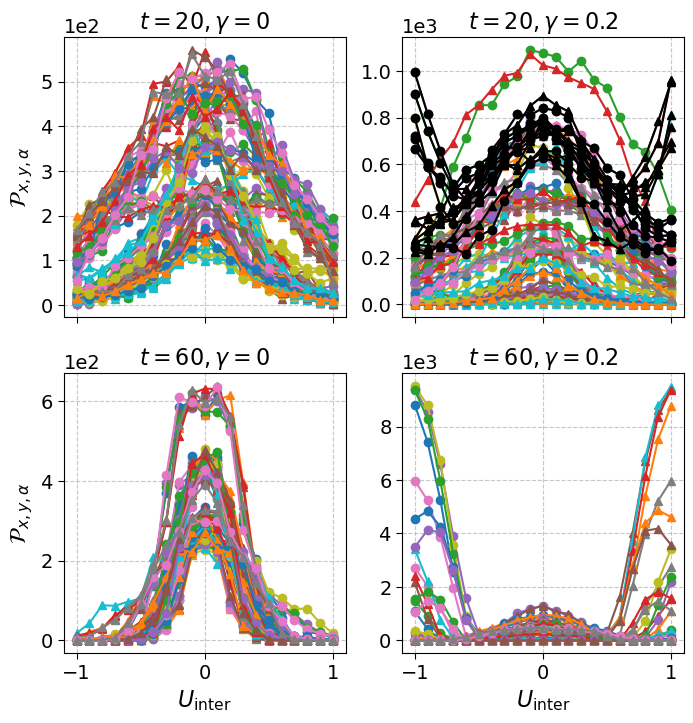

In [ ]:
with np.load('CountState_interList_gamma0.00.npz') as files:  # 从ManyBodyQWZ的CalPopu_inter_non计算得到。
    record_popu_bigger_t20_gamma0 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list), len(record_popu_bigger_t20_gamma0[0]))
with np.load('CountState_interList_gamma0.20.npz') as files:
    record_popu_bigger_t20_gamma2 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list))
with np.load('CountState_interList_gamma0.00_t60.npz') as files:
    record_popu_bigger_t60_gamma0 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list))
with np.load('CountState_interList_gamma0.20_t60.npz') as files:
    record_popu_bigger_t60_gamma2 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list))


import matplotlib.cm as cm
# 创建颜色映射
num_curves = len(record_popu_bigger_t20_gamma0[0])
colors = cm.viridis(np.linspace(0, 1, num_curves))
print('number of curves', num_curves)

fontsize = 16
labelsize = 14
fig, ax = plt.subplots(2,2,sharex=True, figsize=(8,8))

# print(len(record_popu_bigger_t20_gamma0[0]))
for i in range(0, num_curves, 2):
    ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,i], 'o-')
    ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,i], 'o-')
    ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,i], 'o-')
    ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,i], 'o-')
    ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,i+1], '^-')
    ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,i+1], '^-')
    ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,i+1], '^-')
    ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,i+1], '^-')
    # if record_popu_bigger[10,i]>500:
    #     print(i%(2*num_y),i)
# # 看是哪些比较局域。
# for i in range(0, num_curves, 14):
#     ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,i], 'ko-')
#     ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,i+1], 'k^-')
colors_r = cm.Reds(np.linspace(0.2, 0.8, num_curves))
colors_b = cm.Blues(np.linspace(0.2, 0.8, num_curves))
# A 格点用红色
# for i in range(0, num_curves, 2):
#     ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,i], 'o--', color=colors_r[i])
#     ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,i], 'o--',color=colors_r[i])
#     ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,i], 'o--',color=colors_r[i])
#     ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,i], 'o--',color=colors_r[i])
# # B格点用蓝色
# for i in range(1, num_curves, 2):
#     ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,i], '^--', color=colors_b[i])
#     ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,i], '^--',color=colors_b[i])
#     ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,i], '^--',color=colors_b[i])
#     ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,i], '^--',color=colors_b[i])
#plt.legend()
for i in range(2):
    ax[1,i].set_xlabel(r'$U_{\mathrm{inter}}$', fontsize=fontsize)
for i in range(2):
    ax[i,0].set_ylabel(r'$\mathcal{P}_{x,y,\alpha}$', fontsize=fontsize)
for row in range(2):
    for col in range(2):
        ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)

        # 调整指数部分的字体大小
        # ax[row, col].gca().get_yaxis().get_offset_text().set_fontsize(12)

        # 自定义科学计数法格式
        # formatter = ScalarFormatter(useMathText=True)
        # formatter.set_scientific(True)
        # formatter.set_powerlimits((0,0))
ax[0, 0].set_title(r'$t=20, \gamma=0$', fontsize=fontsize)
ax[0, 1].set_title(r'$t=20, \gamma=0.2$', fontsize=fontsize)
ax[1, 0].set_title(r'$t=60, \gamma=0$', fontsize=fontsize)
ax[1, 1].set_title(r'$t=60, \gamma=0.2$', fontsize=fontsize)
fig.savefig("DataPicture/SI_Popu_Interaction.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()  # 在耗散格点的增幅增大，
# plt.plot(inter_list, record_popu_bigger[:, i], 
                # marker='o', linestyle='-', 
                # color=colors[i], 
                # markersize=5, 
                # linewidth=2,
                # label=f'Curve {i+1}')
# 选取几条有特征的曲线画出来，然后做一个小的二维的，用颜色表明是在哪一个晶格进行测量。

21
21
21
21
number of curves 98
Events at U=1.0： 8779.0
Events at U=1.0： 1534.0
Events at U=1.0： 20.0


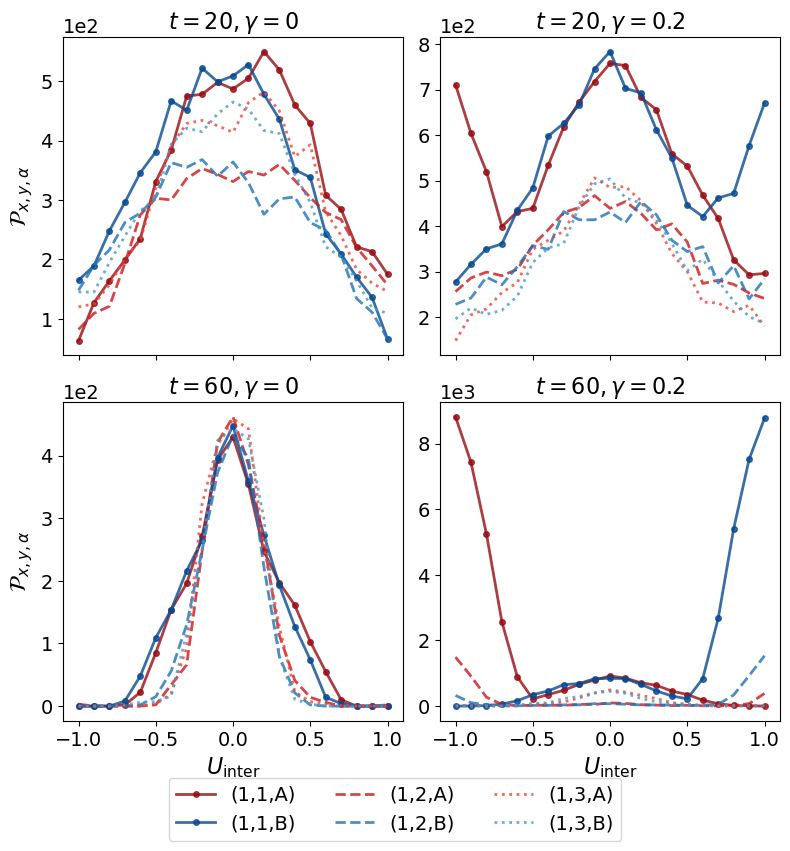

In [66]:
import numpy as np
import matplotlib.pyplot as plt
with np.load('CountState_interList_gamma0.00.npz') as files:  # 从ManyBodyQWZ的CalPopu_inter_non计算得到。
    record_popu_bigger_t20_gamma0 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list))
with np.load('CountState_interList_gamma0.20.npz') as files:
    record_popu_bigger_t20_gamma2 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list))
with np.load('CountState_interList_gamma0.00_t60.npz') as files:
    record_popu_bigger_t60_gamma0 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list))
with np.load('CountState_interList_gamma0.20_t60.npz') as files:
    record_popu_bigger_t60_gamma2 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list))


import matplotlib.cm as cm
# 创建颜色映射
num_curves = len(record_popu_bigger_t20_gamma0[0])
colors = cm.viridis(np.linspace(0, 1, num_curves))
print('number of curves', num_curves)

color_light = cm.Blues_r(np.linspace(0.1, 0.4, 3))# ['#C2DACF', '#C2DCE9', '#EAE1EF', '#F8F3EB']
# color_light = ['#85C3DC', '#8DAFAB', '#DAC6CF', '#E2C098']
color_deep = cm.Reds_r(np.linspace(0.1, 0.4, 3))# ['#383838', '#5CA7C7', '#D4352D', '#FBCE6A']

fontsize = 16
labelsize = 14
linewidth = 2
alpha = 0.8
marker_size = 8
A_lineshape = 'H--'
B_lineshape = '^--'
# A_lineshape = '--'
# B_lineshape = '--'
A_lineshape = ['.-', '--', ':']
B_lineshape = ['.-', '--', ':']
fig, ax = plt.subplots(2,2,sharex=True, figsize=(8,8))

# print(len(record_popu_bigger_t20_gamma0[0]))
for i in range(3):
    ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,2*i], A_lineshape[i], lw=linewidth, alpha=alpha, color=color_deep[i], label='(1,%d,A)'%(i+1), markersize=marker_size)
    ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,2*i], A_lineshape[i],lw=linewidth, alpha=alpha, color=color_deep[i], markersize=marker_size)
    ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,2*i], A_lineshape[i],lw=linewidth, alpha=alpha, color=color_deep[i], markersize=marker_size)
    ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,2*i], A_lineshape[i],lw=linewidth, alpha=alpha, color=color_deep[i], markersize=marker_size)
    ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,2*i+1], B_lineshape[i],lw=linewidth, alpha=alpha, color=color_light[i], label='(1,%d,B)'%(i+1), markersize=marker_size)
    ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,2*i+1], B_lineshape[i],lw=linewidth, alpha=alpha, color=color_light[i], markersize=marker_size)
    ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,2*i+1], B_lineshape[i],lw=linewidth, alpha=alpha, color=color_light[i], markersize=marker_size)
    ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,2*i+1], B_lineshape[i],lw=linewidth, alpha=alpha, color=color_light[i], markersize=marker_size)
    print('Events at U=1.0：', record_popu_bigger_t60_gamma2[-1,2*i+1])
    # if record_popu_bigger[10,i]>500:
    #     print(i%(2*num_y),i)
colors_r = cm.Reds(np.linspace(0.2, 0.8, num_curves))
colors_b = cm.Blues(np.linspace(0.2, 0.8, num_curves))
# A 格点用红色
# for i in range(0, num_curves, 2):
#     ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,i], 'o--', color=colors_r[i])
#     ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,i], 'o--',color=colors_r[i])
#     ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,i], 'o--',color=colors_r[i])
#     ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,i], 'o--',color=colors_r[i])
# # B格点用蓝色
# for i in range(1, num_curves, 2):
#     ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,i], '^--', color=colors_b[i])
#     ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,i], '^--',color=colors_b[i])
#     ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,i], '^--',color=colors_b[i])
#     ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,i], '^--',color=colors_b[i])
#plt.legend()
for i in range(2):
    ax[1,i].set_xlabel(r'$U_{\mathrm{inter}}$', fontsize=fontsize)
for i in range(2):
    ax[i,0].set_ylabel(r'$\mathcal{P}_{x,y,\alpha}$', fontsize=fontsize)
for row in range(2):
    for col in range(2):
        #ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)

        # 调整指数部分的字体大小
        # ax[row, col].gca().get_yaxis().get_offset_text().set_fontsize(12)

        # 自定义科学计数法格式
        # formatter = ScalarFormatter(useMathText=True)
        # formatter.set_scientific(True)
        # formatter.set_powerlimits((0,0))
ax[0, 0].set_title(r'$t=20, \gamma=0$', fontsize=fontsize)
ax[0, 1].set_title(r'$t=20, \gamma=0.2$', fontsize=fontsize)
ax[1, 0].set_title(r'$t=60, \gamma=0$', fontsize=fontsize)
ax[1, 1].set_title(r'$t=60, \gamma=0.2$', fontsize=fontsize)

# 从axs[0,0]获取句柄和标签
handles, labels = ax[0,0].get_legend_handles_labels()

# 在Figure下方添加整体图例
legend = fig.legend(handles, labels, 
           loc='lower center',   # 定位到下方
           bbox_to_anchor=(0.5, -0.07),  # 调整位置
           ncol=3, fontsize=labelsize)  # 分两列排列
# # 在Figure下方添加整体图例
# legend = fig.legend(handles, labels, 
#            loc='lower center',   # 定位到下方
#            bbox_to_anchor=(0.75, 0.23),  # 调整位置
#            ncol=1, fontsize=labelsize)  # 分两列排列

# 调整子图布局，留出底部空间
fig.subplots_adjust(bottom=0.03)
# 调整布局
plt.tight_layout()

# plt.savefig('DataPicture/Popu_Interaction.pdf') 
fig.savefig("DataPicture/Popu_Interaction.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()  # 在耗散格点的增幅增大，
# plt.plot(inter_list, record_popu_bigger[:, i], 
                # marker='o', linestyle='-', 
                # color=colors[i], 
                # markersize=5, 
                # linewidth=2,
                # label=f'Curve {i+1}')
# 选取几条有特征的曲线画出来，然后做一个小的二维的，用颜色表明是在哪一个晶格进行测量。

21 32
21
21
21
number of curves 32


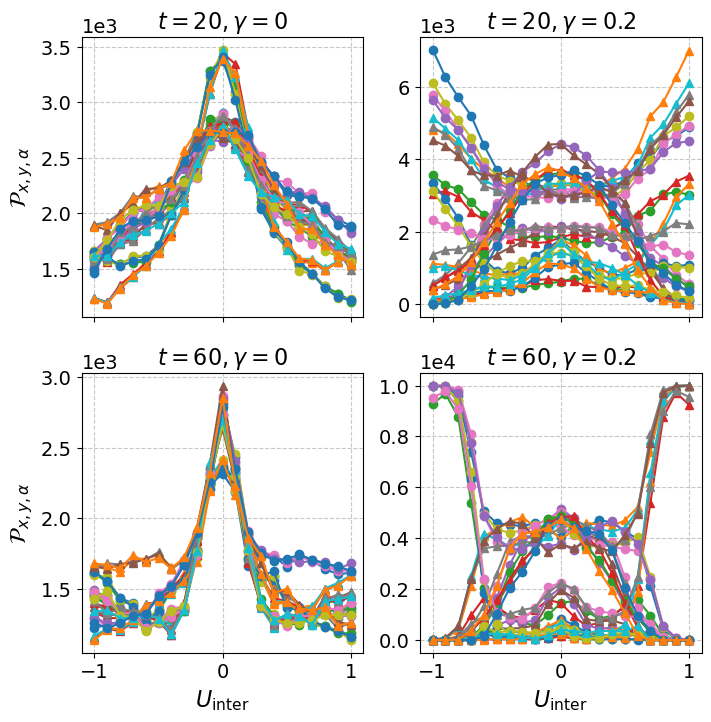

In [3]:
with np.load('ThreeExcitation_CountState_interList_gamma0.00_t20_inter.npz') as files:  # 从ManyBodyQWZ的CalPopu_inter_non计算得到。
    record_popu_bigger_t20_gamma0 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list), len(record_popu_bigger_t20_gamma0[0]))
with np.load('ThreeExcitation_CountState_interList_gamma0.20_t20_inter.npz') as files:
    record_popu_bigger_t20_gamma2 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list))
with np.load('ThreeExcitation_CountState_interList_gamma0.00_t60_inter.npz') as files:
    record_popu_bigger_t60_gamma0 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list))
with np.load('ThreeExcitation_CountState_interList_gamma0.20_t60_inter.npz') as files:
    record_popu_bigger_t60_gamma2 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list))


import matplotlib.cm as cm
# 创建颜色映射
num_curves = len(record_popu_bigger_t20_gamma0[0])
colors = cm.viridis(np.linspace(0, 1, num_curves))
print('number of curves', num_curves)

fontsize = 16
labelsize = 14
fig, ax = plt.subplots(2,2,sharex=True, figsize=(8,8))

# print(len(record_popu_bigger_t20_gamma0[0]))
for i in range(0, num_curves, 2):
    ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,i], 'o-')
    ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,i], 'o-')
    ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,i], 'o-')
    ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,i], 'o-')
    ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,i+1], '^-')
    ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,i+1], '^-')
    ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,i+1], '^-')
    ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,i+1], '^-')
    # if record_popu_bigger[10,i]>500:
    #     print(i%(2*num_y),i)
colors_r = cm.Reds(np.linspace(0.2, 0.8, num_curves))
colors_b = cm.Blues(np.linspace(0.2, 0.8, num_curves))
# A 格点用红色
# for i in range(0, num_curves, 2):
#     ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,i], 'o--', color=colors_r[i])
#     ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,i], 'o--',color=colors_r[i])
#     ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,i], 'o--',color=colors_r[i])
#     ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,i], 'o--',color=colors_r[i])
# # B格点用蓝色
# for i in range(1, num_curves, 2):
#     ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,i], '^--', color=colors_b[i])
#     ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,i], '^--',color=colors_b[i])
#     ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,i], '^--',color=colors_b[i])
#     ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,i], '^--',color=colors_b[i])
#plt.legend()
for i in range(2):
    ax[1,i].set_xlabel(r'$U_{\mathrm{inter}}$', fontsize=fontsize)
for i in range(2):
    ax[i,0].set_ylabel(r'$\mathcal{P}_{x,y,\alpha}$', fontsize=fontsize)
for row in range(2):
    for col in range(2):
        ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)

        # 调整指数部分的字体大小
        # ax[row, col].gca().get_yaxis().get_offset_text().set_fontsize(12)

        # 自定义科学计数法格式
        # formatter = ScalarFormatter(useMathText=True)
        # formatter.set_scientific(True)
        # formatter.set_powerlimits((0,0))
ax[0, 0].set_title(r'$t=20, \gamma=0$', fontsize=fontsize)
ax[0, 1].set_title(r'$t=20, \gamma=0.2$', fontsize=fontsize)
ax[1, 0].set_title(r'$t=60, \gamma=0$', fontsize=fontsize)
ax[1, 1].set_title(r'$t=60, \gamma=0.2$', fontsize=fontsize)
fig.savefig("DataPicture/SI_Popu_Interaction.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()  # 在耗散格点的增幅增大，
# plt.plot(inter_list, record_popu_bigger[:, i], 
                # marker='o', linestyle='-', 
                # color=colors[i], 
                # markersize=5, 
                # linewidth=2,
                # label=f'Curve {i+1}')
# 选取几条有特征的曲线画出来，然后做一个小的二维的，用颜色表明是在哪一个晶格进行测量。

21 32
21
21
21
number of curves 32
Events at U=1.0： 9990.0
Events at U=1.0： 9248.0
Events at U=1.0： 0.0


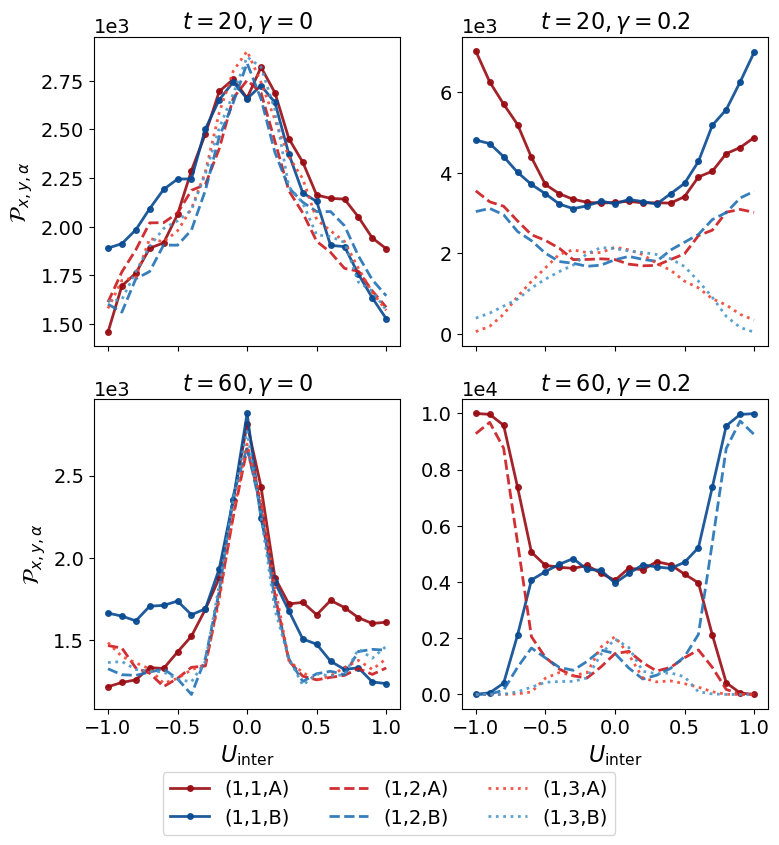

In [412]:
with np.load('ThreeExcitation_CountState_interList_gamma0.00_t20_inter.npz') as files:  # 从ManyBodyQWZ的CalPopu_inter_non计算得到。
    record_popu_bigger_t20_gamma0 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list), len(record_popu_bigger_t20_gamma0[0]))
with np.load('ThreeExcitation_CountState_interList_gamma0.20_t20_inter.npz') as files:
    record_popu_bigger_t20_gamma2 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list))
with np.load('ThreeExcitation_CountState_interList_gamma0.00_t60_inter.npz') as files:
    record_popu_bigger_t60_gamma0 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list))
with np.load('ThreeExcitation_CountState_interList_gamma0.20_t60_inter.npz') as files:
    record_popu_bigger_t60_gamma2 = files['record_popu_bigger']
    inter_list = files['inter_list']
    print(len(inter_list))


import matplotlib.cm as cm
# 创建颜色映射
num_curves = len(record_popu_bigger_t20_gamma0[0])
colors = cm.viridis(np.linspace(0, 1, num_curves))
print('number of curves', num_curves)

color_light = cm.Blues_r(np.linspace(0.1, 0.4, 3))# ['#C2DACF', '#C2DCE9', '#EAE1EF', '#F8F3EB']
# color_light = ['#85C3DC', '#8DAFAB', '#DAC6CF', '#E2C098']
color_deep = cm.Reds_r(np.linspace(0.1, 0.4, 3))# ['#383838', '#5CA7C7', '#D4352D', '#FBCE6A']

fontsize = 16
labelsize = 14
linewidth = 2
alpha = 0.9
marker_size = 8
A_lineshape = 'H--'
B_lineshape = '^--'
A_lineshape = ['.-', '--', ':']
B_lineshape = ['.-', '--', ':']
fig, ax = plt.subplots(2,2,sharex=True, figsize=(8,8))

# print(len(record_popu_bigger_t20_gamma0[0]))
for i in range(3):
    ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,2*i], A_lineshape[i], lw=linewidth, alpha=alpha, color=color_deep[i], label='(1,%d,A)'%(i+1), markersize=marker_size)
    ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,2*i], A_lineshape[i],lw=linewidth, alpha=alpha, color=color_deep[i], markersize=marker_size)
    ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,2*i], A_lineshape[i],lw=linewidth, alpha=alpha, color=color_deep[i], markersize=marker_size)
    ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,2*i], A_lineshape[i],lw=linewidth, alpha=alpha, color=color_deep[i], markersize=marker_size)
    ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,2*i+1], B_lineshape[i],lw=linewidth, alpha=alpha, color=color_light[i], label='(1,%d,B)'%(i+1), markersize=marker_size)
    ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,2*i+1], B_lineshape[i],lw=linewidth, alpha=alpha, color=color_light[i], markersize=marker_size)
    ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,2*i+1], B_lineshape[i],lw=linewidth, alpha=alpha, color=color_light[i], markersize=marker_size)
    ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,2*i+1], B_lineshape[i],lw=linewidth, alpha=alpha, color=color_light[i], markersize=marker_size)
    print('Events at U=1.0：', record_popu_bigger_t60_gamma2[-1,2*i+1])
    # if record_popu_bigger[10,i]>500:
    #     print(i%(2*num_y),i)
colors_r = cm.Reds(np.linspace(0.2, 0.8, num_curves))
colors_b = cm.Blues(np.linspace(0.2, 0.8, num_curves))
# A 格点用红色
# for i in range(0, num_curves, 2):
#     ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,i], 'o--', color=colors_r[i])
#     ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,i], 'o--',color=colors_r[i])
#     ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,i], 'o--',color=colors_r[i])
#     ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,i], 'o--',color=colors_r[i])
# # B格点用蓝色
# for i in range(1, num_curves, 2):
#     ax[0, 0].plot(inter_list, record_popu_bigger_t20_gamma0[:,i], '^--', color=colors_b[i])
#     ax[0, 1].plot(inter_list, record_popu_bigger_t20_gamma2[:,i], '^--',color=colors_b[i])
#     ax[1, 0].plot(inter_list, record_popu_bigger_t60_gamma0[:,i], '^--',color=colors_b[i])
#     ax[1, 1].plot(inter_list, record_popu_bigger_t60_gamma2[:,i], '^--',color=colors_b[i])
#plt.legend()
for i in range(2):
    ax[1,i].set_xlabel(r'$U_{\mathrm{inter}}$', fontsize=fontsize)
for i in range(2):
    ax[i,0].set_ylabel(r'$\mathcal{P}_{x,y,\alpha}$', fontsize=fontsize)
for row in range(2):
    for col in range(2):
        # ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)

        # 调整指数部分的字体大小
        # ax[row, col].gca().get_yaxis().get_offset_text().set_fontsize(12)

        # 自定义科学计数法格式
        # formatter = ScalarFormatter(useMathText=True)
        # formatter.set_scientific(True)
        # formatter.set_powerlimits((0,0))
ax[0, 0].set_title(r'$t=20, \gamma=0$', fontsize=fontsize)
ax[0, 1].set_title(r'$t=20, \gamma=0.2$', fontsize=fontsize)
ax[1, 0].set_title(r'$t=60, \gamma=0$', fontsize=fontsize)
ax[1, 1].set_title(r'$t=60, \gamma=0.2$', fontsize=fontsize)

# 从axs[0,0]获取句柄和标签
handles, labels = ax[0,0].get_legend_handles_labels()

# 在Figure下方添加整体图例
legend = fig.legend(handles, labels, 
           loc='lower center',   # 定位到下方
           bbox_to_anchor=(0.5, -0.07),  # 调整位置
           ncol=3, fontsize=labelsize)  # 分两列排列

# 调整子图布局，留出底部空间
fig.subplots_adjust(bottom=0.03)
# 调整布局
plt.tight_layout()

# plt.savefig('DataPicture/Popu_Interaction.pdf') 
fig.savefig("DataPicture/ThreeExcitation_Popu_Interaction.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()  # 在耗散格点的增幅增大，
# plt.plot(inter_list, record_popu_bigger[:, i], 
                # marker='o', linestyle='-', 
                # color=colors[i], 
                # markersize=5, 
                # linewidth=2,
                # label=f'Curve {i+1}')
# 选取几条有特征的曲线画出来，然后做一个小的二维的，用颜色表明是在哪一个晶格进行测量。

## 双激发本征能谱

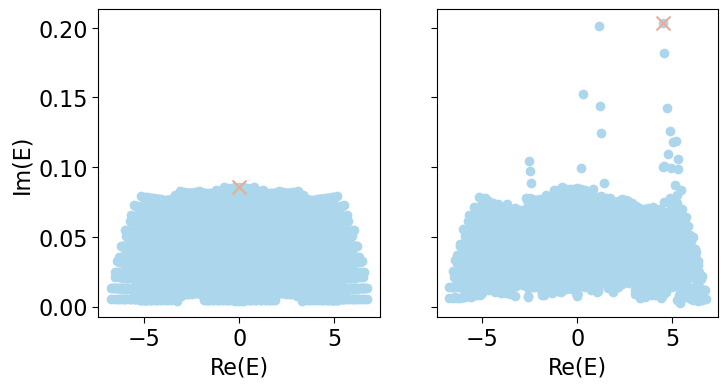

172 0b10000000000000000010
1
19
[1, 2]
213 0b1000000000000000001000
3
21
[1, 2]
685 0b10000000000000000010000000000000000000
19
37
[2, 3]
1522 0b10000000000000000010000000000000000000000000000000000000
37
55
[3, 4]
2683 0b10000000000000000010000000000000000000000000000000000000000000000000000000
55
73
[4, 5]
4168 0b10000000000000000010000000000000000000000000000000000000000000000000000000000000000000000000
73
91
[5, 6]
5977 0b10000000000000000010000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000
91
109
[6, 7]
8110 0b10000000000000000010000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000
109
127
[7, 8]
10567 0b10000000000000000010000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000
127
145
[8, 9]


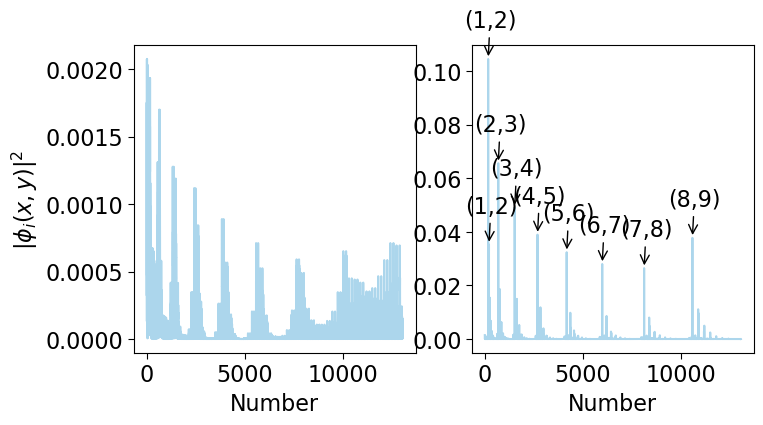

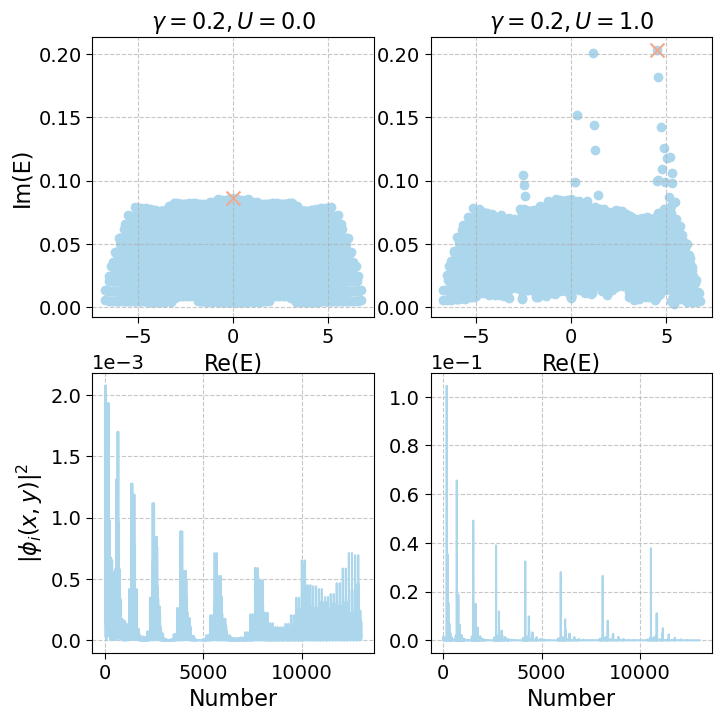

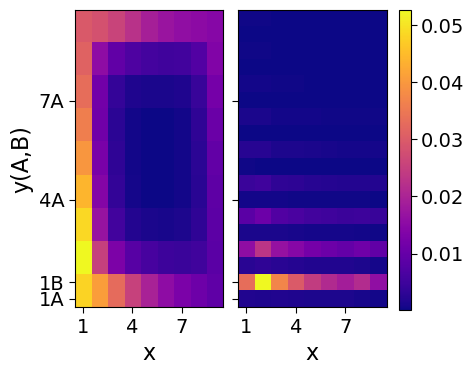

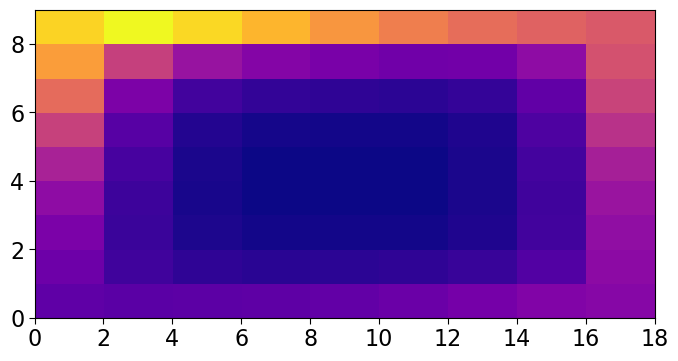

In [29]:
# 两体的本征能谱。
# np.savez('ThreeExcitationEig%d.npz'%num_x, eigval_NH=eigval, eigval_NHMany=eigval2, eigvec_NH=eigvec, eigvec_NHMany=eigvec2)

# color_r = '#B22222'
# color_b = '#000080'
import numpy as np
import matplotlib.pyplot as plt
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
num_x = 9
num_y = 9
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
popu_indice = QWZ2.Calcu_Occup()
basis = QWZ2.basis

color_r = '#F5A889'
color_b = '#ACD6EC'
with np.load('TwoExcitationEig9.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']

fontsize = 14
fig, ax = plt.subplots(1,2,figsize=(8, 4),sharex=True, sharey=True)
ax[0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0].scatter(eigval_NH[-1].real, eigval_NH[-1].imag, color=color_r, s=100, marker='x')
ax[1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[1].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0].set_xlabel('Re(E)')
ax[1].set_xlabel('Re(E)')
ax[0].set_ylabel('Im(E)')
plt.show()

fig, ax = plt.subplots(1,2,figsize=(8, 4))
ax[0].plot(np.abs(eigvec_NH[:,-1])**2, color=color_b)
ax[1].plot(np.abs(eigvec_NHMany[:,-1])**2, color=color_b)
ax[0].set_xlabel('Number')
ax[1].set_xlabel('Number')
ax[0].set_ylabel(r'$\vert \phi_i(x,y)\vert^2$')

from ComputationalPhysics.Package.BitOperation import ReadBit
threshold = 0.02
for i in range(len(eigvec_NH[:,-1])):
    if np.abs(eigvec_NHMany[i,-1])**2>threshold:
        print(i, bin(basis[i]))
        loc = []
        for j in range(2*9*9):
            if ReadBit(basis[i], j)==1:
                print(j)
                loc.append(j//(2*num_y)+1)
        print(loc)
        ax[1].annotate(
                '(%d,%d)'%(loc[0], loc[1]),
                xy=(i, np.abs(eigvec_NHMany[i,-1])**2),  # 箭头指向的位置
                xytext=(i+100, np.abs(eigvec_NHMany[i,-1])**2+0.01),  # 文本的位置
                arrowprops=dict(facecolor='black', arrowstyle='->'),  # 箭头样式
                ha='center',
                va='bottom'
            )
plt.show()


fontsize = 16
labelsize= 14
fig, ax = plt.subplots(2,2,figsize=(8, 8), sharex='row')
ax[0,1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[-1].real, eigval_NH[-1].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)

ax[1, 0].plot(np.abs(eigvec_NH[:,-1])**2, color=color_b)
ax[1, 1].plot(np.abs(eigvec_NHMany[:,-1])**2, color=color_b)


ax[1, 0].set_xlabel('Number',fontsize=fontsize)
ax[1, 1].set_xlabel('Number',fontsize=fontsize)
ax[1, 0].set_ylabel(r'$\vert \phi_i(x,y)\vert^2$',fontsize=fontsize)
for row in range(2):
    for col in range(2):
        ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
for col in range(2):
    ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = ax[row, col].get_yaxis().get_offset_text()
    # 设置字体大小为12
    offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=0.2, U=0.0$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=0.2, U=1.0$', fontsize=fontsize)
fig.savefig("DataPicture/TwoExcitationSpectrum.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()

color_string = 'plasma' # Reds.
labelsize = 14
num_x, num_y = 9, 9
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
popu_indice = QWZ2.Calcu_Occup()
basis = QWZ2.basis
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k],-1])**2) 
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 


fig, ax = plt.subplots(1,2,figsize=(4, 4), sharex=True,sharey=True)
sm = ax[0].imshow(popu_NH.reshape(num_x, 2*num_y).T, cmap=color_string, origin='lower')
ax[1].imshow(popu_NHMany.reshape(num_x, 2*num_y).T, cmap=color_string,origin='lower')
ax[0].set_xlabel('x', fontsize=fontsize)
ax[1].set_xlabel('x', fontsize=fontsize)
ax[0].set_ylabel('y(A,B)', fontsize=fontsize)
ax[0].tick_params(axis='both', which='major', labelsize=labelsize)
ax[1].tick_params(axis='both', which='major', labelsize=labelsize)
ax[0].set_yticks(ticks=[0,1,6,12], labels=['1A','1B','4A','7A'])
ax[1].set_yticks(ticks=[0,1,6,12], labels=['1A','1B','4A','7A'])
ax[0].set_xticks(ticks=[0,3,6], labels=[1,4,7])
ax[1].set_xticks(ticks=[0,3,6], labels=[1,4,7])

plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.12,
    top=0.92,
    hspace=0.1,
    wspace=0.1
)
cax = fig.add_axes([0.93, 0.14, 0.03, 0.75]) # [左，下，宽，高]
cbar = plt.colorbar(
    sm,
    cax=cax,
    orientation="vertical"
)
cax.tick_params(axis='both', which='major', labelsize=labelsize)
fig.savefig("DataPicture/TwoExcitation_Eigen.pdf", bbox_inches='tight') # , 
plt.show()


from scipy import ndimage
n_map1 = popu_NH.reshape(num_x, 2*num_y).T
# 旋转90度
rotated_data = ndimage.rotate(n_map1, angle=90, reshape=True)
# 计算旋转后的坐标范围
original_shape = n_map1.shape
rotated_shape = rotated_data.shape
extent = [0, rotated_shape[1], 0, rotated_shape[0]]

plt.figure(figsize=(8,4))
plt.imshow(rotated_data, 
          extent=extent,
          aspect='auto',
          origin='lower',
          cmap='plasma')
plt.show()

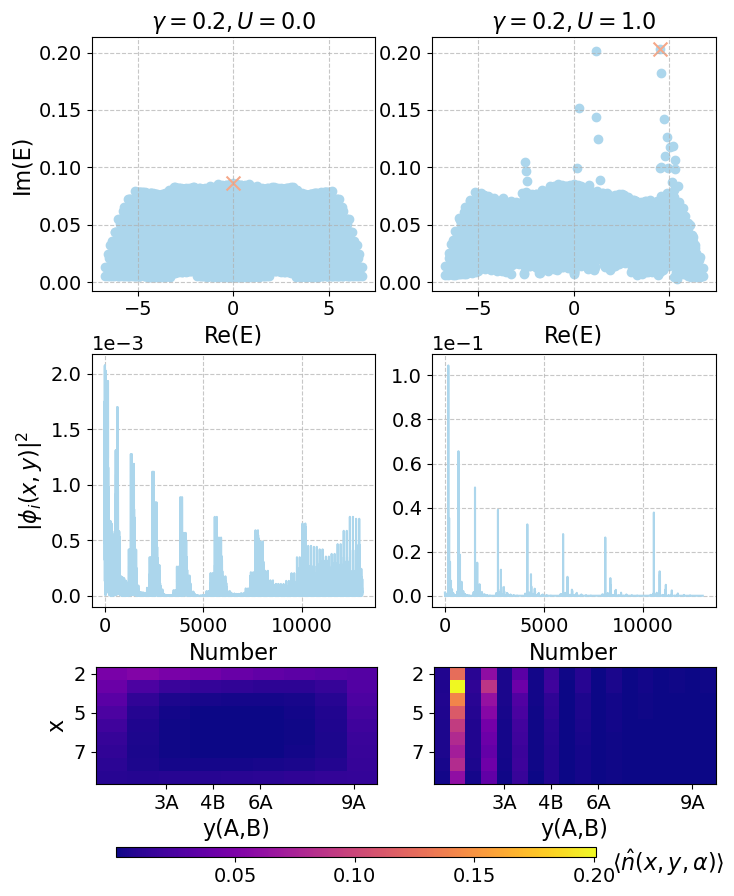

In [39]:
import numpy as np
import matplotlib.pyplot as plt
color_r = '#F5A889'
color_b = '#ACD6EC'
with np.load('TwoExcitationEig9.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']

fontsize = 16
labelsize= 14
fig, ax = plt.subplots(2,2,figsize=(8, 10), sharex='row')
ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[-1].real, eigval_NH[-1].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)

ax[1, 0].plot(np.abs(eigvec_NH[:,-1])**2, color=color_b)
ax[1, 1].plot(np.abs(eigvec_NHMany[:,-1])**2, color=color_b)
ax[1, 0].set_xlabel('Number',fontsize=fontsize)
ax[1, 1].set_xlabel('Number',fontsize=fontsize)
ax[1, 0].set_ylabel(r'$\vert \phi_i(x,y)\vert^2$',fontsize=fontsize)
for row in range(2):
    for col in range(2):
        ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
for col in range(2):
    ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = ax[row, col].get_yaxis().get_offset_text()
    # 设置字体大小为12
    offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=0.2, U=0.0$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=0.2, U=1.0$', fontsize=fontsize)

from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
num_x, num_y = 9, 9
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
popu_indice = QWZ2.Calcu_Occup()
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k],-1])**2) 
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 

from scipy import ndimage
n_map1 = popu_NH.reshape(num_x, 2*num_y).T
# 旋转90度
rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
# 计算旋转后的坐标范围
n_map2 = popu_NHMany.reshape(num_x, 2*num_y).T
# 旋转90度
rotated_data2 = ndimage.rotate(n_map2, angle=90, reshape=True)
# 计算旋转后的坐标范围
color_string = 'plasma'
pos1 = ax[1, 0].get_position()
pos2 = ax[1, 1].get_position()
plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.35,
    top=0.92,
    hspace=0.25,
    wspace=0.2
)
gap = -0.18
ax3 = fig.add_axes([pos1.x0, pos1.y0 - gap - pos1.height/3, pos1.width, pos1.height/3])
ax4 = fig.add_axes([pos2.x0, pos2.y0 - gap - pos1.height/3, pos2.width, pos1.height/3])
vmin, vmax = np.min([np.min(popu_NH), np.min(popu_NHMany)]), np.max([np.max(popu_NH), np.max(popu_NHMany)]) # 但是这样颜色会看不出来。
sm  = ax3.imshow(rotated_data1, 
          aspect='auto',
          origin='lower',
          vmin=vmin,vmax=vmax,
          cmap=color_string)
ax4.imshow(rotated_data2, 
          aspect='auto',
          origin='lower',
          vmin=vmin,vmax=vmax,
          cmap=color_string)
ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax4.set_xlabel('y(A,B)', fontsize=fontsize)
ax3.set_ylabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
ax3.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
ax4.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
ax3.set_yticks(ticks=[2,5,8], labels=[7,5,2])
ax4.set_yticks(ticks=[2,5,8], labels=[7,5,2])

cax = fig.add_axes([0.15, 0.1, 0.6, 0.01]) # [左，下，宽，高]
cbar = plt.colorbar(
    sm,
    cax=cax,
    orientation='horizontal'
)
cax.tick_params(axis='both', which='major', labelsize=labelsize)
# cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
cax.text(cax.get_xlim()[-1]+0.007, cax.get_ylim()[-1], r'$\langle \hat{n}(x,y,\alpha) \rangle$', va='top', ha='left', fontsize=fontsize)
fig.savefig("DataPicture/TwoExcitationSpectrum.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()

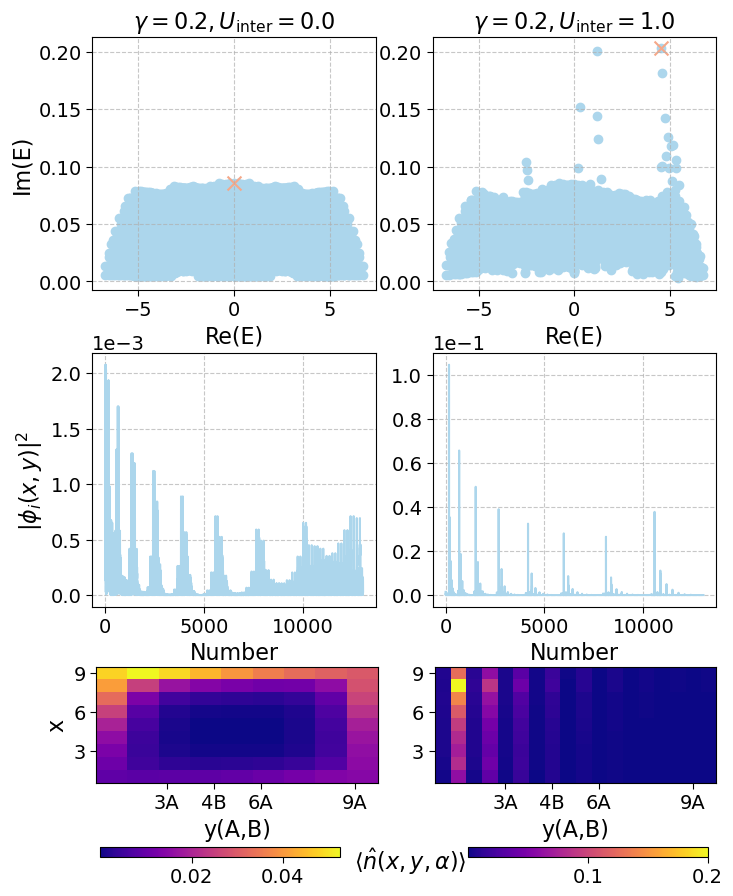

In [265]:
import numpy as np
import matplotlib.pyplot as plt
color_r = '#F5A889'
color_b = '#ACD6EC'
with np.load('TwoExcitationEig9.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']

fontsize = 16
labelsize= 14
fig, ax = plt.subplots(2,2,figsize=(8, 10), sharex='row')
ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[-1].real, eigval_NH[-1].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)

ax[1, 0].plot(np.abs(eigvec_NH[:,-1])**2, color=color_b)
ax[1, 1].plot(np.abs(eigvec_NHMany[:,-1])**2, color=color_b)
ax[1, 0].set_xlabel('Number',fontsize=fontsize)
ax[1, 1].set_xlabel('Number',fontsize=fontsize)
ax[1, 0].set_ylabel(r'$\vert \phi_i(x,y)\vert^2$',fontsize=fontsize)
for row in range(2):
    for col in range(2):
        ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
for col in range(2):
    ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = ax[row, col].get_yaxis().get_offset_text()
    # 设置字体大小为12
    offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=0.0$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=1.0$', fontsize=fontsize)
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
num_x, num_y = 9, 9
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
popu_indice = QWZ2.Calcu_Occup()
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k],-1])**2) 
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 

from scipy import ndimage
n_map1 = popu_NH.reshape(num_x, 2*num_y).T
# 旋转90度
rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
# 计算旋转后的坐标范围
n_map2 = popu_NHMany.reshape(num_x, 2*num_y).T
# 旋转90度
rotated_data2 = ndimage.rotate(n_map2, angle=90, reshape=True)
# 计算旋转后的坐标范围
color_string = 'plasma'
pos1 = ax[1, 0].get_position()
pos2 = ax[1, 1].get_position()
plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.35,
    top=0.92,
    hspace=0.25,
    wspace=0.2
)
gap = -0.18
ax3 = fig.add_axes([pos1.x0, pos1.y0 - gap - pos1.height/3, pos1.width, pos1.height/3])
ax4 = fig.add_axes([pos2.x0, pos2.y0 - gap - pos1.height/3, pos2.width, pos1.height/3])
vmin, vmax = np.min([np.min(popu_NH), np.min(popu_NHMany)]), np.max([np.max(popu_NH), np.max(popu_NHMany)]) # 但是这样颜色会看不出来。
sm  = ax3.imshow(rotated_data1, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
sm2 = ax4.imshow(rotated_data2, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
# vmin=vmin,vmax=vmax,
ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax4.set_xlabel('y(A,B)', fontsize=fontsize)
ax3.set_ylabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
ax3.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
ax4.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
ax3.set_yticks(ticks=[2,5,8], labels=[3,6,9])
ax4.set_yticks(ticks=[2,5,8], labels=[3,6,9])

cax = fig.add_axes([0.13, 0.1, 0.3, 0.01]) # [左，下，宽，高]
cbar = plt.colorbar(
    sm,
    cax=cax,
    orientation='horizontal'
)
cax.tick_params(axis='both', which='major', labelsize=labelsize)
# cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
cax.text(cax.get_xlim()[-1]+0.003, cax.get_ylim()[-1]+0.1, r'$\langle \hat{n}(x,y,\alpha) \rangle$', va='top', ha='left', fontsize=fontsize)

cax2 = fig.add_axes([0.59, 0.1, 0.3, 0.01]) # [左，下，宽，高]
cbar2 = plt.colorbar(
    sm2,
    cax=cax2,
    orientation='horizontal'
)
cax2.tick_params(axis='both', which='major', labelsize=labelsize)
# cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
# cax2.text(cax2.get_xlim()[-1]+0.007, cax2.get_ylim()[-1], r'$\langle \hat{n}(x,y) \rangle$', va='top', ha='left', fontsize=fontsize)
fig.savefig("DataPicture/TwoExcitationSpectrum.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()

## 三激发

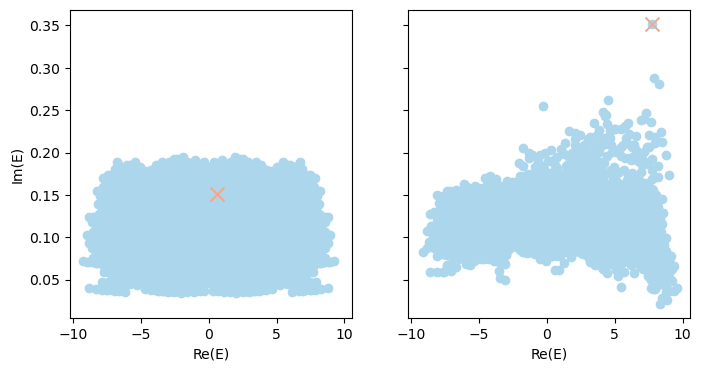

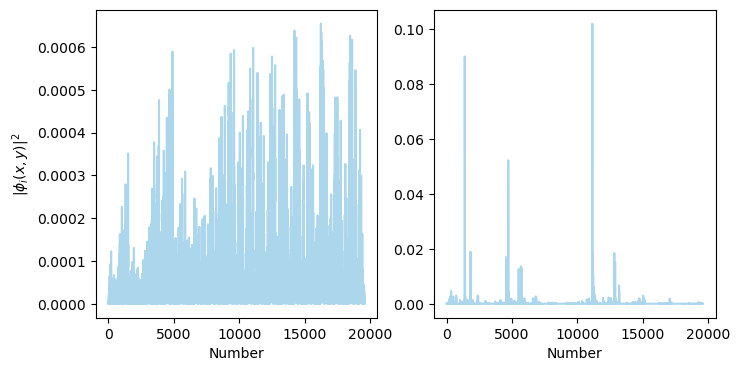

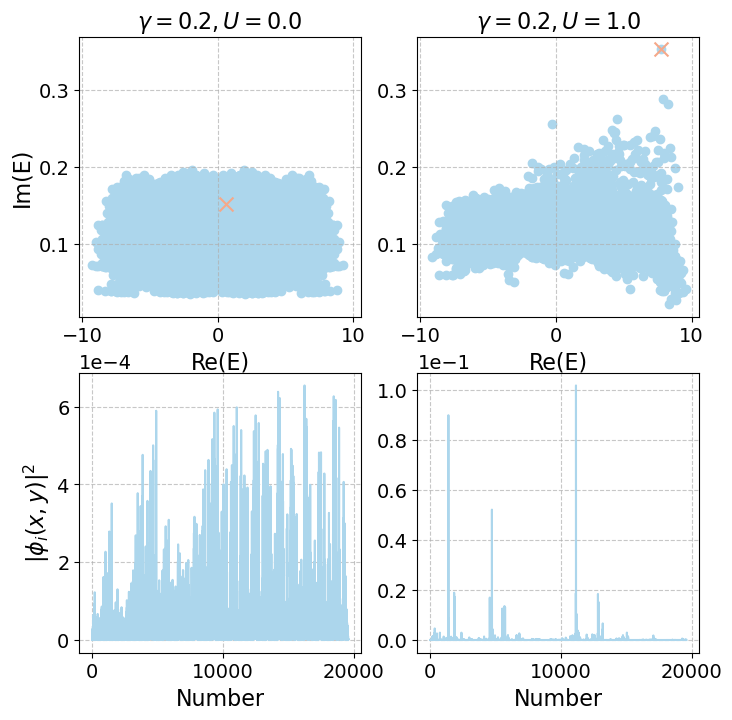

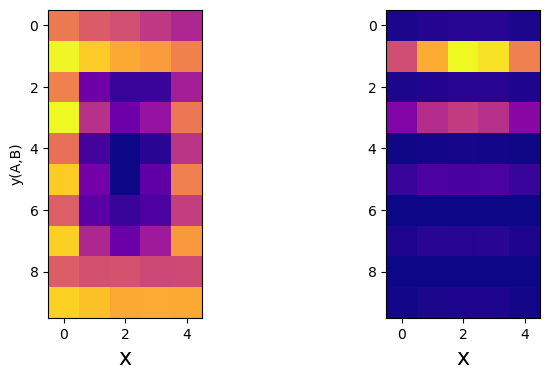

In [60]:
# np.savez('ThreeExcitationEig%d.npz'%num_x, eigval_NH=eigval, eigval_NHMany=eigval2, eigvec_NH=eigvec, eigvec_NHMany=eigvec2)

# color_r = '#B22222'
# color_b = '#000080'
# 可以找出chiral skin mode
num_x, num_y = 5, 5
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ1 = ParticleConservedSystem(num_x, num_y, 1)
QWZ1.add_onsite_term(-1.5)
QWZ1.add_NH(0.2)
QWZ1.add_xhopping_term()
QWZ1.add_yhopping_term()
hamiltonian1 = QWZ1.hamiltonian
eigval1, _ = np.linalg.eig(hamiltonian1)
eigval1 = eigval1[np.argsort(np.abs(np.real(eigval1)))]
three_particle_energy = np.sum(eigval1[:3])


color_r = '#F5A889'
color_b = '#ACD6EC'
with np.load('ThreeExcitationEig5.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']
three_particle_index = np.argmin(np.abs(eigval_NH-three_particle_energy)) # -1


fontsize = 14
fig, ax = plt.subplots(1,2,figsize=(8, 4),sharex=True, sharey=True)
ax[0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0].scatter(eigval_NH[three_particle_index].real, eigval_NH[three_particle_index].imag, color=color_r, s=100, marker='x')
ax[1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[1].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0].set_xlabel('Re(E)')
ax[1].set_xlabel('Re(E)')
ax[0].set_ylabel('Im(E)')
plt.show()

fig, ax = plt.subplots(1,2,figsize=(8, 4))
ax[0].plot(np.abs(eigvec_NH[:,three_particle_index])**2, color=color_b)
ax[1].plot(np.abs(eigvec_NHMany[:,-1])**2, color=color_b)
ax[0].set_xlabel('Number')
ax[1].set_xlabel('Number')
ax[0].set_ylabel(r'$\vert \phi_i(x,y)\vert^2$')
plt.show()

fontsize = 16
labelsize= 14
fig, ax = plt.subplots(2,2,figsize=(8, 8), sharex='row')
ax[0,1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[three_particle_index].real, eigval_NH[three_particle_index].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)

ax[1, 0].plot(np.abs(eigvec_NH[:,three_particle_index])**2, color=color_b)
ax[1, 1].plot(np.abs(eigvec_NHMany[:,-1])**2, color=color_b)
ax[1, 0].set_xlabel('Number',fontsize=fontsize)
ax[1, 1].set_xlabel('Number',fontsize=fontsize)
ax[1, 0].set_ylabel(r'$\vert \phi_i(x,y)\vert^2$',fontsize=fontsize)
for row in range(2):
    for col in range(2):
        ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
for col in range(2):
    ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = ax[row, col].get_yaxis().get_offset_text()
    # 设置字体大小为12
    offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=0.2, U=0.0$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=0.2, U=1.0$', fontsize=fontsize)
fig.savefig("DataPicture/ThreeExcitationSpectrum.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()

color_string = 'plasma' # Reds.
num_x, num_y = 5, 5
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 3)
popu_indice = QWZ2.Calcu_Occup()
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k], three_particle_index])**2) 
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 
fig, ax = plt.subplots(1,2,figsize=(8, 4))
ax[0].imshow(popu_NH.reshape(num_x, 2*num_y).T, cmap=color_string)
ax[1].imshow(popu_NHMany.reshape(num_x, 2*num_y).T, cmap=color_string)
ax[0].set_xlabel('x', fontsize=fontsize)
ax[1].set_xlabel('x', fontsize=fontsize)
ax[0].set_ylabel('y(A,B)')
plt.show()

# fig.savefig("DataPicture/Popu_Interaction_SI.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]

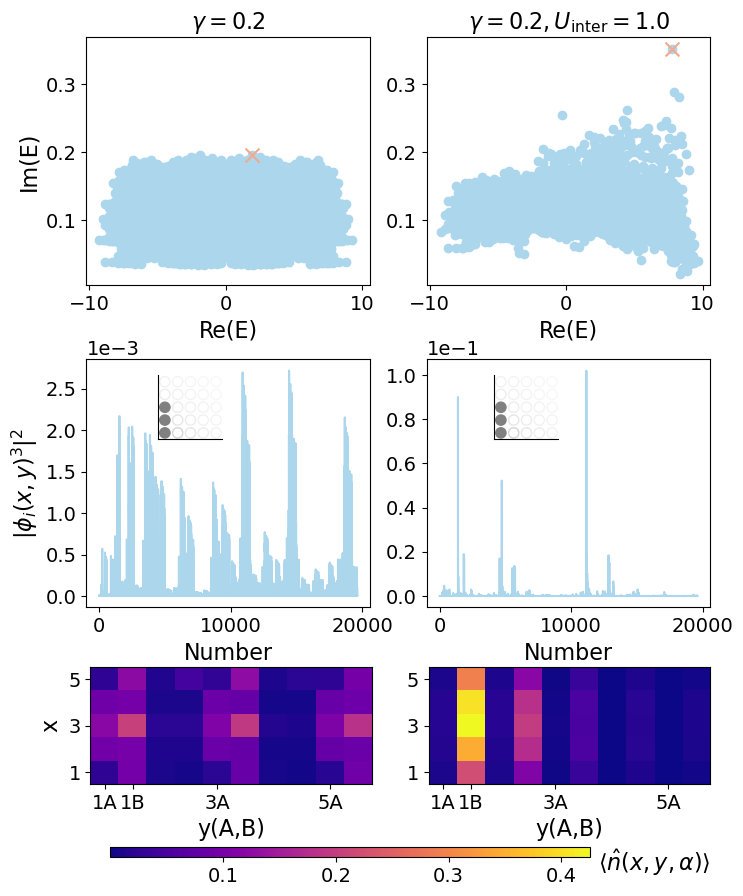

In [13]:
import numpy as np
import matplotlib.pyplot as plt
color_r = '#F5A889'
color_b = '#ACD6EC'
with np.load('ThreeExcitationEig5.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']
num_x, num_y = 5, 5
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 3)
popu_indice = QWZ2.Calcu_Occup()
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k],-1])**2) 
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 

fontsize = 16
labelsize= 14
fig, ax = plt.subplots(2,2,figsize=(8, 10), sharex='row')
ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[-1].real, eigval_NH[-1].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)

ax[1, 0].plot(np.abs(eigvec_NH[:,-1])**2, color=color_b)
ax[1, 1].plot(np.abs(eigvec_NHMany[:,-1])**2, color=color_b)
ax[1, 0].set_xlabel('Number',fontsize=fontsize)
ax[1, 1].set_xlabel('Number',fontsize=fontsize)
ax[1, 0].set_ylabel(r'$\vert \phi_i(x,y)^3\vert^2$',fontsize=fontsize)
for row in range(2):
    for col in range(2):
        # ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
for col in range(2):
    ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = ax[row, col].get_yaxis().get_offset_text()
    # 设置字体大小为12
    offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=0.2$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=1.0$', fontsize=fontsize)


# 画三激发的basis
new_ax = fig.add_axes([0.21, 0.51, 0.08, 0.08]) 
ShowTwoExcitationPlot(new_ax,3)
new_ax = fig.add_axes([0.63, 0.51, 0.08, 0.08]) 
ShowTwoExcitationPlot(new_ax,3)


from scipy import ndimage
n_map1 = popu_NH.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
# 计算旋转后的坐标范围
n_map2 = popu_NHMany.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data2 = ndimage.rotate(n_map2, angle=90, reshape=True)
# 计算旋转后的坐标范围
color_string = 'plasma'
pos1 = ax[1, 0].get_position()
pos2 = ax[1, 1].get_position()
plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.35,
    top=0.92,
    hspace=0.3,
    wspace=0.2
)
gap = -0.18
ax3 = fig.add_axes([pos1.x0, pos1.y0 - gap - pos1.height/3, pos1.width, pos1.height/3])
ax4 = fig.add_axes([pos2.x0, pos2.y0 - gap - pos1.height/3, pos2.width, pos1.height/3])
vmin, vmax = np.min([np.min(popu_NH), np.min(popu_NHMany)]), np.max([np.max(popu_NH), np.max(popu_NHMany)]) # 但是这样颜色会看不出来。
sm  = ax3.imshow(n_map1, 
          aspect='auto',
          origin='lower',
          vmin=vmin,vmax=vmax,
          cmap=color_string)
ax4.imshow(n_map2, 
          aspect='auto',
          origin='lower',
          vmin=vmin,vmax=vmax,
          cmap=color_string)
ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax4.set_xlabel('y(A,B)', fontsize=fontsize)
ax3.set_ylabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
ax3.set_xticks(ticks=[0, 1, 4, 8], labels=['1A', '1B', '3A', '5A'])
ax4.set_xticks(ticks=[0, 1, 4, 8], labels=['1A', '1B', '3A', '5A'])
ax3.set_yticks(ticks=[0,2,4], labels=[1, 3, 5])
ax4.set_yticks(ticks=[0,2,4], labels=[1, 3, 5])

cax = fig.add_axes([0.15, 0.1, 0.6, 0.01]) # [左，下，宽，高]
cbar = plt.colorbar(
    sm,
    cax=cax,
    orientation='horizontal'
)
cax.tick_params(axis='both', which='major', labelsize=labelsize)
# cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
cax.text(cax.get_xlim()[-1]+0.007, cax.get_ylim()[-1], r'$\langle \hat{n}(x,y,\alpha) \rangle$', va='top', ha='left', fontsize=fontsize)
fig.savefig("DataPicture/ThreeExcitationSpectrum.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()

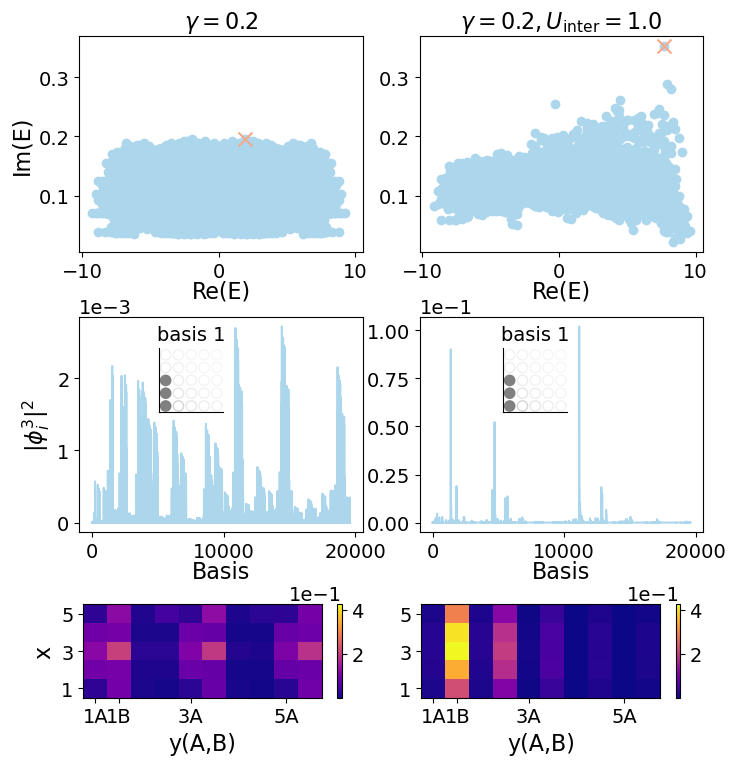

In [324]:
import numpy as np
import matplotlib.pyplot as plt
color_r = '#F5A889'
color_b = '#ACD6EC'
with np.load('ThreeExcitationEig5.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']
num_x, num_y = 5, 5
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 3)
popu_indice = QWZ2.Calcu_Occup()
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k],-1])**2) 
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 

fontsize = 16
labelsize= 14
labelpad = -1
fig, ax = plt.subplots(2,2,figsize=(8, 8), sharex='row')
ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[-1].real, eigval_NH[-1].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize, labelpad=labelpad)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize,labelpad=labelpad)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)

basis_num = len(eigvec_NH[:,-1])
ax[1, 0].plot(np.arange(1,basis_num+1), np.abs(eigvec_NH[:,-1])**2, color=color_b)
ax[1, 1].plot(np.arange(1,basis_num+1), np.abs(eigvec_NHMany[:,-1])**2, color=color_b)
ax[1, 0].set_xlabel('Basis',fontsize=fontsize,labelpad=labelpad)
ax[1, 1].set_xlabel('Basis',fontsize=fontsize,labelpad=labelpad)
ax[1, 0].set_ylabel(r'$\vert \phi_i^3\vert^2$',fontsize=fontsize)
for row in range(2):
    for col in range(2):
        # ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
for col in range(2):
    ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = ax[row, col].get_yaxis().get_offset_text()
    # 设置字体大小为12
    offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=0.2$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=1.0$', fontsize=fontsize)

# 画三激发的basis
new_ax = fig.add_axes([0.22, 0.45, 0.08, 0.08]) 
ShowTwoExcitationPlot(new_ax,3)
new_ax.set_title('basis 1', fontsize=14)
new_ax = fig.add_axes([0.65, 0.45, 0.08, 0.08]) 
ShowTwoExcitationPlot(new_ax,3)
new_ax.set_title('basis 1', fontsize=14)

from scipy import ndimage
n_map1 = popu_NH.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
# 计算旋转后的坐标范围
n_map2 = popu_NHMany.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data2 = ndimage.rotate(n_map2, angle=90, reshape=True)
# 计算旋转后的坐标范围
color_string = 'plasma'
pos1 = ax[1, 0].get_position()
pos2 = ax[1, 1].get_position()
plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.3,
    top=0.92,
    hspace=0.3,
    wspace=0.2
)
gap = -0.1
ax3 = fig.add_axes([pos1.x0, pos1.y0 - gap - pos1.height/3, pos1.width*1.1, pos1.height/3])
ax4 = fig.add_axes([pos2.x0, pos2.y0 - gap - pos1.height/3, pos2.width*1.1, pos1.height/3])
vmin, vmax = np.min([np.min(popu_NH), np.min(popu_NHMany)]), np.max([np.max(popu_NH), np.max(popu_NHMany)]) # 但是这样颜色会看不出来。
im1  = ax3.imshow(n_map1, 
          aspect='auto',
          origin='lower',
          vmin=vmin,vmax=vmax,
          cmap=color_string)
im2 = ax4.imshow(n_map2, 
          aspect='auto',
          origin='lower',
          vmin=vmin,vmax=vmax,
          cmap=color_string)
ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax4.set_xlabel('y(A,B)', fontsize=fontsize)
ax3.set_ylabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
ax3.set_xticks(ticks=[0, 1, 4, 8], labels=['1A', '1B', '3A', '5A'])
ax4.set_xticks(ticks=[0, 1, 4, 8], labels=['1A', '1B', '3A', '5A'])
ax3.set_yticks(ticks=[0,2,4], labels=[1,3,5])
ax4.set_yticks(ticks=[0,2,4], labels=[1,3,5])

cbar1 = plt.colorbar(im1, ax=ax3, fraction=0.18)  # 关联到第一个axes
cbar2 = plt.colorbar(im2, ax=ax4, fraction=0.18)  # 关联到第一个axes
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar2.ax.tick_params(axis='both', which='major', labelsize=labelsize)
# cbar用科学计数法，并加大字体
cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar1.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)
cbar2.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar2.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)

# cax = fig.add_axes([0.15, 0.1, 0.6, 0.01]) # [左，下，宽，高]
# cbar = plt.colorbar(
#     sm,
#     cax=cax,
#     orientation='horizontal'
# )
# cax.tick_params(axis='both', which='major', labelsize=labelsize)
# # cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
# cax.text(cax.get_xlim()[-1]+0.007, cax.get_ylim()[-1], r'$\langle \hat{n}(x,y,\alpha) \rangle$', va='top', ha='left', fontsize=fontsize)
# fig.savefig("DataPicture/ThreeExcitationSpectrum.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()

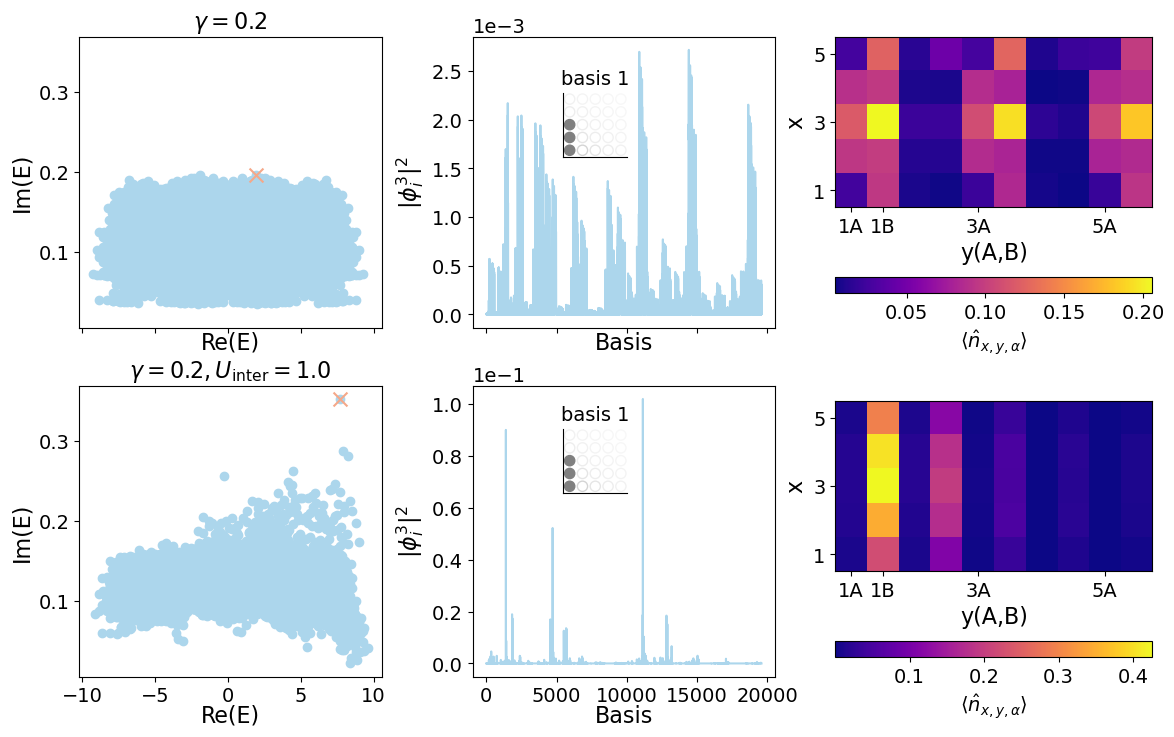

In [5]:
import numpy as np
import matplotlib.pyplot as plt
color_r = '#F5A889'
color_b = '#ACD6EC'
with np.load('ThreeExcitationEig5.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']

num_x, num_y = 5, 5
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 3)
popu_indice = QWZ2.Calcu_Occup()
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k],-1])**2) 
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 

fontsize = 16
labelsize= 14
labelpad = -1
fig, ax = plt.subplots(2,2,figsize=(12, 8), sharex='col')

ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[1,0]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[-1].real, eigval_NH[-1].imag, color=color_r, s=100, marker='x')
ax[1, 0].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[1, 0].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize, labelpad=labelpad)
ax[1, 0].set_xlabel('Re(E)',fontsize=fontsize,labelpad=labelpad)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)
ax[1, 0].set_ylabel('Im(E)',fontsize=fontsize)

basis_num = len(eigvec_NH[:,-1])
ax[0, 1].plot(np.arange(1,basis_num+1), np.abs(eigvec_NH[:,-1])**2, color=color_b)
ax[1, 1].plot(np.arange(1,basis_num+1), np.abs(eigvec_NHMany[:,-1])**2, color=color_b)
ax[0, 1].set_xlabel('Basis',fontsize=fontsize,labelpad=labelpad)
ax[1, 1].set_xlabel('Basis',fontsize=fontsize,labelpad=labelpad)
ax[0, 1].set_ylabel(r'$\vert \phi_i^3\vert^2$',fontsize=fontsize)
ax[1, 1].set_ylabel(r'$\vert \phi_i^3\vert^2$',fontsize=fontsize)
for row in range(2):
    for col in range(2):
        # ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
for col in range(2):
    ax[col, 1].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = ax[row, col].get_yaxis().get_offset_text()
    # 设置字体大小为12
    offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=0.2$', fontsize=fontsize)
ax[1, 0].set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=1.0$', fontsize=fontsize)

# 画三激发的basis
new_ax = fig.add_axes([0.51, 0.38, 0.08, 0.08]) 
ShowTwoExcitationPlot(new_ax,3)
new_ax.set_title('basis 1', fontsize=14)
new_ax = fig.add_axes([0.51, 0.8, 0.08, 0.08]) 
ShowTwoExcitationPlot(new_ax,3)
new_ax.set_title('basis 1', fontsize=14)


color_string = 'plasma'
pos1 = ax[0, 1].get_position()
pos2 = ax[1, 1].get_position()
gap = -0.15
ax3 = fig.add_axes([pos1.x0 + pos1.width + gap, pos1.y0+0.2*pos1.height, 3*pos1.width/4, pos1.height])
ax4 = fig.add_axes([pos2.x0 + pos2.width + gap, pos2.y0+0.1*pos2.height, 3*pos2.width/4, pos1.height])
im1  = ax3.imshow(popu_NH.reshape(num_x, 2*num_y), 
          aspect='auto',
          origin='lower',
          cmap=color_string)
im2 = ax4.imshow(popu_NHMany.reshape(num_x, 2*num_y), 
          aspect='auto',
          origin='lower',
          cmap=color_string)
ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax4.set_xlabel('y(A,B)', fontsize=fontsize)
ax3.set_ylabel('x', fontsize=fontsize)
ax4.set_ylabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
ax3.set_xticks(ticks=[0, 1, 4, 8], labels=['1A', '1B', '3A', '5A'])
ax4.set_xticks(ticks=[0, 1, 4, 8], labels=['1A', '1B', '3A', '5A'])
ax3.set_yticks(ticks=[0, 2, 4], labels=[1, 3, 5])
ax4.set_yticks(ticks=[0, 2, 4], labels=[1, 3, 5])

cbar1 = plt.colorbar(im1, ax=ax3, orientation='horizontal', fraction=0.14, pad=0.25)  # 关联到第一个axes
cbar2 = plt.colorbar(im2, ax=ax4, orientation='horizontal', fraction=0.14, pad=0.25)  # 关联到第一个axes
cbar1.ax.set_xlabel(r'$\langle \hat{n}_{x,y,\alpha} \rangle$', fontsize=labelsize)
cbar2.ax.set_xlabel(r'$\langle \hat{n}_{x,y,\alpha} \rangle$',fontsize=labelsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar2.ax.tick_params(axis='both', which='major', labelsize=labelsize)
# cbar用科学计数法，并加大字体
cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar1.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)
cbar2.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar2.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)

plt.subplots_adjust(
    left=0.12,
    right=0.7,
    bottom=0.15,
    top=0.95,
    hspace=0.2,
    wspace=0.3
)
fig.savefig("DataPicture/ThreeExcitationSpectrum2.pdf", bbox_inches='tight') 
plt.show()

In [326]:
import numpy as np
from matplotlib.colors import Normalize
import plotly.graph_objects as go

def tril_indices_3d(num_bits):
    # k=1的秦广
    # positions = []
    # for i in range(1, num_bits):
    #     for j in range(0, i):
    #         # for k in range(0, j):
    #         positions.append([i, j])
    # positions = np.array(positions)
    positions = []
    for i in range(1, num_bits):
        for j in range(0, i):
            for k in range(0, j):
                positions.append([i, j, k])
    positions = np.array(positions)
    return positions[:, 0], positions[:, 1], positions[:,2]

print(tril_indices_3d(3))
# print(np.column_stack((ii, jj, kk)))
with np.load('ThreeExcitationEig5.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']

d_indice = tril_indices_3d(50)
d_NH = np.zeros((50, 50, 50))
print(np.shape(d_indice[0]), np.shape(eigvec_NH[:,-1]))
d_NH[d_indice] = np.abs(eigvec_NH[:,-1])**2
# symmetry加上
d_NH = (d_NH + d_NH.transpose(0, 2, 1) + d_NH.transpose(1, 0, 2) + d_NH.transpose(1, 2, 0) + d_NH.transpose(2, 0, 1) + d_NH.transpose(2, 1, 0))


d_indice = tril_indices_3d(50)
d_NHMany = np.zeros((50, 50, 50))
print(np.shape(d_indice[0]), np.shape(eigvec_NHMany[:,-1]))
d_NHMany[d_indice] = np.abs(eigvec_NHMany[:,-1])**2
# symmetry加上
d_NHMany = (d_NHMany + d_NHMany.transpose(0, 2, 1) + d_NHMany.transpose(1, 0, 2) + d_NHMany.transpose(1, 2, 0) + d_NHMany.transpose(2, 0, 1) + d_NHMany.transpose(2, 1, 0))
d_NHMany = d_NHMany

import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots


# 生成坐标网格（只计算非零点的坐标）
threshold = 0.001
x1, y1, z1 = np.where(d_NH > threshold)
x2, y2, z2 = np.where(d_NHMany > threshold)

# 创建包含两个3D子图的画布
fig = make_subplots(
    rows=1, cols=2,
    specs=[[{'type': 'scatter3d'}, {'type': 'scatter3d'}]],
    subplot_titles=("Configuration A", "Configuration B"),
    horizontal_spacing=0.1
)


# 第一个子图（左）
fig.add_trace(
    go.Scatter3d(
        x=x1, y=y1, z=z1,
        mode='markers',
        marker=dict(
            size=3,
            color=d_NH[x1, y1, z1],
            colorscale='greys',
            opacity=0.5,
            showscale=True,
            colorbar=dict(
                title=dict(text=r'$|\psi|^2$', font=dict(size=14)),  # 数学公式标题
                x=0.45,  # 调整colorbar水平位置
                len=0.5
            )
        ),
        name='Data A'
    ),
    row=1, col=1
)

# 第二个子图（右）- 这里使用相同数据，实际可替换为不同数据
fig.add_trace(
    go.Scatter3d(
        x=x2, y=y2, z=z2,
        mode='markers',
        marker=dict(
            size=3,
            color=d_NHMany[x2, y2, z2],
            colorscale='greys',  # 改用不同颜色映射
            opacity=0.5,
            showscale=True,
            colorbar=dict(
                title=dict(text='&lang;<i>n&#770;</i>&rang;', font=dict(size=14)),
                x=1.0,  # 调整colorbar水平位置
                len=0.5
            )
        ),
        name='Data B'
    ),
    row=1, col=2
)

# 更新全局布局和子图坐标轴标签
fig.update_layout(
    title_text='Three-particle Correlation Function',
    width=1200,
    height=600,
    scene=dict(  # 第一个子图的设置
        xaxis_title='n&#770;<sub>x,y,z</sub>',
        yaxis_title=r'$⟨n̂⟩$',
        zaxis_title=r'$⟨n̂⟩$',
    ),
    scene2=dict(  # 第二个子图的设置
        xaxis_title=r'$\hat{n}_{x,y,z}$',
        yaxis_title='n̂ₓᵧ𝓏',
        zaxis_title='n̂ₓᵧ𝓏',
    ),
    margin=dict(l=0, r=0, b=0, t=40)  # 调整边距
)

# 导出PDF（需要安装kaleido）
# fig.write_image("three_particle_correlation.pdf", format='pdf')

fig.show()
# fig.write_image("DataPicture/plotly_3d.pdf", format='pdf')
# fig.savefig("DataPicture/plotly_3d.pdf", bbox_inches='tight') # , 
# plotly.io.write_image(fig, "DataPicture/plotly_3d.pdf")
# fig.show()

(array([2]), array([1]), array([0]))
(19600,) (19600,)
(19600,) (19600,)


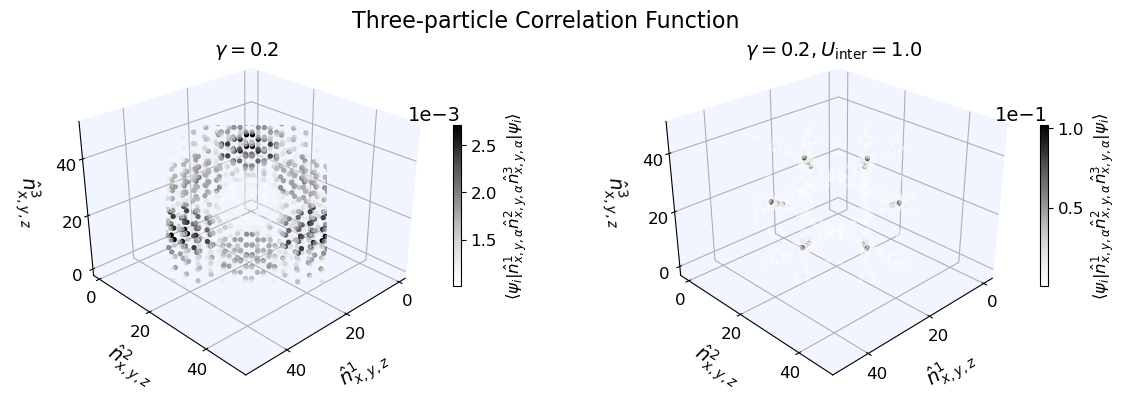

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from matplotlib.colors import Normalize
import matplotlib.colors as mcolors
# 获取 colormap（不含 alpha）

def set_axes_equal(ax):
    '''Make 3D axes have equal scale (for better spatial perspective)'''
    x_limits = ax.get_xlim3d()
    y_limits = ax.get_ylim3d()
    z_limits = ax.get_zlim3d()
    x_range = abs(x_limits[1] - x_limits[0])
    y_range = abs(y_limits[1] - y_limits[0])
    z_range = abs(z_limits[1] - z_limits[0])
    max_range = max(x_range, y_range, z_range)
    x_middle = np.mean(x_limits)
    y_middle = np.mean(y_limits)
    z_middle = np.mean(z_limits)
    ax.set_xlim3d([x_middle - max_range/2, x_middle + max_range/2])
    ax.set_ylim3d([y_middle - max_range/2, y_middle + max_range/2])
    ax.set_zlim3d([z_middle - max_range/2, z_middle + max_range/2])

    ax.set_xlabel(r'$\hat{n}^1_{x,y,z}$', labelpad=-10, fontsize=labelsize)
    ax.set_ylabel(r'$\hat{n}^2_{x,y,z}$', labelpad=-10, fontsize=labelsize)
    ax.set_zlabel(r'$\hat{n}^3_{x,y,z}$', labelpad=-10, fontsize=labelsize)
    ax.tick_params(axis='x', pad=-5)
    ax.tick_params(axis='y', pad=-5)
    ax.tick_params(axis='z', pad=-5)

    # 背景颜色
    bgcolor = (240/255, 245/255, 255/255)  # rgba(240,246,255,1)
    ax.w_xaxis.set_pane_color(bgcolor + (1.0,))
    ax.w_yaxis.set_pane_color(bgcolor + (1.0,))
    ax.w_zaxis.set_pane_color(bgcolor + (1.0,))
    #设置视角，模拟 Plotly 默认视角 和距离
    ax.view_init(elev=27, azim=46)
    ax.dist = 4.5  # 默认为10，尝试调整到7
labelsize = 14

# 生成坐标网格（只计算非零点的坐标）
threshold = 0.001
x1, y1, z1 = np.where(d_NH > threshold)
x2, y2, z2 = np.where(d_NHMany > threshold)
color_string = 'Greys'

# 对应的颜色值
c1 = d_NH[x1, y1, z1]
c2 = d_NHMany[x2, y2, z2]

# 创建画布和两个3D子图
fig = plt.figure(figsize=(12, 3.5))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax2 = fig.add_subplot(1, 2, 2, projection='3d')

def PlotData1(ax, coordinate, data_c):
    # 对 ax1 的数据
    norm1 = Normalize(vmin=np.min(data_c), vmax=np.max(data_c))
    cmap = cm.get_cmap(color_string)
    rgb1 = cmap(norm1(data_c))
    rgb1[:, 3] = norm1(data_c)*(1-alpha)+alpha # norm1(data_c)

    perceived_rgb = rgb1
    perceived_cmap = mcolors.ListedColormap(perceived_rgb)
    mappable1 = cm.ScalarMappable(norm=norm1, cmap=color_string)

    x1, y1, z1 = coordinate[0], coordinate[1], coordinate[2]
    # 第一个子图
    p1 = ax.scatter(x1, y1, z1, facecolors=rgb1, cmap=color_string, s=8, depthshade=False) # 'inferno_r'
    cb1 = fig.colorbar(mappable1, ax=ax, fraction=0.03, pad=0.25)
    cb1.set_label(r'$\langle \psi_i \vert \hat{n}^1_{x,y,\alpha} \hat{n}^2_{x,y,\alpha} \hat{n}^3_{x,y,\alpha} \vert \psi_i \rangle$', fontsize=12)
    cb1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = cb1.ax.get_yaxis().get_offset_text()
    offset_text.set_fontsize(labelsize)

# plot the data and set the axis. 
PlotData1(ax1, [x1,y1,z1], c1)
PlotData1(ax2, [x2,y2,z2], c2)
set_axes_equal(ax1)
set_axes_equal(ax2)
ax1.set_title(r'$\gamma=0.2$', pad=50)
ax2.set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=1.0$', pad=50)

plt.subplots_adjust(wspace=0.35, hspace=0.2)  # wspace 控制子图水平间距
fig.suptitle('Three-particle Correlation Function', fontsize=16, y=0.85)

plt.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig("DataPicture/CorrelationMap_3P.pdf", bbox_inches='tight')
plt.show()

(array([2]), array([1]), array([0]))


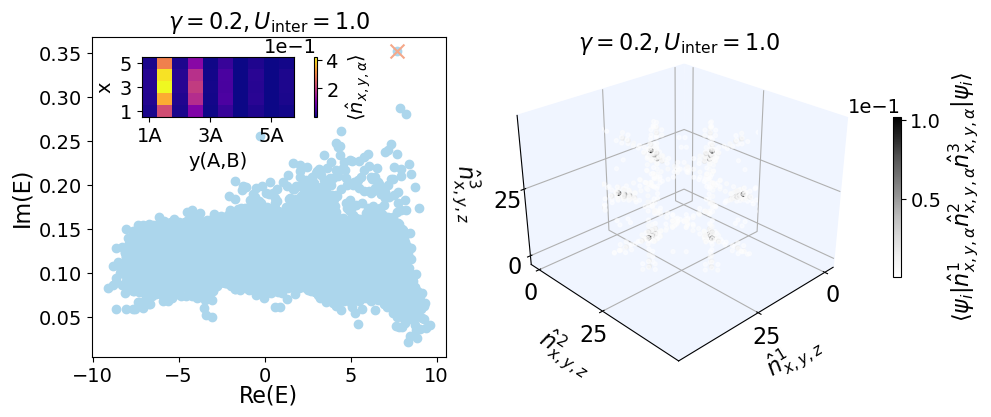

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import Normalize
from matplotlib import cm
import matplotlib.colors as mcolors

color_r = '#F5A889'
color_b = '#ACD6EC'
fontsize = 16
labelsize= 14

def set_axes_equal(ax):
    '''Make 3D axes have equal scale (for better spatial perspective)'''
    x_limits = ax.get_xlim3d()
    y_limits = ax.get_ylim3d()
    z_limits = ax.get_zlim3d()
    x_range = abs(x_limits[1] - x_limits[0])
    y_range = abs(y_limits[1] - y_limits[0])
    z_range = abs(z_limits[1] - z_limits[0])
    max_range = max(x_range, y_range, z_range)
    x_middle = np.mean(x_limits)
    y_middle = np.mean(y_limits)
    z_middle = np.mean(z_limits)
    ax.set_xlim3d([x_middle - max_range/2, x_middle + max_range/2])
    ax.set_ylim3d([y_middle - max_range/2, y_middle + max_range/2])
    ax.set_zlim3d([z_middle - max_range/2, z_middle + max_range/2])

    ax.set_xlabel(r'$\hat{n}^1_{x,y,z}$', labelpad=-10, fontsize=fontsize)
    ax.set_ylabel(r'$\hat{n}^2_{x,y,z}$', labelpad=-10, fontsize=fontsize)
    ax.set_zlabel(r'$\hat{n}^3_{x,y,z}$', labelpad=-10, fontsize=fontsize)
    ax.tick_params(axis='x', pad=-5)
    ax.tick_params(axis='y', pad=-5)
    ax.tick_params(axis='z', pad=-5)

    # 背景颜色
    bgcolor = (240/255, 245/255, 255/255)  # rgba(240,246,255,1)
    ax.w_xaxis.set_pane_color(bgcolor + (1.0,))
    ax.w_yaxis.set_pane_color(bgcolor + (1.0,))
    ax.w_zaxis.set_pane_color(bgcolor + (1.0,))
    #设置视角，模拟 Plotly 默认视角 和距离
    ax.view_init(elev=27, azim=46)
    ax.dist = 4.5  # 默认为10，尝试调整到7
labelsize = 14

with np.load('ThreeExcitationEig5.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']

num_x, num_y = 5, 5
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 3)
popu_indice = QWZ2.Calcu_Occup()
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k],-1])**2) 
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 

fontsize = 16
labelsize= 14
labelpad = -1
fig = plt.figure(figsize=(10, 4))
ax1 = fig.add_subplot(1, 2, 1)

ax1.scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax1.scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
# ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize, labelpad=labelpad)
ax1.set_xlabel('Re(E)',fontsize=fontsize,labelpad=labelpad)
ax1.set_ylabel('Im(E)',fontsize=fontsize)

# for row in range(2):
#     for col in range(2):
#         # ax[row, col].grid(True, linestyle='--', alpha=0.7)
#         ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

#         # 设置y轴为科学计数法
#         #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
#         # 获取当前子图的y轴偏移文本
#         offset_text = ax[row, col].get_yaxis().get_offset_text()
#         # 设置字体大小为12
#         offset_text.set_fontsize(labelsize)

ax1.set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=1.0$', fontsize=fontsize)
ax1.tick_params(axis='both', which='major', labelsize=labelsize)

color_string = 'plasma'
# pos1 = ax[0, 1].get_position()
# pos2 = ax[1, 1].get_position()
# gap = -0.15
# ax3 = fig.add_axes([pos1.x0 + pos1.width + gap, pos1.y0+0.2*pos1.height, 3*pos1.width/4, pos1.height])
# ax4 = fig.add_axes([pos2.x0 + pos2.width + gap, pos2.y0+0.1*pos2.height, 3*pos2.width/4, pos1.height])
# im1  = ax3.imshow(popu_NH.reshape(num_x, 2*num_y), 
#           aspect='auto',
#           origin='lower',
#           cmap=color_string)

# ax4 = inset_axes(ax[0], width="50%", height="30%", loc='upper left') # bbox_to_anchor=(0.2, 0.75, 0.5, 0.3)
ax4 = fig.add_axes([0.17, 0.75, 0.2, 0.15])  # [左边距, 底边距, 宽度, 高度
im2 = ax4.imshow(popu_NHMany.reshape(num_x, 2*num_y), 
          aspect='auto',
          origin='lower',
          cmap=color_string)

# ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax4.set_xlabel('y(A,B)', fontsize=labelsize)
# ax3.set_ylabel('x', fontsize=fontsize)
ax4.set_ylabel('x', fontsize=labelsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
# ax3.set_xticks(ticks=[0, 1, 4, 8], labels=['1A', '1B', '3A', '5A'])
ax4.set_xticks(ticks=[0, 4, 8], labels=['1A', '3A', '5A'])
# ax3.set_yticks(ticks=[0, 2, 4], labels=[1, 3, 5])
ax4.set_yticks(ticks=[0, 2, 4], labels=[1, 3, 5])

# cbar1 = plt.colorbar(im1, ax=ax3, orientation='horizontal', fraction=0.14, pad=0.25)  # 关联到第一个axes
cbar2 = plt.colorbar(im2, ax=ax4, orientation='vertical', fraction=0.14, pad=0.1)  # 关联到第一个axes
cbar1.ax.set_xlabel(r'$\langle \hat{n}_{x,y,\alpha} \rangle$', fontsize=labelsize)
cbar2.ax.set_ylabel(r'$\langle \hat{n}_{x,y,\alpha} \rangle$',fontsize=labelsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar2.ax.tick_params(axis='both', which='major', labelsize=labelsize)
# cbar用科学计数法，并加大字体
cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar1.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)
cbar2.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar2.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)




def tril_indices_3d(num_bits):
    # k=1的秦广
    # positions = []
    # for i in range(1, num_bits):
    #     for j in range(0, i):
    #         # for k in range(0, j):
    #         positions.append([i, j])
    # positions = np.array(positions)
    positions = []
    for i in range(1, num_bits):
        for j in range(0, i):
            for k in range(0, j):
                positions.append([i, j, k])
    positions = np.array(positions)
    return positions[:, 0], positions[:, 1], positions[:,2]

print(tril_indices_3d(3))
# print(np.column_stack((ii, jj, kk)))
with np.load('ThreeExcitationEig5.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']

d_indice = tril_indices_3d(50)
d_NHMany = np.zeros((50, 50, 50))
d_NHMany[d_indice] = np.abs(eigvec_NHMany[:,-1])**2
# symmetry加上
d_NHMany = (d_NHMany + d_NHMany.transpose(0, 2, 1) + d_NHMany.transpose(1, 0, 2) + d_NHMany.transpose(1, 2, 0) + d_NHMany.transpose(2, 0, 1) + d_NHMany.transpose(2, 1, 0))
d_NHMany = d_NHMany

# 生成坐标网格（只计算非零点的坐标）
threshold = 0.001
x2, y2, z2 = np.where(d_NHMany > threshold)
color_string = 'Greys'

# 对应的颜色值
c2 = d_NHMany[x2, y2, z2]

# 创建画布和两个3D子图
# ax2 = fig.add_subplot(1, 2, 2, projection='3d')
# # 获取当前位置并调整
# pos = ax2.get_position()
# ax2.set_position([pos.x0 + 1.0, pos.y0 + 0.2, pos.width * 0.3, pos.height * 0.3])  # 缩小宽度和高度
# # 使用 add_axes 直接指定位置和大小
ax2 = fig.add_axes([0.63, 0.35, 0.3, 0.4], projection='3d')  # [left, bottom, width, height]

def PlotData1(ax, coordinate, data_c):
    # 对 ax1 的数据
    norm1 = Normalize(vmin=np.min(data_c), vmax=np.max(data_c))
    cmap = cm.get_cmap(color_string)
    rgb1 = cmap(norm1(data_c))
    rgb1[:, 3] = norm1(data_c)*(1-alpha)+alpha # norm1(data_c)

    perceived_rgb = rgb1
    perceived_cmap = mcolors.ListedColormap(perceived_rgb)
    mappable1 = cm.ScalarMappable(norm=norm1, cmap=color_string)

    x1, y1, z1 = coordinate[0], coordinate[1], coordinate[2]
    # 第一个子图
    p1 = ax.scatter(x1, y1, z1, facecolors=rgb1, cmap=color_string, s=8, depthshade=False) # 'inferno_r'
    cb1 = fig.colorbar(mappable1, ax=ax, fraction=0.03, pad=0.45)
    cb1.set_label(r'$\langle \psi_i \vert \hat{n}^1_{x,y,\alpha} \hat{n}^2_{x,y,\alpha} \hat{n}^3_{x,y,\alpha} \vert \psi_i \rangle$', fontsize=fontsize)
    cb1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    cb1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
    offset_text = cb1.ax.get_yaxis().get_offset_text()
    offset_text.set_fontsize(labelsize)

alpha = 0.5
# plot the data and set the axis. 
PlotData1(ax2, [x2, y2, z2], c2)
set_axes_equal(ax2)
ax2.set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=1.0$', pad=50, fontsize=fontsize)
for axis_label in ['x', 'y', 'z']:
    ax2.tick_params(axis=axis_label, labelsize=fontsize)

plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.15,
    top=0.95,
    hspace=0.2,
    wspace=0.2
)
fig.savefig("DataPicture/ThreeExcitation_data.pdf", bbox_inches='tight')
plt.show()

(array([2]), array([1]), array([0]))


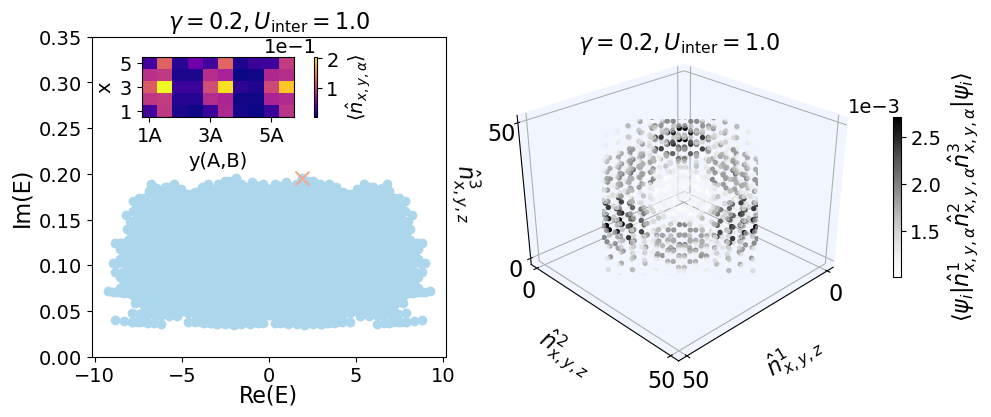

In [108]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import Normalize
from matplotlib import cm
import matplotlib.colors as mcolors

color_r = '#F5A889'
color_b = '#ACD6EC'
fontsize = 16
labelsize= 14

def set_axes_equal(ax):
    '''Make 3D axes have equal scale (for better spatial perspective)'''
    x_limits = ax.get_xlim3d()
    y_limits = ax.get_ylim3d()
    z_limits = ax.get_zlim3d()
    x_range = abs(x_limits[1] - x_limits[0])
    y_range = abs(y_limits[1] - y_limits[0])
    z_range = abs(z_limits[1] - z_limits[0])
    max_range = max(x_range, y_range, z_range)
    x_middle = np.mean(x_limits)
    y_middle = np.mean(y_limits)
    z_middle = np.mean(z_limits)
    ax.set_xlim3d([x_middle - max_range/2, x_middle + max_range/2])
    ax.set_ylim3d([y_middle - max_range/2, y_middle + max_range/2])
    ax.set_zlim3d([z_middle - max_range/2, z_middle + max_range/2])

    ax.set_xlabel(r'$\hat{n}^1_{x,y,z}$', labelpad=-10, fontsize=fontsize)
    ax.set_ylabel(r'$\hat{n}^2_{x,y,z}$', labelpad=-10, fontsize=fontsize)
    ax.set_zlabel(r'$\hat{n}^3_{x,y,z}$', labelpad=-10, fontsize=fontsize)
    ax.tick_params(axis='x', pad=-5)
    ax.tick_params(axis='y', pad=-5)
    ax.tick_params(axis='z', pad=-5)

    # 背景颜色
    bgcolor = (240/255, 245/255, 255/255)  # rgba(240,246,255,1)
    ax.w_xaxis.set_pane_color(bgcolor + (1.0,))
    ax.w_yaxis.set_pane_color(bgcolor + (1.0,))
    ax.w_zaxis.set_pane_color(bgcolor + (1.0,))
    #设置视角，模拟 Plotly 默认视角 和距离
    ax.view_init(elev=27, azim=46)
    ax.dist = 4.5  # 默认为10，尝试调整到7
labelsize = 14

with np.load('ThreeExcitationEig5.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']
eigval_NHMany, eigvec_NHMany = eigval_NH, eigvec_NH


num_x, num_y = 5, 5
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 3)
popu_indice = QWZ2.Calcu_Occup()
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k],-1])**2) 
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 

fontsize = 16
labelsize= 14
labelpad = -1
fig = plt.figure(figsize=(10, 4))
ax1 = fig.add_subplot(1, 2, 1)

ax1.scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax1.scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
# ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize, labelpad=labelpad)
ax1.set_xlabel('Re(E)',fontsize=fontsize,labelpad=labelpad)
ax1.set_ylabel('Im(E)',fontsize=fontsize)
ax1.set_ylim(ymin=0, ymax=0.35)

# for row in range(2):
#     for col in range(2):
#         # ax[row, col].grid(True, linestyle='--', alpha=0.7)
#         ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

#         # 设置y轴为科学计数法
#         #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
#         # 获取当前子图的y轴偏移文本
#         offset_text = ax[row, col].get_yaxis().get_offset_text()
#         # 设置字体大小为12
#         offset_text.set_fontsize(labelsize)

ax1.set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=1.0$', fontsize=fontsize)
ax1.tick_params(axis='both', which='major', labelsize=labelsize)

color_string = 'plasma'
# pos1 = ax[0, 1].get_position()
# pos2 = ax[1, 1].get_position()
# gap = -0.15
# ax3 = fig.add_axes([pos1.x0 + pos1.width + gap, pos1.y0+0.2*pos1.height, 3*pos1.width/4, pos1.height])
# ax4 = fig.add_axes([pos2.x0 + pos2.width + gap, pos2.y0+0.1*pos2.height, 3*pos2.width/4, pos1.height])
# im1  = ax3.imshow(popu_NH.reshape(num_x, 2*num_y), 
#           aspect='auto',
#           origin='lower',
#           cmap=color_string)

# ax4 = inset_axes(ax[0], width="50%", height="30%", loc='upper left') # bbox_to_anchor=(0.2, 0.75, 0.5, 0.3)
ax4 = fig.add_axes([0.17, 0.75, 0.2, 0.15])  # [左边距, 底边距, 宽度, 高度
im2 = ax4.imshow(popu_NHMany.reshape(num_x, 2*num_y), 
          aspect='auto',
          origin='lower',
          cmap=color_string)

# ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax4.set_xlabel('y(A,B)', fontsize=labelsize)
# ax3.set_ylabel('x', fontsize=fontsize)
ax4.set_ylabel('x', fontsize=labelsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
# ax3.set_xticks(ticks=[0, 1, 4, 8], labels=['1A', '1B', '3A', '5A'])
ax4.set_xticks(ticks=[0, 4, 8], labels=['1A', '3A', '5A'])
# ax3.set_yticks(ticks=[0, 2, 4], labels=[1, 3, 5])
ax4.set_yticks(ticks=[0, 2, 4], labels=[1, 3, 5])

# cbar1 = plt.colorbar(im1, ax=ax3, orientation='horizontal', fraction=0.14, pad=0.25)  # 关联到第一个axes
cbar2 = plt.colorbar(im2, ax=ax4, orientation='vertical', fraction=0.14, pad=0.1)  # 关联到第一个axes
cbar1.ax.set_xlabel(r'$\langle \hat{n}_{x,y,\alpha} \rangle$', fontsize=labelsize)
cbar2.ax.set_ylabel(r'$\langle \hat{n}_{x,y,\alpha} \rangle$',fontsize=labelsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar2.ax.tick_params(axis='both', which='major', labelsize=labelsize)
# cbar用科学计数法，并加大字体
cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar1.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)
cbar2.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar2.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)




def tril_indices_3d(num_bits):
    # k=1的秦广
    # positions = []
    # for i in range(1, num_bits):
    #     for j in range(0, i):
    #         # for k in range(0, j):
    #         positions.append([i, j])
    # positions = np.array(positions)
    positions = []
    for i in range(1, num_bits):
        for j in range(0, i):
            for k in range(0, j):
                positions.append([i, j, k])
    positions = np.array(positions)
    return positions[:, 0], positions[:, 1], positions[:,2]

print(tril_indices_3d(3))
# print(np.column_stack((ii, jj, kk)))
with np.load('ThreeExcitationEig5.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']
eigval_NHMany, eigvec_NHMany = eigval_NH, eigvec_NH

d_indice = tril_indices_3d(50)
d_NHMany = np.zeros((50, 50, 50))
d_NHMany[d_indice] = np.abs(eigvec_NHMany[:,-1])**2
# symmetry加上
d_NHMany = (d_NHMany + d_NHMany.transpose(0, 2, 1) + d_NHMany.transpose(1, 0, 2) + d_NHMany.transpose(1, 2, 0) + d_NHMany.transpose(2, 0, 1) + d_NHMany.transpose(2, 1, 0))
d_NHMany = d_NHMany

# 生成坐标网格（只计算非零点的坐标）
threshold = 0.001
x2, y2, z2 = np.where(d_NHMany > threshold)
color_string = 'Greys'

# 对应的颜色值
c2 = d_NHMany[x2, y2, z2]

# 创建画布和两个3D子图
# ax2 = fig.add_subplot(1, 2, 2, projection='3d')
# # 获取当前位置并调整
# pos = ax2.get_position()
# ax2.set_position([pos.x0 + 1.0, pos.y0 + 0.2, pos.width * 0.3, pos.height * 0.3])  # 缩小宽度和高度
# # 使用 add_axes 直接指定位置和大小
ax2 = fig.add_axes([0.63, 0.35, 0.3, 0.4], projection='3d')  # [left, bottom, width, height]

def PlotData1(ax, coordinate, data_c):
    # 对 ax1 的数据
    norm1 = Normalize(vmin=np.min(data_c), vmax=np.max(data_c))
    cmap = cm.get_cmap(color_string)
    rgb1 = cmap(norm1(data_c))
    rgb1[:, 3] = norm1(data_c)*(1-alpha)+alpha # norm1(data_c)

    perceived_rgb = rgb1
    perceived_cmap = mcolors.ListedColormap(perceived_rgb)
    mappable1 = cm.ScalarMappable(norm=norm1, cmap=color_string)

    x1, y1, z1 = coordinate[0], coordinate[1], coordinate[2]
    # 第一个子图
    p1 = ax.scatter(x1, y1, z1, facecolors=rgb1, cmap=color_string, s=8, depthshade=False) # 'inferno_r'
    cb1 = fig.colorbar(mappable1, ax=ax, fraction=0.03, pad=0.45)
    cb1.set_label(r'$\langle \psi_i \vert \hat{n}^1_{x,y,\alpha} \hat{n}^2_{x,y,\alpha} \hat{n}^3_{x,y,\alpha} \vert \psi_i \rangle$', fontsize=fontsize)
    cb1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    cb1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
    offset_text = cb1.ax.get_yaxis().get_offset_text()
    offset_text.set_fontsize(labelsize)

alpha = 0.5
# plot the data and set the axis. 
PlotData1(ax2, [x2, y2, z2], c2)
set_axes_equal(ax2)
ax2.set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=1.0$', pad=50, fontsize=fontsize)
for axis_label in ['x', 'y', 'z']:
    ax2.tick_params(axis=axis_label, labelsize=fontsize)

plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.15,
    top=0.95,
    hspace=0.2,
    wspace=0.2
)
fig.savefig("DataPicture/ThreeExcitation_data_Single.pdf", bbox_inches='tight')
plt.show()

5593 0b1000000000000000100000000000000010
1
17
33
5595 0b1000000000000000100000000000001000
3
17
33
18561 0b10000000000000000000000000000000100000000000000010
1
17
49
18969 0b10000000000000001000000000000000100000000000000000
17
33
49
238873 0b100000000000000010000000000000001000000000000000000000000000000000000000000000000000000000000000000000000000000000
81
97
113


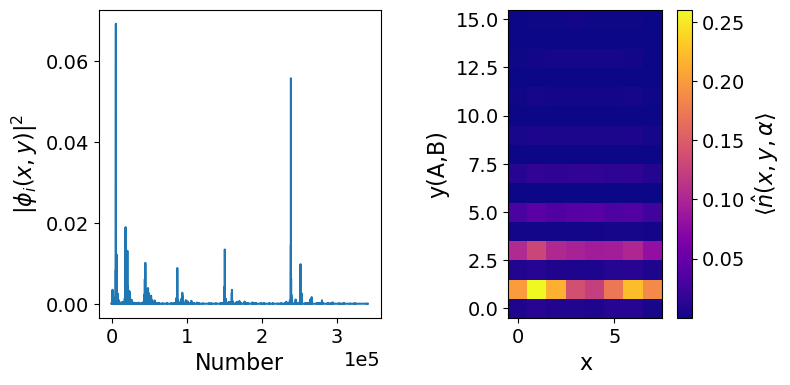

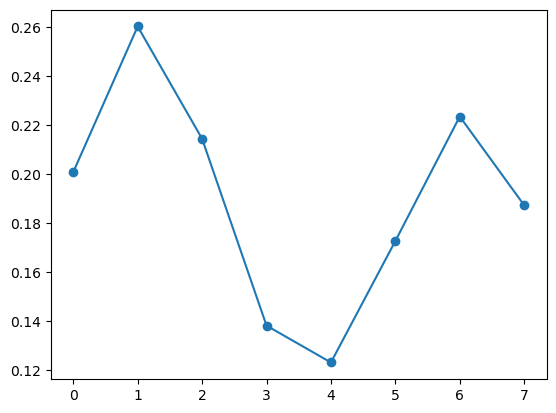

In [12]:
import numpy as np
import matplotlib.pyplot as plt
with np.load('ThreeExcitationEig8.npz') as files:
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']

num_x = 8
num_y = 8
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem_Coo
QWZ2 = ParticleConservedSystem_Coo(num_x, num_y, 3)
popu_indice = QWZ2.Calcu_Occup()
basis = QWZ2.basis
popu_eig2 = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    #print(temp_state[popu_indice[k]])
    popu_eig2[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 

from ComputationalPhysics.Package.BitOperation import ReadBit
for i in range(len(eigvec_NHMany[:,-1])):
    if np.abs(eigvec_NHMany[i,-1])**2>0.015:
        print(i, bin(basis[i]))
        for j in range(2*8*8):
            if ReadBit(basis[i], j)==1:
                print(j)

color_string = 'plasma'
labelsize = 14
fontsize = 16
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].plot(np.abs(eigvec_NHMany[:,-1])**2)
ax[0].set_xlabel('Number', fontsize=fontsize)
ax[0].set_ylabel(r'$\vert \phi_i(x,y)\vert^2$', fontsize=fontsize)
ax[0].ticklabel_format(style='sci', axis='x', scilimits=(0,0))
ax[0].tick_params(axis='both', which='major', labelsize=labelsize)
ax[1].tick_params(axis='both', which='major', labelsize=labelsize)
# 获取当前子图的y轴偏移文本
offset_text = ax[0].get_xaxis().get_offset_text()
# 设置字体大小为12
offset_text.set_fontsize(labelsize)

a = popu_eig2.reshape(num_x, 2*num_y).T
im1 = ax[1].imshow(a, cmap=color_string, origin='lower')
ax[1].set_xlabel('x', fontsize=fontsize)
ax[1].set_ylabel('y(A,B)', fontsize=fontsize)

# ax[1].colorbar(cmap=color_string)
cbar1 = fig.colorbar(im1, ax=ax[1], cmap=color_string)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.set_ylabel(r'$\langle \hat{n}(x,y,\alpha\rangle$', fontsize=fontsize)
plt.show()
fig.savefig('DataPicture/SI_ThreeExcitationSize8.pdf', bbox_inches='tight') # ,

plt.plot(a[1], 'o-')
plt.show()

## 补充演化对应的能谱和本征态

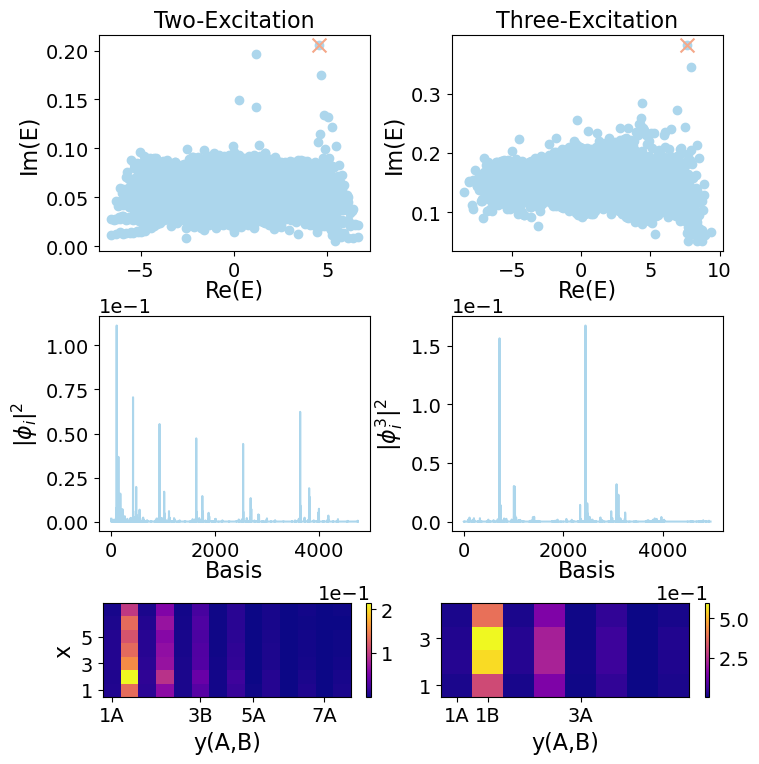

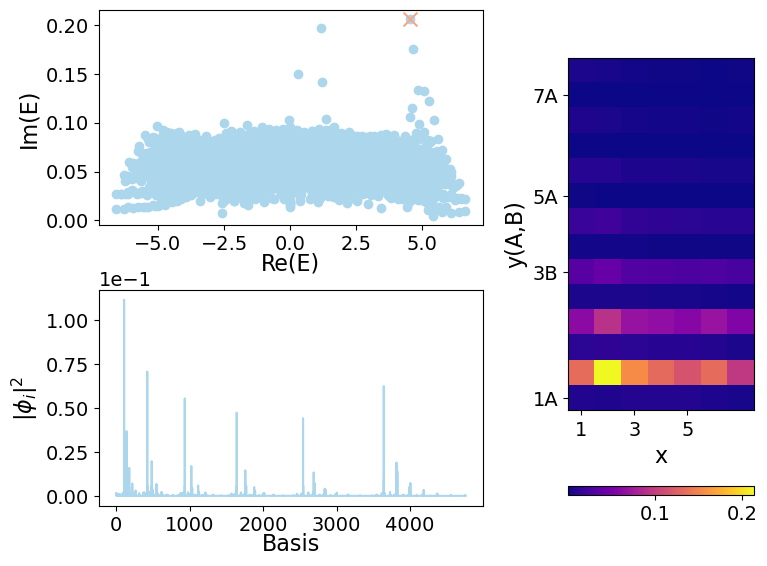

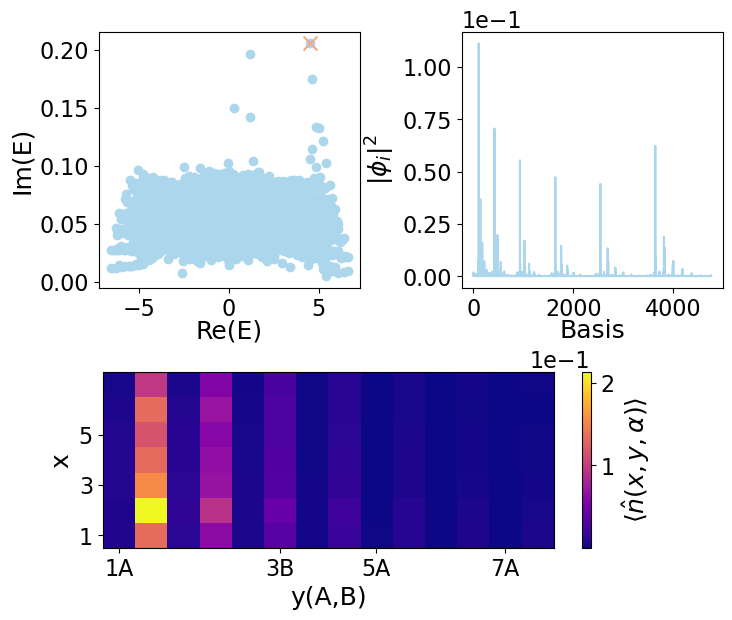

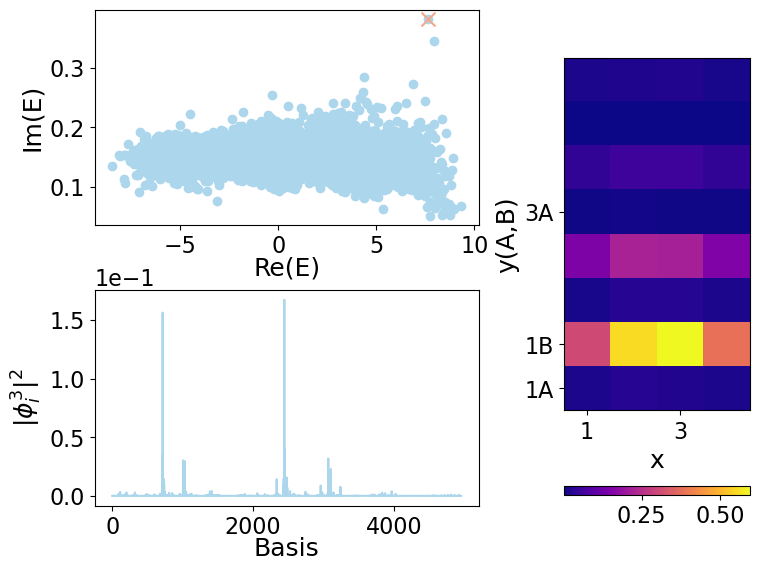

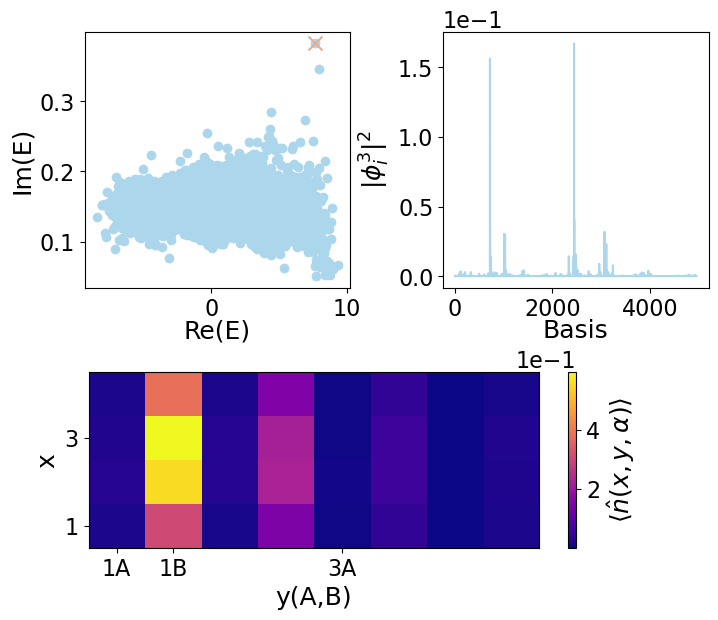

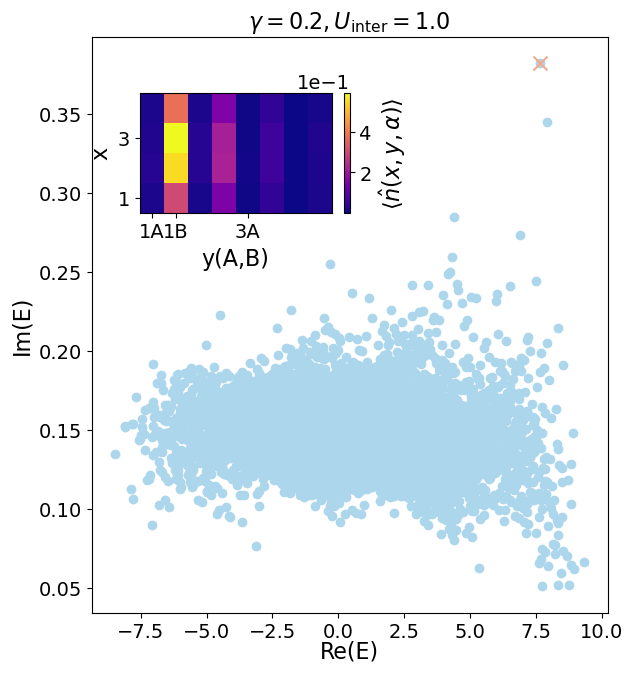

In [124]:
import numpy as np
import matplotlib.pyplot as plt
color_r = '#F5A889'
color_b = '#ACD6EC'
import h5py
file1 = h5py.File('TwoExcitationEig7.h5', 'r')  # 'r'表示只读模式
file2 = h5py.File('ThreeExcitationEig4.h5', 'r')  # 'r'表示只读模式

Lx1, Ly1 = 7, 7
Lx2, Ly2 = 4, 4

fontsize = 16
labelsize= 14
labelpad = -1
fig, ax = plt.subplots(2,2,figsize=(8, 8))
# ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(file1['eigval_NHMany'][:].real, file1['eigval_NHMany'][:].imag, color=color_b)
ax[0, 0].scatter(file1['eigval_NHMany'][:][-1].real, file1['eigval_NHMany'][:][-1].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(file2['eigval_NHMany'][:].real, file2['eigval_NHMany'][:].imag, color=color_b)
ax[0, 1].scatter(file2['eigval_NHMany'][:][-1].real, file2['eigval_NHMany'][:][-1].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize, labelpad=labelpad)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize,labelpad=labelpad)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)
ax[0, 1].set_ylabel('Im(E)',fontsize=fontsize)
basis_num1 = len(file1['eigvec_NHMany'][:][:,-1])
basis_num2 = len(file2['eigvec_NHMany'][:][:,-1])

ax[1, 0].plot(np.arange(1,basis_num1+1), np.abs(file1['eigvec_NHMany'][:][:,-1])**2, color=color_b)
ax[1, 1].plot(np.arange(1,basis_num2+1), np.abs(file2['eigvec_NHMany'][:][:,-1])**2, color=color_b)
ax[1, 0].set_xlabel('Basis', fontsize=fontsize, labelpad=labelpad)
ax[1, 1].set_xlabel('Basis', fontsize=fontsize, labelpad=labelpad)
ax[1, 0].set_ylabel(r'$\vert \phi_i\vert^2$',fontsize=fontsize)
ax[1, 1].set_ylabel(r'$\vert \phi_i^3\vert^2$',fontsize=fontsize)
for row in range(2):
    for col in range(2):
        # ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
for col in range(2):
    ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = ax[row, col].get_yaxis().get_offset_text()
    # 设置字体大小为12
    offset_text.set_fontsize(labelsize)
ax[0, 0].set_title('Two-Excitation', fontsize=fontsize)
ax[0, 1].set_title('Three-Excitation', fontsize=fontsize)

popu1 = file1['popu_NHMany'][:].reshape(Lx1, 2*Ly1)
popu2 = file2['popu_NHMany'][:].reshape(Lx2, 2*Ly2)
pos1 = ax[1, 0].get_position()
pos2 = ax[1, 1].get_position()
plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.3,
    top=0.92,
    hspace=0.3,
    wspace=0.3
)
gap = -0.1
ax3 = fig.add_axes([pos1.x0, pos1.y0 - gap - pos1.height/3, pos1.width*1.1, pos1.height/3])
ax4 = fig.add_axes([pos2.x0, pos2.y0 - gap - pos1.height/3, pos2.width*1.1, pos1.height/3])
vmin, vmax = np.min([np.min(popu1), np.min(popu2)]), np.max([np.max(popu1), np.max(popu2)]) # 但是这样颜色会看不出来。
color_string = 'plasma'
im1  = ax3.imshow(popu1, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
im2 = ax4.imshow(popu2, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
# vmin=vmin,vmax=vmax,
ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax4.set_xlabel('y(A,B)', fontsize=fontsize)
ax3.set_ylabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
ax3.set_xticks(ticks=[0, 5, 8, 12], labels=['1A', '3B', '5A', '7A'])
ax4.set_xticks(ticks=[0, 1, 4], labels=['1A', '1B', '3A'])
ax3.set_yticks(ticks=[0,2,4], labels=[1,3,5])
ax4.set_yticks(ticks=[0,2], labels=[1,3])

cbar1 = plt.colorbar(im1, ax=ax3, fraction=0.15)  # 关联到第一个axes
cbar2 = plt.colorbar(im2, ax=ax4, fraction=0.15)  # 关联到第一个axes
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar2.ax.tick_params(axis='both', which='major', labelsize=labelsize)
# cbar用科学计数法，并加大字体
cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar1.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)
cbar2.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar2.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)


# fig.savefig("DataPicture/SI_EvolveSpectrum.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()




fig, ax = plt.subplots(2,1,figsize=(8, 8))
# ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0].scatter(file1['eigval_NHMany'][:].real, file1['eigval_NHMany'][:].imag, color=color_b)
ax[0].scatter(file1['eigval_NHMany'][:][-1].real, file1['eigval_NHMany'][:][-1].imag, color=color_r, s=100, marker='x')
ax[1].plot(np.arange(1,basis_num1+1), np.abs(file1['eigvec_NHMany'][:][:,-1])**2, color=color_b)
ax[0].set_xlabel('Re(E)',fontsize=fontsize, labelpad=labelpad)
ax[1].set_xlabel('Basis',fontsize=fontsize,labelpad=labelpad)
ax[0].set_ylabel('Im(E)',fontsize=fontsize)
ax[1].set_ylabel(r'$\vert \phi_i \vert^2$',fontsize=fontsize)
basis_num1 = len(file1['eigvec_NHMany'][:][:,-1])
basis_num2 = len(file2['eigvec_NHMany'][:][:,-1])

for row in range(2):
    # ax[row, col].grid(True, linestyle='--', alpha=0.7)
    ax[row].tick_params(axis='both', which='major', labelsize=labelsize)
ax[1].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = ax[1].get_yaxis().get_offset_text()
# 设置字体大小为12
offset_text.set_fontsize(labelsize)
# ax[0].set_title('Two-Excitation', fontsize=fontsize)
# ax[1].set_title('Three-Excitation', fontsize=fontsize)

popu1 = file1['popu_NHMany'][:].reshape(Lx1, 2*Ly1)
popu2 = file2['popu_NHMany'][:].reshape(Lx2, 2*Ly2)
pos1 = ax[0].get_position()
pos2 = ax[1].get_position()
plt.subplots_adjust(
    left=0.12,
    right=0.6,
    bottom=0.3,
    top=0.92,
    hspace=0.3,
    wspace=0.3
)
gap = -0.05
ax3 = fig.add_axes([pos1.x0 + 3*pos1.width/4, pos1.y0 - gap - pos1.height, pos1.width*0.3, pos1.height*1.8])
vmin, vmax = np.min([np.min(popu1), np.min(popu2)]), np.max([np.max(popu1), np.max(popu2)]) # 但是这样颜色会看不出来。
color_string = 'plasma'
im1  = ax3.imshow(popu1.T, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
# vmin=vmin,vmax=vmax,
ax3.set_ylabel('y(A,B)', fontsize=fontsize)
ax3.set_xlabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax3.set_yticks(ticks=[0, 5, 8, 12], labels=['1A', '3B', '5A', '7A'])
ax3.set_xticks(ticks=[0,2,4], labels=[1,3,5])

cbar1 = plt.colorbar(im1, ax=ax3, orientation='horizontal')  # 关联到第一个axes
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
# cbar用科学计数法，并加大字体
cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar1.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)

fig.savefig("DataPicture/SI_EvolveSpectrum2.pdf", bbox_inches='tight') # , 
plt.show()


# 2 
fontsize = 18
labelsize = 16
fig, ax = plt.subplots(1, 2, figsize=(8, 8))
# ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0].scatter(file1['eigval_NHMany'][:].real, file1['eigval_NHMany'][:].imag, color=color_b)
ax[0].scatter(file1['eigval_NHMany'][:][-1].real, file1['eigval_NHMany'][:][-1].imag, color=color_r, s=100, marker='x')
ax[1].plot(np.arange(1,basis_num1+1), np.abs(file1['eigvec_NHMany'][:][:,-1])**2, color=color_b)
ax[0].set_xlabel('Re(E)',fontsize=fontsize, labelpad=labelpad)
ax[1].set_xlabel('Basis',fontsize=fontsize,labelpad=labelpad)
ax[0].set_ylabel('Im(E)',fontsize=fontsize)
ax[1].set_ylabel(r'$\vert \phi_i \vert^2$',fontsize=fontsize)
basis_num1 = len(file1['eigvec_NHMany'][:][:,-1])
basis_num2 = len(file2['eigvec_NHMany'][:][:,-1])

for row in range(2):
    # ax[row, col].grid(True, linestyle='--', alpha=0.7)
    ax[row].tick_params(axis='both', which='major', labelsize=labelsize)
ax[1].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = ax[1].get_yaxis().get_offset_text()
# 设置字体大小为12
offset_text.set_fontsize(labelsize)
# ax[0].set_title('Two-Excitation', fontsize=fontsize)
# ax[1].set_title('Three-Excitation', fontsize=fontsize)

popu1 = file1['popu_NHMany'][:].reshape(Lx1, 2*Ly1)
popu2 = file2['popu_NHMany'][:].reshape(Lx2, 2*Ly2)
pos1 = ax[0].get_position()
pos2 = ax[1].get_position()
plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.6,
    top=0.92,
    hspace=0.3,
    wspace=0.39
)
gap = -0.05
ax3 = fig.add_axes([pos1.x0, pos1.y0 + 0.165, pos1.width*2, pos1.height/3.5])
vmin, vmax = np.min([np.min(popu1), np.min(popu2)]), np.max([np.max(popu1), np.max(popu2)]) # 但是这样颜色会看不出来。
color_string = 'plasma'
im1  = ax3.imshow(popu1, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
# vmin=vmin,vmax=vmax,
ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax3.set_ylabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax3.set_xticks(ticks=[0, 5, 8, 12], labels=['1A', '3B', '5A', '7A'])
ax3.set_yticks(ticks=[0,2,4], labels=[1,3,5])

cbar1 = plt.colorbar(im1, ax=ax3)  # 关联到第一个axes
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.set_ylabel(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize=fontsize)
# cbar用科学计数法，并加大字体
cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar1.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)

fig.savefig("DataPicture/SI_EvolveSpectrum2.pdf", bbox_inches='tight') # , 
plt.show()


# 3
fig, ax = plt.subplots(2,1,figsize=(8, 8))
# ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0].scatter(file2['eigval_NHMany'][:].real, file2['eigval_NHMany'][:].imag, color=color_b)
ax[0].scatter(file2['eigval_NHMany'][:][-1].real, file2['eigval_NHMany'][:][-1].imag, color=color_r, s=100, marker='x')
ax[1].plot(np.arange(1,basis_num2+1), np.abs(file2['eigvec_NHMany'][:][:,-1])**2, color=color_b)
ax[0].set_xlabel('Re(E)',fontsize=fontsize, labelpad=labelpad)
ax[1].set_xlabel('Basis',fontsize=fontsize,labelpad=labelpad)
ax[0].set_ylabel('Im(E)',fontsize=fontsize)
ax[1].set_ylabel(r'$\vert \phi_i^3 \vert^2$',fontsize=fontsize)
basis_num1 = len(file1['eigvec_NHMany'][:][:,-1])
basis_num2 = len(file2['eigvec_NHMany'][:][:,-1])

for row in range(2):
    # ax[row, col].grid(True, linestyle='--', alpha=0.7)
    ax[row].tick_params(axis='both', which='major', labelsize=labelsize)
ax[1].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = ax[1].get_yaxis().get_offset_text()
# 设置字体大小为12
offset_text.set_fontsize(labelsize)
# ax[0].set_title('Two-Excitation', fontsize=fontsize)
# ax[1].set_title('Three-Excitation', fontsize=fontsize)

popu1 = file1['popu_NHMany'][:].reshape(Lx1, 2*Ly1)
popu2 = file2['popu_NHMany'][:].reshape(Lx2, 2*Ly2)
pos1 = ax[0].get_position()
pos2 = ax[1].get_position()
plt.subplots_adjust(
    left=0.12,
    right=0.6,
    bottom=0.3,
    top=0.92,
    hspace=0.3,
    wspace=0.3
)
gap = -0.05
ax3 = fig.add_axes([pos1.x0 + 3*pos1.width/4, pos1.y0 - gap - pos1.height, pos1.width*0.3, pos1.height*1.8])
vmin, vmax = np.min([np.min(popu1), np.min(popu2)]), np.max([np.max(popu1), np.max(popu2)]) # 但是这样颜色会看不出来。
color_string = 'plasma'
im1  = ax3.imshow(popu2.T, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
# vmin=vmin,vmax=vmax,
ax3.set_ylabel('y(A,B)', fontsize=fontsize)
ax3.set_xlabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax3.set_yticks(ticks=[0, 1, 4], labels=['1A', '1B', '3A'])
ax3.set_xticks(ticks=[0,2], labels=[1,3])

cbar1 = plt.colorbar(im1, ax=ax3, orientation='horizontal')  # 关联到第一个axes
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
# cbar用科学计数法，并加大字体
cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar1.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)

fig.savefig("DataPicture/SI_EvolveSpectrum3.pdf", bbox_inches='tight') # , 
plt.show()



# 4
fontsize = 18
labelsize = 16
fig, ax = plt.subplots(1, 2, figsize=(8, 8))
# ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0].scatter(file2['eigval_NHMany'][:].real, file2['eigval_NHMany'][:].imag, color=color_b)
ax[0].scatter(file2['eigval_NHMany'][:][-1].real, file2['eigval_NHMany'][:][-1].imag, color=color_r, s=100, marker='x')
ax[1].plot(np.arange(1,basis_num2+1), np.abs(file2['eigvec_NHMany'][:][:,-1])**2, color=color_b)
ax[0].set_xlabel('Re(E)',fontsize=fontsize, labelpad=labelpad)
ax[1].set_xlabel('Basis',fontsize=fontsize,labelpad=labelpad)
ax[0].set_ylabel('Im(E)',fontsize=fontsize)
ax[1].set_ylabel(r'$\vert \phi_i^3 \vert^2$',fontsize=fontsize)
basis_num1 = len(file1['eigvec_NHMany'][:][:,-1])
basis_num2 = len(file2['eigvec_NHMany'][:][:,-1])

for row in range(2):
    # ax[row, col].grid(True, linestyle='--', alpha=0.7)
    ax[row].tick_params(axis='both', which='major', labelsize=labelsize)
ax[1].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = ax[1].get_yaxis().get_offset_text()
# 设置字体大小为12
offset_text.set_fontsize(labelsize)
# ax[0].set_title('Two-Excitation', fontsize=fontsize)
# ax[1].set_title('Three-Excitation', fontsize=fontsize)

popu1 = file1['popu_NHMany'][:].reshape(Lx1, 2*Ly1)
popu2 = file2['popu_NHMany'][:].reshape(Lx2, 2*Ly2)
pos1 = ax[0].get_position()
pos2 = ax[1].get_position()
plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.6,
    top=0.92,
    hspace=0.3,
    wspace=0.35
)
gap = -0.05
ax3 = fig.add_axes([pos1.x0, pos1.y0 + 0.165, pos1.width*2, pos1.height/3.5])
vmin, vmax = np.min([np.min(popu1), np.min(popu2)]), np.max([np.max(popu1), np.max(popu2)]) # 但是这样颜色会看不出来。
color_string = 'plasma'
im1  = ax3.imshow(popu2, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
# vmin=vmin,vmax=vmax,
ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax3.set_ylabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax3.set_xticks(ticks=[0, 1, 4], labels=['1A', '1B', '3A'])
ax3.set_yticks(ticks=[0,2], labels=[1,3])

cbar1 = plt.colorbar(im1, ax=ax3)  # 关联到第一个axes
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.set_ylabel(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize = fontsize)
# cbar用科学计数法，并加大字体
cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar1.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)

fig.savefig("DataPicture/SI_EvolveSpectrum3.pdf", bbox_inches='tight') # , 
plt.show()



# 
fontsize = 16
labelsize = 14
fig, ax = plt.subplots(figsize=(6, 8))
# ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax.scatter(file2['eigval_NHMany'][:].real, file2['eigval_NHMany'][:].imag, color=color_b)
ax.scatter(file2['eigval_NHMany'][:][-1].real, file2['eigval_NHMany'][:][-1].imag, color=color_r, s=100, marker='x')
ax.set_xlabel('Re(E)',fontsize=fontsize, labelpad=labelpad)
ax.set_ylabel('Im(E)',fontsize=fontsize)
ax.tick_params(axis='both', which='major', labelsize=labelsize)
basis_num1 = len(file1['eigvec_NHMany'][:][:,-1])
ax.set_title(r'$\gamma=0.2,U_{\mathrm{inter}}=1.0$', fontsize=fontsize)
basis_num2 = len(file2['eigvec_NHMany'][:][:,-1])

# for row in range(2):
#     # ax[row, col].grid(True, linestyle='--', alpha=0.7)
#     ax[row].tick_params(axis='both', which='major', labelsize=labelsize)
# # offset_text = ax[1].get_yaxis().get_offset_text()
# 设置字体大小为12
offset_text.set_fontsize(labelsize)
# ax[0].set_title('Two-Excitation', fontsize=fontsize)
# ax[1].set_title('Three-Excitation', fontsize=fontsize)

popu1 = file1['popu_NHMany'][:].reshape(Lx1, 2*Ly1)
popu2 = file2['popu_NHMany'][:].reshape(Lx2, 2*Ly2)
ax3 = fig.add_axes([0.2, 0.7, 0.4, 0.15]) 

# ax3 = fig.add_axes([pos1.x0, pos1.y0 + 0.165, pos1.width*2, pos1.height/3.5])
vmin, vmax = np.min([np.min(popu1), np.min(popu2)]), np.max([np.max(popu1), np.max(popu2)]) # 但是这样颜色会看不出来。
color_string = 'plasma'
im1  = ax3.imshow(popu2, aspect='auto', origin='lower', cmap=color_string)
# vmin=vmin,vmax=vmax,
ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax3.set_ylabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax3.set_xticks(ticks=[0, 1, 4], labels=['1A', '1B', '3A'])
ax3.set_yticks(ticks=[0,2], labels=[1,3])

cbar1 = plt.colorbar(im1, ax=ax3)  # 关联到第一个axes
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.set_ylabel(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize = fontsize)
# cbar用科学计数法，并加大字体
cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar1.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)

plt.subplots_adjust(
    left=0.12,
    right=0.98,
    bottom=0.2,
    top=0.92,
    hspace=0.3,
    wspace=0.35
)
fig.savefig("DataPicture/ThreeExitation_L4_Spectrum.pdf", bbox_inches='tight') # , 
plt.show()

## 当耗散不再边界的时候

Processing no interaction:
Processing interaction:


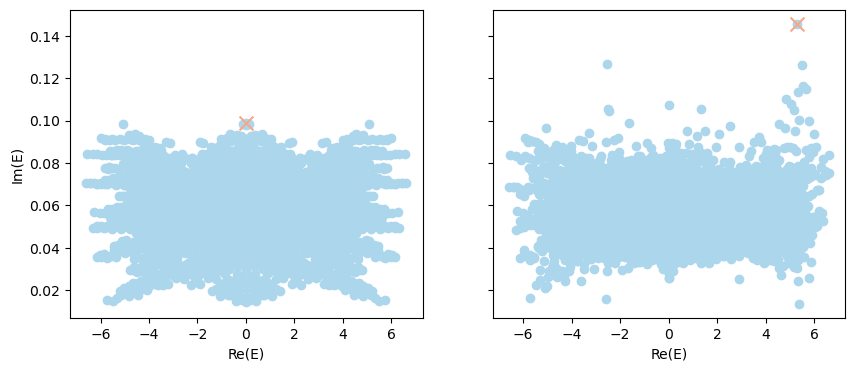

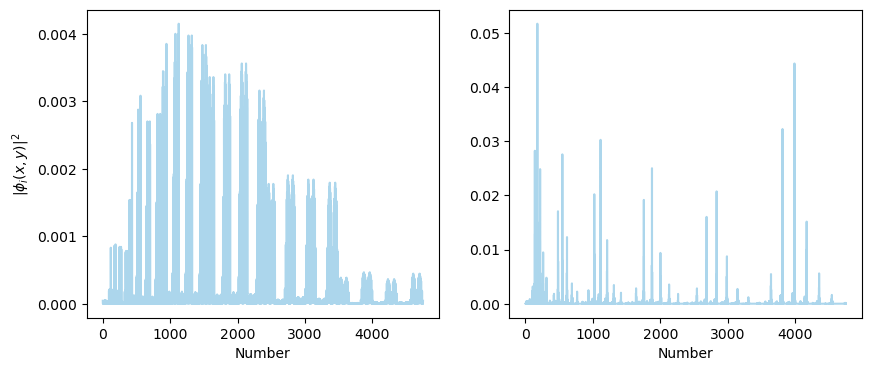

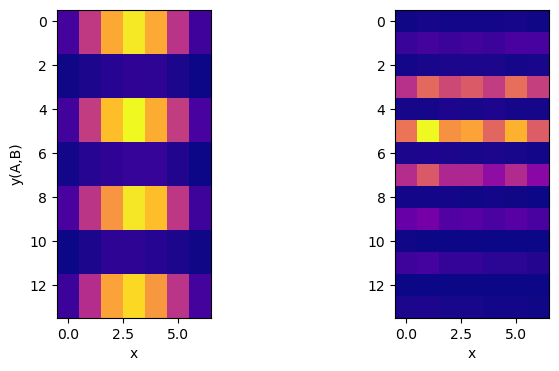

In [14]:
color_r = '#F5A889'
color_b = '#ACD6EC'
num_x = 7 # 可以算更大体系。
num_y = 7
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
import numpy as np
import matplotlib.pyplot as plt
which_y_dissi = 2 # 其实就是在y=5
# 1.非厄米
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
QWZ2.add_onsite_term(-1.5)
QWZ2.add_NH(0.2, which_dissi=which_y_dissi)
QWZ2.add_xhopping_term()
QWZ2.add_yhopping_term()
# QWZ2.add_interaction_inter(1.)
popu_indice = QWZ2.Calcu_Occup()
hamiltonian = QWZ2.hamiltonian
print('Processing no interaction:')
eigval, eigvec = np.linalg.eig(hamiltonian)
eigvec = eigvec[:, np.argsort(np.imag(eigval))]
eigval = eigval[np.argsort(np.imag(eigval))]
popu_eig = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    #print(temp_state[popu_indice[k]])
    popu_eig[k] = np.sum(np.abs(eigvec[popu_indice[k],-1])**2) 

# 2.非厄米+多体
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
QWZ2.add_onsite_term(-1.5)
QWZ2.add_NH(0.2, which_dissi=which_y_dissi)
QWZ2.add_xhopping_term()
QWZ2.add_yhopping_term()
QWZ2.add_interaction_inter(1.)
popu_indice = QWZ2.Calcu_Occup()
hamiltonian = QWZ2.hamiltonian
print('Processing interaction:')
eigval2, eigvec2 = np.linalg.eig(hamiltonian)  # 大概40min
eigvec2 = eigvec2[:, np.argsort(np.imag(eigval2))]
eigval2 = eigval2[np.argsort(np.imag(eigval2))]
popu_eig2 = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    #print(temp_state[popu_indice[k]])
    popu_eig2[k] = np.sum(np.abs(eigvec2[popu_indice[k],-1])**2) 

# # 3.多体
# QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
# QWZ2.add_onsite_term(-1.5)
# # QWZ2.add_NH(0.2)
# QWZ2.add_xhopping_term()
# QWZ2.add_yhopping_term()
# QWZ2.add_interaction_inter(1.)
# popu_indice = QWZ2.Calcu_Occup()
# hamiltonian = QWZ2.hamiltonian
# print('Processing interaction:')
# eigval3, eigvec3 = np.linalg.eig(hamiltonian)  # 大概40min
# eigvec3 = eigvec3[:, np.argsort(np.imag(eigval3))]
# eigval3 = eigval3[np.argsort(np.imag(eigval3))]
# popu_eig3 = np.zeros(QWZ2.total_mode)
# for k in range(2*num_x*num_y): # 应该要加2。
#     #print(temp_state[popu_indice[k]])
#     popu_eig3[k] = np.sum(np.abs(eigvec3[popu_indice[k],-1])**2) 

fig, ax = plt.subplots(1,2,figsize=(10, 4),sharex=True, sharey=True)
ax[0].scatter(eigval.real, eigval.imag, color=color_b)
ax[0].scatter(eigval[-1].real, eigval[-1].imag, color=color_r, s=100, marker='x')
ax[1].scatter(eigval2.real, eigval2.imag, color=color_b)
ax[1].scatter(eigval2[-1].real, eigval2[-1].imag, color=color_r, s=100, marker='x')
# ax[2].scatter(eigval3.real, eigval3.imag, color=color_b)
# ax[2].scatter(eigval3[-1].real, eigval3[-1].imag, color=color_r, s=100, marker='x')
ax[0].set_xlabel('Re(E)')
ax[1].set_xlabel('Re(E)')
# ax[2].set_xlabel('Re(E)')
ax[0].set_ylabel('Im(E)')
plt.show()

fig, ax = plt.subplots(1,2,figsize=(10, 4))
ax[0].plot(np.abs(eigvec[:,-1])**2, color=color_b)
ax[1].plot(np.abs(eigvec2[:,-1])**2, color=color_b)
# ax[2].plot(np.abs(eigvec3[:,-1])**2, color=color_b)
ax[0].set_xlabel('Number')
ax[1].set_xlabel('Number')
# ax[2].set_xlabel('Number')
ax[0].set_ylabel(r'$\vert \phi_i(x,y)\vert^2$')
plt.show()

color_string = 'plasma' # Reds.
fig, ax = plt.subplots(1,2,figsize=(8, 4))
ax[0].imshow(popu_eig.reshape(num_x, 2*num_y).T, cmap=color_string)
ax[1].imshow(popu_eig2.reshape(num_x, 2*num_y).T, cmap=color_string)
# ax[2].imshow(popu_eig3.reshape(num_x, 2*num_y).T, cmap=color_string)
ax[0].set_xlabel('x')
ax[1].set_xlabel('x')
ax[0].set_ylabel('y(A,B)')
plt.show()
# 第一在不同位置加耗散。诱导不同位置的激发。
# 看一下三体的。
# 看一下对称性，iPT

In [ ]:
# 当是耗散的时候是否存在对称性？就是直接厄密共轭。
color_r = '#F5A889'
color_b = '#ACD6EC'
num_x = 9 # 可以算更大体系。
num_y = 9
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
import numpy as np
import matplotlib.pyplot as plt
which_y_dissi = 0 # 其实就是在y=5
gamma = -0.2
plot_which = 0 # -1 for max imaginary
# 1.非厄米
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
QWZ2.add_onsite_term(-1.5)
QWZ2.add_NH(gamma, which_dissi=which_y_dissi)
QWZ2.add_xhopping_term()
QWZ2.add_yhopping_term()
# QWZ2.add_interaction_inter(1.)
popu_indice = QWZ2.Calcu_Occup()
hamiltonian = QWZ2.hamiltonian
print('Processing no interaction:')
eigval, eigvec = np.linalg.eig(hamiltonian)
eigvec = eigvec[:, np.argsort(np.imag(eigval))]
eigval = eigval[np.argsort(np.imag(eigval))]
popu_eig = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    #print(temp_state[popu_indice[k]])
    popu_eig[k] = np.sum(np.abs(eigvec[popu_indice[k],plot_which])**2) 

# 2.非厄米+多体
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
QWZ2.add_onsite_term(-1.5)
QWZ2.add_NH(gamma, which_dissi=which_y_dissi)
QWZ2.add_xhopping_term()
QWZ2.add_yhopping_term()
QWZ2.add_interaction_inter(1.)
popu_indice = QWZ2.Calcu_Occup()
hamiltonian = QWZ2.hamiltonian
print('Processing interaction:')
eigval2, eigvec2 = np.linalg.eig(hamiltonian)  # 大概40min
eigvec2 = eigvec2[:, np.argsort(np.imag(eigval2))]
eigval2 = eigval2[np.argsort(np.imag(eigval2))]
popu_eig2 = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    #print(temp_state[popu_indice[k]])
    popu_eig2[k] = np.sum(np.abs(eigvec2[popu_indice[k],plot_which])**2) 

# # 3.多体
# QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
# QWZ2.add_onsite_term(-1.5)
# # QWZ2.add_NH(0.2)
# QWZ2.add_xhopping_term()
# QWZ2.add_yhopping_term()
# QWZ2.add_interaction_inter(1.)
# popu_indice = QWZ2.Calcu_Occup()
# hamiltonian = QWZ2.hamiltonian
# print('Processing interaction:')
# eigval3, eigvec3 = np.linalg.eig(hamiltonian)  # 大概40min
# eigvec3 = eigvec3[:, np.argsort(np.imag(eigval3))]
# eigval3 = eigval3[np.argsort(np.imag(eigval3))]
# popu_eig3 = np.zeros(QWZ2.total_mode)
# for k in range(2*num_x*num_y): # 应该要加2。
#     #print(temp_state[popu_indice[k]])
#     popu_eig3[k] = np.sum(np.abs(eigvec3[popu_indice[k],-1])**2) 

plot_which = 0 # -1 for max imaginary

fig, ax = plt.subplots(1,2,figsize=(10, 4),sharex=True, sharey=True)
ax[0].scatter(eigval.real, eigval.imag, color=color_b)
ax[0].scatter(eigval[plot_which].real, eigval[plot_which].imag, color=color_r, s=100, marker='x')
ax[1].scatter(eigval2.real, eigval2.imag, color=color_b)
ax[1].scatter(eigval2[plot_which].real, eigval2[plot_which].imag, color=color_r, s=100, marker='x')
# ax[2].scatter(eigval3.real, eigval3.imag, color=color_b)
# ax[2].scatter(eigval3[-1].real, eigval3[-1].imag, color=color_r, s=100, marker='x')
ax[0].set_xlabel('Re(E)')
ax[1].set_xlabel('Re(E)')
# ax[2].set_xlabel('Re(E)')
ax[0].set_ylabel('Im(E)')
plt.show()

fig, ax = plt.subplots(1,2,figsize=(10, 4))
ax[0].plot(np.abs(eigvec[:,plot_which])**2, color=color_b)
ax[1].plot(np.abs(eigvec2[:,plot_which])**2, color=color_b)
# ax[2].plot(np.abs(eigvec3[:,-1])**2, color=color_b)
ax[0].set_xlabel('Number')
ax[1].set_xlabel('Number')
# ax[2].set_xlabel('Number')
ax[0].set_ylabel(r'$\vert \phi_i(x,y)\vert^2$')
plt.show()

color_string = 'plasma' # Reds.
fig, ax = plt.subplots(1,2,figsize=(8, 4))
ax[0].imshow(popu_eig.reshape(num_x, 2*num_y).T, cmap=color_string)
ax[1].imshow(popu_eig2.reshape(num_x, 2*num_y).T, cmap=color_string)
# ax[2].imshow(popu_eig3.reshape(num_x, 2*num_y).T, cmap=color_string)
ax[0].set_xlabel('x')
ax[1].set_xlabel('x')
ax[0].set_ylabel('y(A,B)')
plt.show()
# 第一在不同位置加耗散。诱导不同位置的激发。
# 看一下三体的。
# 看一下对称性，iPT

Processing no interaction:


## 当本身不是拓扑绝缘体的时候

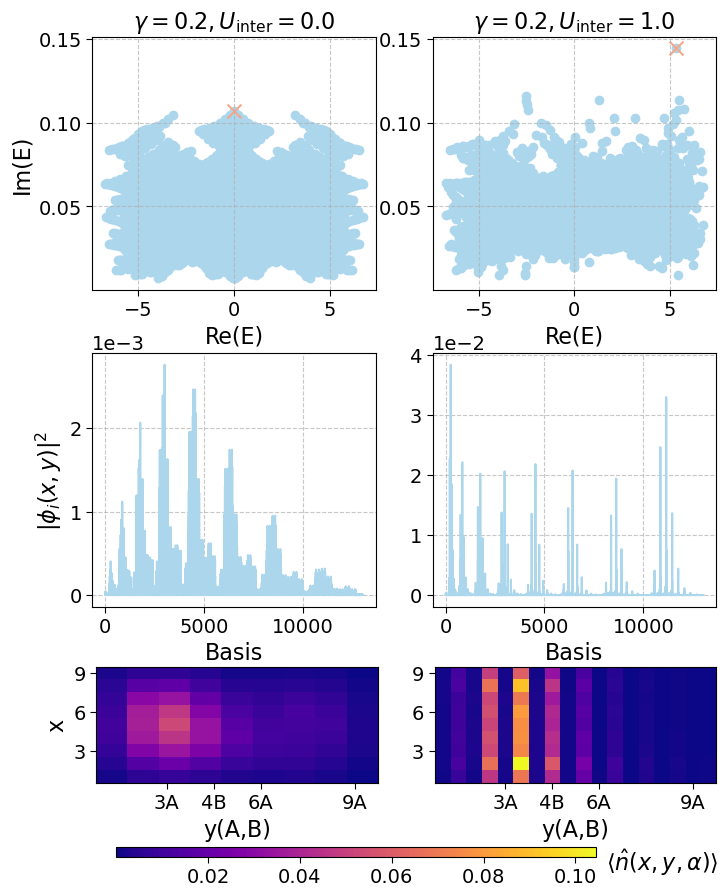

In [266]:
import numpy as np
import matplotlib.pyplot as plt
color_r = '#F5A889'
color_b = '#ACD6EC'
with np.load('TwoExcitationEig9_NotEdge.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']
num_x, num_y = 9, 9
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
popu_indice = QWZ2.Calcu_Occup()
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k],-1])**2) 
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 

fontsize = 16
labelsize= 14
fig, ax = plt.subplots(2,2,figsize=(8, 10), sharex='row')
ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[-1].real, eigval_NH[-1].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)

ax[1, 0].plot(np.abs(eigvec_NH[:,-1])**2, color=color_b)
ax[1, 1].plot(np.abs(eigvec_NHMany[:,-1])**2, color=color_b)
ax[1, 0].set_xlabel('Basis',fontsize=fontsize)
ax[1, 1].set_xlabel('Basis',fontsize=fontsize)
ax[1, 0].set_ylabel(r'$\vert \phi_i(x,y)\vert^2$',fontsize=fontsize)
for row in range(2):
    for col in range(2):
        ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
for col in range(2):
    ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = ax[row, col].get_yaxis().get_offset_text()
    # 设置字体大小为12
    offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=0.0$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=1.0$', fontsize=fontsize)

from scipy import ndimage
n_map1 = popu_NH.reshape(num_x, 2*num_y)
# 旋转90度
# rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
# 计算旋转后的坐标范围
n_map2 = popu_NHMany.reshape(num_x, 2*num_y)
# 旋转90度
# rotated_data2 = ndimage.rotate(n_map2, angle=90, reshape=True)
# 计算旋转后的坐标范围
color_string = 'plasma'
pos1 = ax[1, 0].get_position()
pos2 = ax[1, 1].get_position()
plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.35,
    top=0.92,
    hspace=0.25,
    wspace=0.2
)
gap = -0.18
ax3 = fig.add_axes([pos1.x0, pos1.y0 - gap - pos1.height/3, pos1.width, pos1.height/3])
ax4 = fig.add_axes([pos2.x0, pos2.y0 - gap - pos1.height/3, pos2.width, pos1.height/3])
vmin, vmax = np.min([np.min(popu_NH), np.min(popu_NHMany)]), np.max([np.max(popu_NH), np.max(popu_NHMany)]) # 但是这样颜色会看不出来。
sm  = ax3.imshow(n_map1, 
          aspect='auto',
          origin='lower',
          vmin=vmin,vmax=vmax,
          cmap=color_string)
ax4.imshow(n_map2, 
          aspect='auto',
          origin='lower',
          vmin=vmin,vmax=vmax,
          cmap=color_string)
ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax4.set_xlabel('y(A,B)', fontsize=fontsize)
ax3.set_ylabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
ax3.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
ax4.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
ax3.set_yticks(ticks=[2,5,8], labels=[3,6,9])
ax4.set_yticks(ticks=[2,5,8], labels=[3,6,9])

cax = fig.add_axes([0.15, 0.1, 0.6, 0.01]) # [左，下，宽，高]
cbar = plt.colorbar(
    sm,
    cax=cax,
    orientation='horizontal'
)
cax.tick_params(axis='both', which='major', labelsize=labelsize)
# cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
cax.text(cax.get_xlim()[-1]+0.002, cax.get_ylim()[-1], r'$\langle \hat{n}(x,y,\alpha) \rangle$', va='top', ha='left', fontsize=fontsize)
fig.savefig("DataPicture/SI_TwoExcitationSpectrum_NotEdge.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()

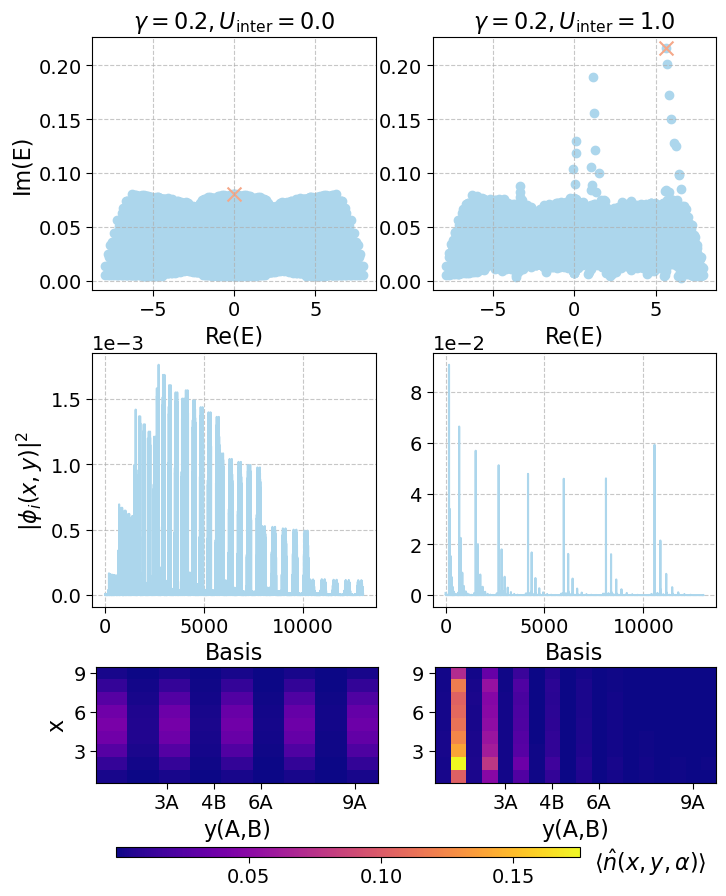

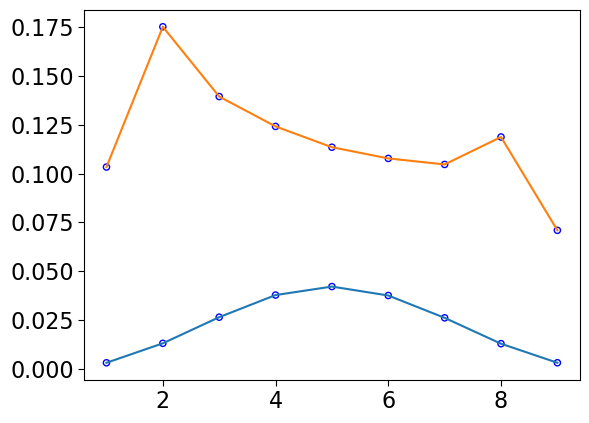

In [267]:
import numpy as np
import matplotlib.pyplot as plt
color_r = '#F5A889'
color_b = '#ACD6EC'
with np.load('TwoExcitationEig9_NotTopology.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']
num_x, num_y = 9, 9
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
popu_indice = QWZ2.Calcu_Occup()
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k],-1])**2) 
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 

fontsize = 16
labelsize= 14
fig, ax = plt.subplots(2,2,figsize=(8, 10), sharex='row')
ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[-1].real, eigval_NH[-1].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)

ax[1, 0].plot(np.abs(eigvec_NH[:,-1])**2, color=color_b)
ax[1, 1].plot(np.abs(eigvec_NHMany[:,-1])**2, color=color_b)
ax[1, 0].set_xlabel('Basis',fontsize=fontsize)
ax[1, 1].set_xlabel('Basis',fontsize=fontsize)
ax[1, 0].set_ylabel(r'$\vert \phi_i(x,y)\vert^2$',fontsize=fontsize)
for row in range(2):
    for col in range(2):
        ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
for col in range(2):
    ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = ax[row, col].get_yaxis().get_offset_text()
    # 设置字体大小为12
    offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=0.0$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=1.0$', fontsize=fontsize)

# 对于峰值的x方向进行一下label
# from ComputationalPhysics.Package.BitOperation import ReadBit
# threshold = 0.02
# for i in range(len(eigvec_NH[:,-1])):
#     if np.abs(eigvec_NHMany[i,-1])**2>threshold:
#         print(i, bin(basis[i]))
#         loc = []
#         for j in range(2*9*9):
#             if ReadBit(basis[i], j)==1:
#                 print(j)
#                 loc.append(j//(2*num_y)+1)
#         print(loc)
#         ax[1, 1].annotate(
#                 '(%d,%d)'%(loc[0], loc[1]),
#                 xy=(i, np.abs(eigvec_NHMany[i,-1])**2),  # 箭头指向的位置
#                 xytext=(i+100, np.abs(eigvec_NHMany[i,-1])**2+0.01),  # 文本的位置
#                 arrowprops=dict(facecolor='black', arrowstyle='->'),  # 箭头样式
#                 ha='center',
#                 va='bottom'
#             )


from scipy import ndimage
n_map1 = popu_NH.reshape(num_x, 2*num_y)
# 旋转90度
# rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
# 计算旋转后的坐标范围
n_map2 = popu_NHMany.reshape(num_x, 2*num_y)
# 旋转90度
# rotated_data2 = ndimage.rotate(n_map2, angle=90, reshape=True)
# 计算旋转后的坐标范围
color_string = 'plasma'
pos1 = ax[1, 0].get_position()
pos2 = ax[1, 1].get_position()
plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.35,
    top=0.92,
    hspace=0.25,
    wspace=0.2
)
gap = -0.18
ax3 = fig.add_axes([pos1.x0, pos1.y0 - gap - pos1.height/3, pos1.width, pos1.height/3])
ax4 = fig.add_axes([pos2.x0, pos2.y0 - gap - pos1.height/3, pos2.width, pos1.height/3])
vmin, vmax = np.min([np.min(popu_NH), np.min(popu_NHMany)]), np.max([np.max(popu_NH), np.max(popu_NHMany)]) # 但是这样颜色会看不出来。
sm  = ax3.imshow(n_map1, 
          aspect='auto',
          origin='lower',
          vmin=vmin,vmax=vmax,
          cmap=color_string)
ax4.imshow(n_map2, 
          aspect='auto',
          origin='lower',
          vmin=vmin,vmax=vmax,
          cmap=color_string)
ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax4.set_xlabel('y(A,B)', fontsize=fontsize)
ax3.set_ylabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
ax3.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
ax4.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
ax3.set_yticks(ticks=[2,5,8], labels=[3,6,9])
ax4.set_yticks(ticks=[2,5,8], labels=[3,6,9])

cax = fig.add_axes([0.15, 0.1, 0.58, 0.01]) # [左，下，宽，高]
cbar = plt.colorbar(
    sm,
    cax=cax,
    orientation='horizontal'
)
cax.tick_params(axis='both', which='major', labelsize=labelsize)
# cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
cax.text(cax.get_xlim()[-1]+0.005, cax.get_ylim()[-1], r'$\langle \hat{n}(x,y,\alpha) \rangle$', va='top', ha='left', fontsize=fontsize)
fig.savefig("DataPicture/SI_TwoExcitationSpectrum_NotTopology.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()

plt.scatter(np.arange(1,num_x+1, 1), n_map1[:,1], facecolors='none', edgecolors='blue', s=20)
plt.plot(np.arange(1,num_x+1, 1),n_map1[:,1])
plt.scatter(np.arange(1,num_x+1, 1), n_map2[:,1], facecolors='none', edgecolors='blue', s=20)
plt.plot(np.arange(1,num_x+1, 1),n_map2[:,1])
plt.show()

## 当相互作用是intra的时候

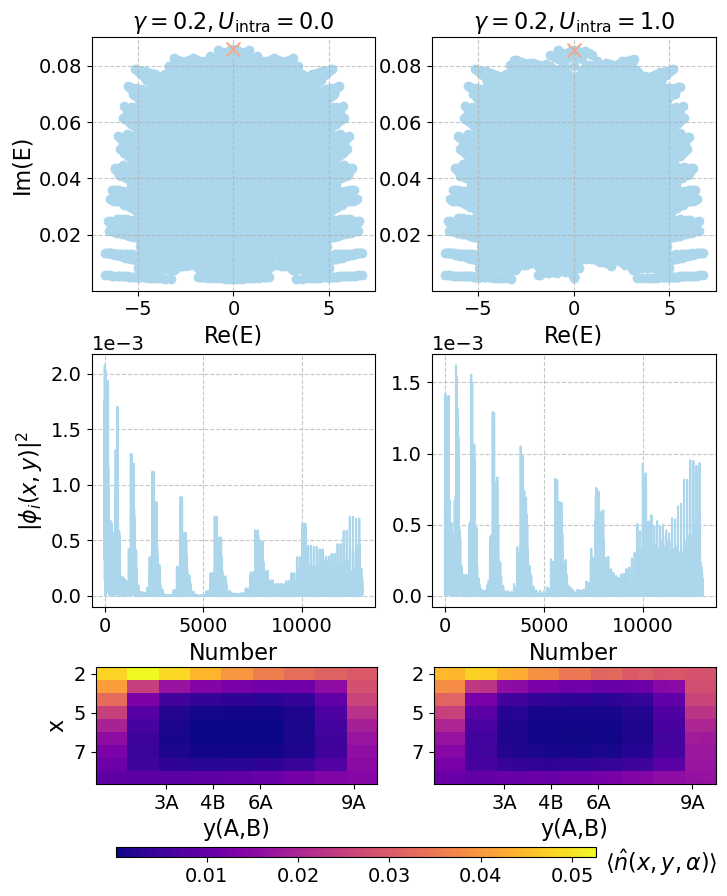

In [49]:
import numpy as np
import matplotlib.pyplot as plt
color_r = '#F5A889'
color_b = '#ACD6EC'
with np.load('TwoExcitationEig9_intra.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']
num_x, num_y = 9, 9
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
popu_indice = QWZ2.Calcu_Occup()
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k],-1])**2) 
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 

fontsize = 16
labelsize= 14
fig, ax = plt.subplots(2,2,figsize=(8, 10), sharex='row')
ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[-1].real, eigval_NH[-1].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)

ax[1, 0].plot(np.abs(eigvec_NH[:,-1])**2, color=color_b)
ax[1, 1].plot(np.abs(eigvec_NHMany[:,-1])**2, color=color_b)
ax[1, 0].set_xlabel('Number',fontsize=fontsize)
ax[1, 1].set_xlabel('Number',fontsize=fontsize)
ax[1, 0].set_ylabel(r'$\vert \phi_i(x,y)\vert^2$',fontsize=fontsize)
for row in range(2):
    for col in range(2):
        ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
for col in range(2):
    ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = ax[row, col].get_yaxis().get_offset_text()
    # 设置字体大小为12
    offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=0.2, U_{\mathrm{intra}}=0.0$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=0.2, U_{\mathrm{intra}}=1.0$', fontsize=fontsize)

from scipy import ndimage
n_map1 = popu_NH.reshape(num_x, 2*num_y).T
# 旋转90度
rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
# 计算旋转后的坐标范围
n_map2 = popu_NHMany.reshape(num_x, 2*num_y).T
# 旋转90度
rotated_data2 = ndimage.rotate(n_map2, angle=90, reshape=True)
# 计算旋转后的坐标范围
color_string = 'plasma'
pos1 = ax[1, 0].get_position()
pos2 = ax[1, 1].get_position()
plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.35,
    top=0.92,
    hspace=0.25,
    wspace=0.2
)
gap = -0.18
ax3 = fig.add_axes([pos1.x0, pos1.y0 - gap - pos1.height/3, pos1.width, pos1.height/3])
ax4 = fig.add_axes([pos2.x0, pos2.y0 - gap - pos1.height/3, pos2.width, pos1.height/3])
vmin, vmax = np.min([np.min(popu_NH), np.min(popu_NHMany)]), np.max([np.max(popu_NH), np.max(popu_NHMany)]) # 但是这样颜色会看不出来。
sm  = ax3.imshow(rotated_data1, 
          aspect='auto',
          origin='lower',
          vmin=vmin,vmax=vmax,
          cmap=color_string)
ax4.imshow(rotated_data2, 
          aspect='auto',
          origin='lower',
          vmin=vmin,vmax=vmax,
          cmap=color_string)
ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax4.set_xlabel('y(A,B)', fontsize=fontsize)
ax3.set_ylabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
# ax3.set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax4.set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax3.set_yticks(ticks=[2,5], labels=[5,2])
# ax4.set_yticks(ticks=[2,5], labels=[5,2])
ax3.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
ax4.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
ax3.set_yticks(ticks=[2,5,8], labels=[7,5,2])
ax4.set_yticks(ticks=[2,5,8], labels=[7,5,2])

cax = fig.add_axes([0.15, 0.1, 0.6, 0.01]) # [左，下，宽，高]
cbar = plt.colorbar(
    sm,
    cax=cax,
    orientation='horizontal'
)
cax.tick_params(axis='both', which='major', labelsize=labelsize)
# cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
cax.text(cax.get_xlim()[-1]+0.001, cax.get_ylim()[-1], r'$\langle \hat{n}(x,y,\alpha) \rangle$', va='top', ha='left', fontsize=fontsize)
fig.savefig("DataPicture/SI_TwoExcitationSpectrum_intra.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()

##  三合一的对，对比突出chiral skin-many body induced localized states

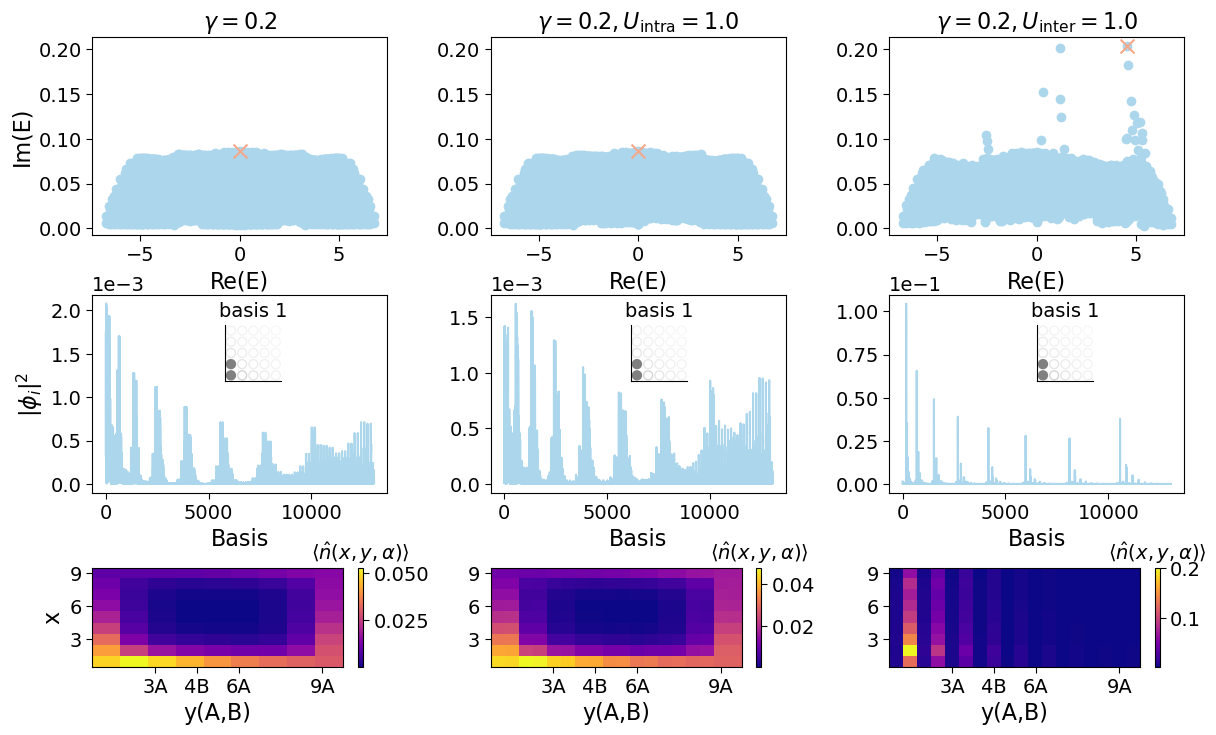

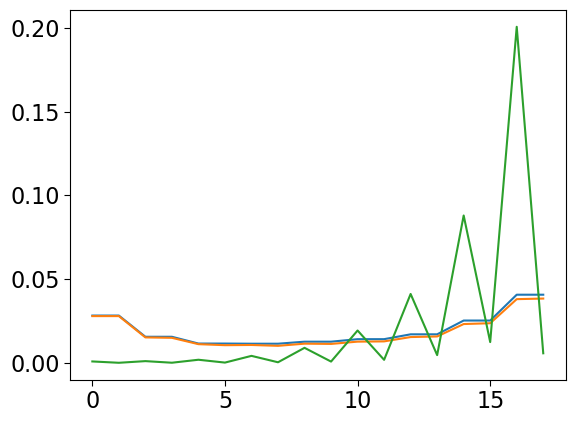

In [291]:
with np.load('TwoExcitationEig9.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany_inter = files['eigval_NHMany']
    eigvec_NHMany_inter = files['eigvec_NHMany']

import numpy as np
import matplotlib.pyplot as plt
color_r = '#F5A889'
color_b = '#ACD6EC'
with np.load('TwoExcitationEig9_intra.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']
num_x, num_y = 9, 9
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
popu_indice = QWZ2.Calcu_Occup()
popu_NHMany_inter = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany_inter[k] = np.sum(np.abs(eigvec_NHMany_inter[popu_indice[k],-1])**2) 
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k],-1])**2) 
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 

fontsize = 16
labelsize= 14
fig, ax = plt.subplots(2,3,figsize=(14, 8), sharex='row')
ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1], ax[0, 2]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[-1].real, eigval_NH[-1].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0, 2].scatter(eigval_NHMany_inter.real, eigval_NHMany_inter.imag, color=color_b)
ax[0, 2].scatter(eigval_NHMany_inter[-1].real, eigval_NHMany_inter[-1].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 2].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)

basis_num = len(eigvec_NH[:,-1])
ax[1, 0].plot(np.arange(1, basis_num+1), np.abs(eigvec_NH[:,-1])**2, color=color_b)
ax[1, 1].plot(np.arange(1, basis_num+1), np.abs(eigvec_NHMany[:,-1])**2, color=color_b)
ax[1, 2].plot(np.arange(1, basis_num+1), np.abs(eigvec_NHMany_inter[:,-1])**2, color=color_b)
ax[1, 0].set_xlabel('Basis',fontsize=fontsize)
ax[1, 1].set_xlabel('Basis',fontsize=fontsize)
ax[1, 2].set_xlabel('Basis',fontsize=fontsize)
ax[1, 0].set_ylabel(r'$\vert \phi_i\vert^2$',fontsize=fontsize)

for row in range(2):
    for col in range(3):
        # ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
for col in range(3):
    ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = ax[row, col].get_yaxis().get_offset_text()
    # 设置字体大小为12
    offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=0.2$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=0.2, U_{\mathrm{intra}}=1.0$', fontsize=fontsize)
ax[0, 2].set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=1.0$', fontsize=fontsize)


# 画双激发粒子
new_ax = fig.add_axes([0.2, 0.49, 0.07, 0.07]) 
ShowTwoExcitationPlot(new_ax,2)
new_ax.set_title('basis 1', fontsize=14)
new_ax = fig.add_axes([0.49, 0.49, 0.07, 0.07]) 
ShowTwoExcitationPlot(new_ax,2)
new_ax.set_title('basis 1', fontsize=14)
new_ax = fig.add_axes([0.78, 0.49, 0.07, 0.07]) 
ShowTwoExcitationPlot(new_ax,2)
new_ax.set_title('basis 1', fontsize=14)


from scipy import ndimage
n_map1 = popu_NH.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
# 计算旋转后的坐标范围
n_map2 = popu_NHMany.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data2 = ndimage.rotate(n_map2, angle=90, reshape=True)
n_map3 = popu_NHMany_inter.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data3 = ndimage.rotate(n_map3, angle=90, reshape=True)
# 计算旋转后的坐标范围
color_string = 'plasma'

plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.35,
    top=0.92,
    hspace=0.3,
    wspace=0.35
)
pos1 = ax[1, 0].get_position()
pos2 = ax[1, 1].get_position()
pos3 = ax[1, 2].get_position()
gap = 0.135
ax3 = fig.add_axes([pos1.x0, pos1.y0 - gap - pos1.height/3, pos1.width, pos1.height/2])
ax4 = fig.add_axes([pos2.x0, pos2.y0 - gap - pos2.height/3, pos2.width, pos2.height/2])
ax_inter = fig.add_axes([pos3.x0, pos3.y0 - gap - pos3.height/3, pos3.width, pos3.height/2])
vmin, vmax = np.min([np.min(popu_NH), np.min(popu_NHMany)]), np.max([np.max(popu_NH), np.max(popu_NHMany)]) # 但是这样颜色会看不出来。
sm3 = ax3.imshow(n_map1, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
sm4 = ax4.imshow(n_map2, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
sm_inter = ax_inter.imshow(n_map3, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
# vmin=vmin,vmax=vmax,
ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax4.set_xlabel('y(A,B)', fontsize=fontsize)
ax_inter.set_xlabel('y(A,B)', fontsize=fontsize)
ax3.set_ylabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
ax_inter.tick_params(axis='both', which='major', labelsize=labelsize)
# ax3.set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax4.set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax3.set_yticks(ticks=[2,5], labels=[5,2])
# ax4.set_yticks(ticks=[2,5], labels=[5,2])
ax3.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
ax3.set_yticks(ticks=[2,5,8], labels=[3 ,6, 9])
ax4.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
ax4.set_yticks(ticks=[2,5,8], labels=[3 ,6, 9])
ax_inter.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
ax_inter.set_yticks(ticks=[2,5,8], labels=[3 ,6, 9])


cbar1 = plt.colorbar(sm3, ax=ax3, fraction=0.1)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.set_title(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize=labelsize)
cbar2 = plt.colorbar(sm4, ax=ax4, fraction=0.1)
cbar2.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar2.ax.set_title(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize=labelsize)
cbar3 = plt.colorbar(sm_inter, ax=ax_inter, fraction=0.1)
cbar3.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar3.ax.set_title(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize=labelsize)
# cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
# offset_text = cbar1.ax.get_yaxis().get_offset_text()
# # 设置字体大小为12
# offset_text.set_fontsize(labelsize)


# cax = fig.add_axes([0.15, 0.1, 0.6, 0.01]) # [左，下，宽，高]
# cbar = plt.colorbar(
#     sm,
#     cax=cax,
#     orientation='horizontal'
# )
# cax.tick_params(axis='both', which='major', labelsize=labelsize)
# # cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
# cax.text(cax.get_xlim()[-1]+0.001, cax.get_ylim()[-1], r'$\langle \hat{n}(x,y,\alpha) \rangle$', va='top', ha='left', fontsize=fontsize)
fig.savefig("DataPicture/SI_TwoExcitationSpectrum.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()

plt.plot(rotated_data1[:,1])
plt.plot(rotated_data2[:,1])
plt.plot(rotated_data3[:,1])
plt.show()

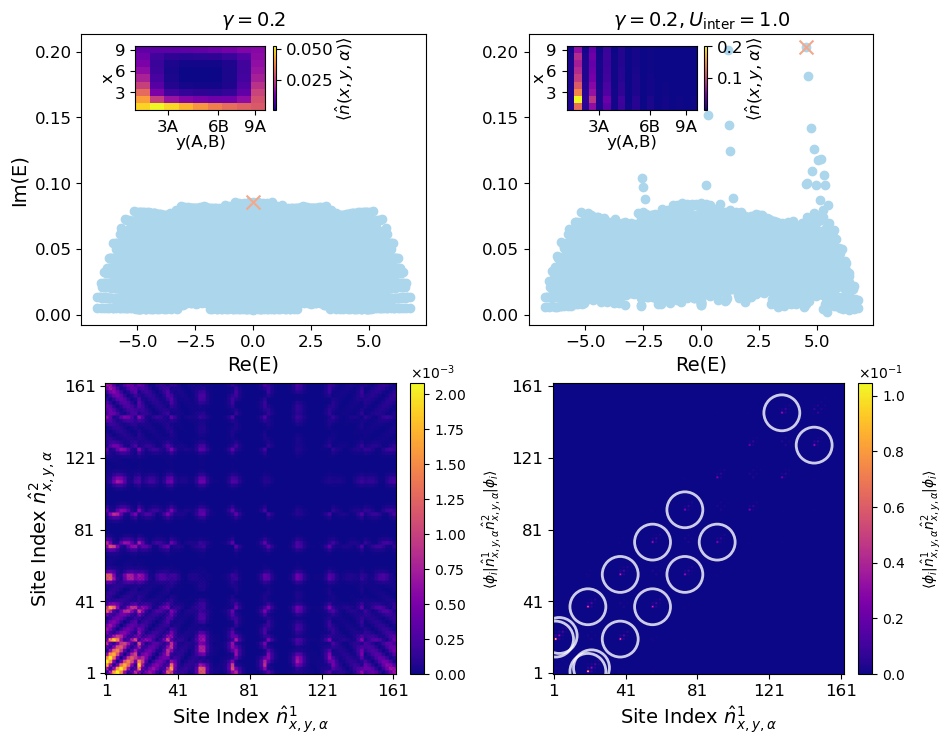

In [ ]:
with np.load('TwoExcitationEig9.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany_inter = files['eigval_NHMany']
    eigvec_NHMany_inter = files['eigvec_NHMany']

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
color_r = '#F5A889'
color_b = '#ACD6EC'
# with np.load('TwoExcitationEig9_intra.npz') as files:
#     eigval_NH = files['eigval_NH']
#     eigvec_NH = files['eigvec_NH']
#     eigval_NHMany = files['eigval_NHMany']
#     eigvec_NHMany = files['eigvec_NHMany']
num_x, num_y = 9, 9
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
popu_indice = QWZ2.Calcu_Occup()
popu_NHMany_inter = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany_inter[k] = np.sum(np.abs(eigvec_NHMany_inter[popu_indice[k],-1])**2) 
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k],-1])**2) 
# popu_NHMany = np.zeros(QWZ2.total_mode)
# for k in range(2*num_x*num_y): # 应该要加2。
#     popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 

fontsize = 14
labelsize= 12
fig, ax = plt.subplots(2, 2, figsize=(9, 8), sharex='row')
ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[-1].real, eigval_NH[-1].imag, color=color_r, s=100, marker='x')
# ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
# ax[0, 1].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany_inter.real, eigval_NHMany_inter.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany_inter[-1].real, eigval_NHMany_inter[-1].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)

basis_num = len(eigvec_NH[:,-1])
# ax[1, 0].plot(np.arange(1, basis_num+1), np.abs(eigvec_NH[:,-1])**2, color=color_b)
# ax[1, 1].plot(np.arange(1, basis_num+1), np.abs(eigvec_NHMany[:,-1])**2, color=color_b)
# ax[1, 2].plot(np.arange(1, basis_num+1), np.abs(eigvec_NHMany_inter[:,-1])**2, color=color_b)
# ax[1, 0].set_xlabel('Basis',fontsize=fontsize)
# ax[1, 1].set_xlabel('Basis',fontsize=fontsize)
# ax[1, 2].set_xlabel('Basis',fontsize=fontsize)
# ax[1, 0].set_ylabel(r'$\vert \phi_i\vert^2$',fontsize=fontsize)


# # 画双激发粒子
# new_ax = fig.add_axes([0.2, 0.49, 0.07, 0.07]) 
# ShowTwoExcitationPlot(new_ax,2)
# new_ax.set_title('basis 1', fontsize=14)
# new_ax = fig.add_axes([0.49, 0.49, 0.07, 0.07]) 
# ShowTwoExcitationPlot(new_ax,2)
# new_ax.set_title('basis 1', fontsize=14)
# new_ax = fig.add_axes([0.78, 0.49, 0.07, 0.07]) 
# ShowTwoExcitationPlot(new_ax,2)
# new_ax.set_title('basis 1', fontsize=14)


from scipy import ndimage
n_map1 = popu_NH.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
# 计算旋转后的坐标范围
n_map2 = popu_NHMany.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data2 = ndimage.rotate(n_map2, angle=90, reshape=True)
n_map3 = popu_NHMany_inter.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data3 = ndimage.rotate(n_map3, angle=90, reshape=True)
# 计算旋转后的坐标范围
color_string = 'plasma'

plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.35,
    top=0.92,
    hspace=0.3,
    wspace=0.35
)
pos1 = ax[0, 0].get_position()
# pos2 = ax[0, 1].get_position()
pos3 = ax[0, 1].get_position()
gap = -0.05
# ax3 = fig.add_axes([pos1.x0, pos1.y0 - gap + pos1.height, pos1.width/2, pos1.height/3])
# # ax4 = fig.add_axes([pos2.x0, pos2.y0 - gap - pos2.height/3, pos2.width, pos2.height/2])
# ax_inter = fig.add_axes([pos3.x0, pos3.y0 - gap + pos3.height, pos3.width/2, pos3.height/3])

# ax3 = inset_axes(ax[0, 0], width="40%", height="30%", bbox_to_anchor=(0.1, 0.3, 0.8, 0.8))
# ax_inter = inset_axes(ax[0, 1], width="40%", height="30%", loc='upper left')
ax3 = fig.add_axes([0.16, 0.805, 0.17, 0.08]) 
ax_inter = fig.add_axes([0.639, 0.805, 0.17, 0.08]) 


vmin, vmax = np.min([np.min(popu_NH), np.min(popu_NHMany)]), np.max([np.max(popu_NH), np.max(popu_NHMany)]) # 但是这样颜色会看不出来。
sm3 = ax3.imshow(n_map1, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
# sm4 = ax4.imshow(n_map2, 
#           aspect='auto',
#           origin='lower',
#           cmap=color_string)
sm_inter = ax_inter.imshow(n_map3, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
# vmin=vmin,vmax=vmax,
labelpad = 0
ax3.set_xlabel('y(A,B)', fontsize=labelsize, labelpad=labelpad)
# ax4.set_xlabel('y(A,B)', fontsize=fontsize)
ax_inter.set_xlabel('y(A,B)', fontsize=labelsize, labelpad=labelpad)
ax3.set_ylabel('x', fontsize=labelsize, labelpad=labelpad)
ax_inter.set_ylabel('x', fontsize=labelsize, labelpad=labelpad)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
# ax4.tick_params(axis='both', which='major', labelsize=labelsize)
ax_inter.tick_params(axis='both', which='major', labelsize=labelsize)
# ax3.set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax4.set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax3.set_yticks(ticks=[2,5], labels=[5,2])
# ax4.set_yticks(ticks=[2,5], labels=[5,2])
ax3.set_xticks(ticks=[4,11,16], labels=['3A','6B','9A'])
ax3.set_yticks(ticks=[2,5,8], labels=[3 ,6, 9])
# ax4.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
# ax4.set_yticks(ticks=[2,5,8], labels=[3 ,6, 9])
ax_inter.set_xticks(ticks=[4,11,16], labels=['3A','6B','9A'])
ax_inter.set_yticks(ticks=[2,5,8], labels=[3 ,6, 9])


cbar1 = plt.colorbar(sm3, ax=ax3, fraction=0.1)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.set_ylabel(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize=labelsize, labelpad=labelpad)
# cbar2 = plt.colorbar(sm4, ax=ax4, fraction=0.1)
# cbar2.ax.tick_params(axis='both', which='major', labelsize=labelsize)
# cbar2.ax.set_title(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize=labelsize)
cbar3 = plt.colorbar(sm_inter, ax=ax_inter, fraction=0.1)
cbar3.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar3.ax.set_ylabel(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize=labelsize, labelpad=labelpad)
# cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
# offset_text = cbar1.ax.get_yaxis().get_offset_text()
# # 设置字体大小为12
# offset_text.set_fontsize(labelsize)

# plot in the correlation function
from matplotlib.patches import Circle
from matplotlib.ticker import ScalarFormatter
sci_formatter = ScalarFormatter(useMathText=True)
sci_formatter.set_powerlimits((0, 0))

d_indice = np.tril_indices(2*num_x*num_y, k=-1)
d_NH = np.zeros((2*num_x*num_y, 2*num_x*num_y))
d_NH_inter = np.zeros((2*num_x*num_y, 2*num_x*num_y))
d_NH[d_indice] = np.abs(eigvec_NH[:,-1])**2
d_NH = d_NH + d_NH.T
d_NH_inter[d_indice] = np.abs(eigvec_NHMany_inter[:,-1])**2
d_NH_inter = d_NH_inter + d_NH_inter.T

data_matrices = [d_NH, d_NH_inter]
ys, xs = np.where(data_matrices[1] > 0.03)
radius = 10

for temp_ax, matrix in zip(ax[1], data_matrices):
    # 绘制矩阵（强制正方形）
    img = temp_ax.imshow(matrix, cmap=color_string, 
                   origin='lower', 
                   aspect='equal',  # 关键修改：保证正方形
                    )
    
    # 设置标题和标签（x和y相同）
    # temp_ax.set_title(title, pad=15)
    temp_ax.set_xlabel(r'Site Index $\hat{n}^1_{x,y,\alpha}$', fontsize=fontsize)
    # temp_ax.set_ylabel(r'Site Index $\hat{n}^2_{x,y,\alpha}$')
    
    # 设置刻度
    n = matrix.shape[0]
    step = max(1, n//4)  # 减少刻度密度
    temp_ax.set_xticks(np.arange(0, n, step), np.arange(1, n, step))
    temp_ax.set_yticks(np.arange(0, n, step), np.arange(1, n, step))
    
    # 添加colorbar（使用科学计数法）
    cbar = fig.colorbar(img, ax=temp_ax, fraction=0.046, pad=0.04)
    cbar.formatter = sci_formatter
    cbar.update_normal(img)
    cbar.ax.yaxis.set_offset_position('left')  # 科学计数法偏移位置
    cbar.set_label(r'$\langle \phi_i \vert \hat{n}^1_{x,y,\alpha} \hat{n}^2_{x,y,\alpha} \vert \phi_i \rangle$', rotation=90, labelpad=10)
ax[1, 0].set_ylabel(r'Site Index $\hat{n}^2_{x,y,\alpha}$', fontsize=fontsize)
# 添加多个圆圈
for x, y in zip(xs, ys):
    circle = Circle((x, y), radius=radius, edgecolor='white', facecolor='none', linewidth=2, alpha=0.8)
    ax[1, 1].add_patch(circle)

for row in range(2):
    for col in range(2):
        # ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
# for col in range(2):
#     ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
#     offset_text = ax[row, col].get_yaxis().get_offset_text()
#     # 设置字体大小为12
#     offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=0.2$', fontsize=fontsize)
# ax[0, 1].set_title(r'$\gamma=0.2, U_{\mathrm{intra}}=1.0$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=1.0$', fontsize=fontsize)


# cax = fig.add_axes([0.15, 0.1, 0.6, 0.01]) # [左，下，宽，高]
# cbar = plt.colorbar(
#     sm,
#     cax=cax,
#     orientation='horizontal'
# )
# cax.tick_params(axis='both', which='major', labelsize=labelsize)
# # cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
# cax.text(cax.get_xlim()[-1]+0.001, cax.get_ylim()[-1], r'$\langle \hat{n}(x,y,\alpha) \rangle$', va='top', ha='left', fontsize=fontsize)
fig.subplots_adjust(left=0.1, right=0.98, 
                   bottom=0.1, top=0.9,
                   wspace=0.3, hspace=0.2)
fig.savefig("DataPicture/Pic_TwoExcitation.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()


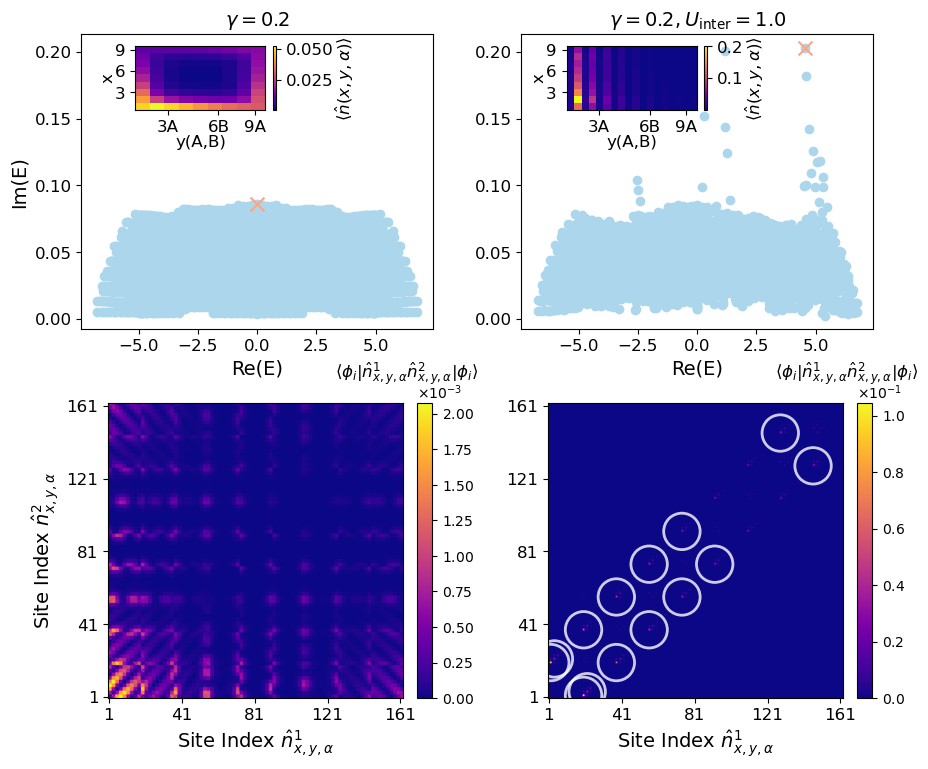

In [26]:
with np.load('TwoExcitationEig9.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany_inter = files['eigval_NHMany']
    eigvec_NHMany_inter = files['eigvec_NHMany']

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
color_r = '#F5A889'
color_b = '#ACD6EC'
# with np.load('TwoExcitationEig9_intra.npz') as files:
#     eigval_NH = files['eigval_NH']
#     eigvec_NH = files['eigvec_NH']
#     eigval_NHMany = files['eigval_NHMany']
#     eigvec_NHMany = files['eigvec_NHMany']
num_x, num_y = 9, 9
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
popu_indice = QWZ2.Calcu_Occup()
popu_NHMany_inter = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany_inter[k] = np.sum(np.abs(eigvec_NHMany_inter[popu_indice[k],-1])**2) 
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k],-1])**2) 
# popu_NHMany = np.zeros(QWZ2.total_mode)
# for k in range(2*num_x*num_y): # 应该要加2。
#     popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 

fontsize = 14
labelsize= 12
fig, ax = plt.subplots(2, 2, figsize=(9, 8), sharex='row')
ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[-1].real, eigval_NH[-1].imag, color=color_r, s=100, marker='x')
# ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
# ax[0, 1].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany_inter.real, eigval_NHMany_inter.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany_inter[-1].real, eigval_NHMany_inter[-1].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)

basis_num = len(eigvec_NH[:,-1])
# ax[1, 0].plot(np.arange(1, basis_num+1), np.abs(eigvec_NH[:,-1])**2, color=color_b)
# ax[1, 1].plot(np.arange(1, basis_num+1), np.abs(eigvec_NHMany[:,-1])**2, color=color_b)
# ax[1, 2].plot(np.arange(1, basis_num+1), np.abs(eigvec_NHMany_inter[:,-1])**2, color=color_b)
# ax[1, 0].set_xlabel('Basis',fontsize=fontsize)
# ax[1, 1].set_xlabel('Basis',fontsize=fontsize)
# ax[1, 2].set_xlabel('Basis',fontsize=fontsize)
# ax[1, 0].set_ylabel(r'$\vert \phi_i\vert^2$',fontsize=fontsize)


# # 画双激发粒子
# new_ax = fig.add_axes([0.2, 0.49, 0.07, 0.07]) 
# ShowTwoExcitationPlot(new_ax,2)
# new_ax.set_title('basis 1', fontsize=14)
# new_ax = fig.add_axes([0.49, 0.49, 0.07, 0.07]) 
# ShowTwoExcitationPlot(new_ax,2)
# new_ax.set_title('basis 1', fontsize=14)
# new_ax = fig.add_axes([0.78, 0.49, 0.07, 0.07]) 
# ShowTwoExcitationPlot(new_ax,2)
# new_ax.set_title('basis 1', fontsize=14)


from scipy import ndimage
n_map1 = popu_NH.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
# 计算旋转后的坐标范围
n_map2 = popu_NHMany.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data2 = ndimage.rotate(n_map2, angle=90, reshape=True)
n_map3 = popu_NHMany_inter.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data3 = ndimage.rotate(n_map3, angle=90, reshape=True)
# 计算旋转后的坐标范围
color_string = 'plasma'

plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.35,
    top=0.92,
    hspace=0.3,
    wspace=0.35
)
pos1 = ax[0, 0].get_position()
# pos2 = ax[0, 1].get_position()
pos3 = ax[0, 1].get_position()
gap = -0.05
# ax3 = fig.add_axes([pos1.x0, pos1.y0 - gap + pos1.height, pos1.width/2, pos1.height/3])
# # ax4 = fig.add_axes([pos2.x0, pos2.y0 - gap - pos2.height/3, pos2.width, pos2.height/2])
# ax_inter = fig.add_axes([pos3.x0, pos3.y0 - gap + pos3.height, pos3.width/2, pos3.height/3])

# ax3 = inset_axes(ax[0, 0], width="40%", height="30%", bbox_to_anchor=(0.1, 0.3, 0.8, 0.8))
# ax_inter = inset_axes(ax[0, 1], width="40%", height="30%", loc='upper left')
ax3 = fig.add_axes([0.16, 0.805, 0.17, 0.08]) 
ax_inter = fig.add_axes([0.639, 0.805, 0.17, 0.08]) 


vmin, vmax = np.min([np.min(popu_NH), np.min(popu_NHMany)]), np.max([np.max(popu_NH), np.max(popu_NHMany)]) # 但是这样颜色会看不出来。
sm3 = ax3.imshow(n_map1, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
# sm4 = ax4.imshow(n_map2, 
#           aspect='auto',
#           origin='lower',
#           cmap=color_string)
sm_inter = ax_inter.imshow(n_map3, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
# vmin=vmin,vmax=vmax,
labelpad = 0
ax3.set_xlabel('y(A,B)', fontsize=labelsize, labelpad=labelpad)
# ax4.set_xlabel('y(A,B)', fontsize=fontsize)
ax_inter.set_xlabel('y(A,B)', fontsize=labelsize, labelpad=labelpad)
ax3.set_ylabel('x', fontsize=labelsize, labelpad=labelpad)
ax_inter.set_ylabel('x', fontsize=labelsize, labelpad=labelpad)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
# ax4.tick_params(axis='both', which='major', labelsize=labelsize)
ax_inter.tick_params(axis='both', which='major', labelsize=labelsize)
# ax3.set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax4.set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax3.set_yticks(ticks=[2,5], labels=[5,2])
# ax4.set_yticks(ticks=[2,5], labels=[5,2])
ax3.set_xticks(ticks=[4,11,16], labels=['3A','6B','9A'])
ax3.set_yticks(ticks=[2,5,8], labels=[3 ,6, 9])
# ax4.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
# ax4.set_yticks(ticks=[2,5,8], labels=[3 ,6, 9])
ax_inter.set_xticks(ticks=[4,11,16], labels=['3A','6B','9A'])
ax_inter.set_yticks(ticks=[2,5,8], labels=[3 ,6, 9])


cbar1 = plt.colorbar(sm3, ax=ax3, fraction=0.1)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.set_ylabel(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize=labelsize, labelpad=labelpad)
# cbar2 = plt.colorbar(sm4, ax=ax4, fraction=0.1)
# cbar2.ax.tick_params(axis='both', which='major', labelsize=labelsize)
# cbar2.ax.set_title(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize=labelsize)
cbar3 = plt.colorbar(sm_inter, ax=ax_inter, fraction=0.1)
cbar3.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar3.ax.set_ylabel(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize=labelsize, labelpad=labelpad)
# cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
# offset_text = cbar1.ax.get_yaxis().get_offset_text()
# # 设置字体大小为12
# offset_text.set_fontsize(labelsize)

# plot in the correlation function
from matplotlib.patches import Circle
from matplotlib.ticker import ScalarFormatter
sci_formatter = ScalarFormatter(useMathText=True)
sci_formatter.set_powerlimits((0, 0))

d_indice = np.tril_indices(2*num_x*num_y, k=-1)
d_NH = np.zeros((2*num_x*num_y, 2*num_x*num_y))
d_NH_inter = np.zeros((2*num_x*num_y, 2*num_x*num_y))
d_NH[d_indice] = np.abs(eigvec_NH[:,-1])**2
d_NH = d_NH + d_NH.T
d_NH_inter[d_indice] = np.abs(eigvec_NHMany_inter[:,-1])**2
d_NH_inter = d_NH_inter + d_NH_inter.T

data_matrices = [d_NH, d_NH_inter]
ys, xs = np.where(data_matrices[1] > 0.03)
radius = 10

for temp_ax, matrix in zip(ax[1], data_matrices):
    # 绘制矩阵（强制正方形）
    img = temp_ax.imshow(matrix, cmap=color_string, 
                   origin='lower', 
                   aspect='equal',  # 关键修改：保证正方形
                    )
    
    # 设置标题和标签（x和y相同）
    # temp_ax.set_title(title, pad=15)
    temp_ax.set_xlabel(r'Site Index $\hat{n}^1_{x,y,\alpha}$', fontsize=fontsize)
    # temp_ax.set_ylabel(r'Site Index $\hat{n}^2_{x,y,\alpha}$')
    
    # 设置刻度
    n = matrix.shape[0]
    step = max(1, n//4)  # 减少刻度密度
    temp_ax.set_xticks(np.arange(0, n, step), np.arange(1, n, step))
    temp_ax.set_yticks(np.arange(0, n, step), np.arange(1, n, step))
    
    # 添加colorbar（使用科学计数法）
    cbar = fig.colorbar(img, ax=temp_ax, fraction=0.046, pad=0.04)
    cbar.formatter = sci_formatter
    cbar.update_normal(img)
    cbar.ax.yaxis.set_offset_position('left')  # 科学计数法偏移位置
    # cbar.set_label(r'$\langle \phi_i \vert \hat{n}^1_{x,y,\alpha} \hat{n}^2_{x,y,\alpha} \vert \phi_i \rangle$', rotation=0, labelpad=-40)
    cbar.ax.set_title(r'$\langle \phi_i \vert \hat{n}^1_{x,y,\alpha} \hat{n}^2_{x,y,\alpha} \vert \phi_i \rangle$', pad = 18)
    current_pos = cbar.ax.title.get_position()
    cbar.ax.title.set_position((current_pos[0] - 1.2, current_pos[1]))  # 向左移动 0.03
ax[1, 0].set_ylabel(r'Site Index $\hat{n}^2_{x,y,\alpha}$', fontsize=fontsize)
# 添加多个圆圈
for x, y in zip(xs, ys):
    circle = Circle((x, y), radius=radius, edgecolor='white', facecolor='none', linewidth=2, alpha=0.8)
    ax[1, 1].add_patch(circle)

for row in range(2):
    for col in range(2):
        # ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
# for col in range(2):
#     ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
#     offset_text = ax[row, col].get_yaxis().get_offset_text()
#     # 设置字体大小为12
#     offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=0.2$', fontsize=fontsize)
# ax[0, 1].set_title(r'$\gamma=0.2, U_{\mathrm{intra}}=1.0$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=0.2, U_{\mathrm{inter}}=1.0$', fontsize=fontsize)


# cax = fig.add_axes([0.15, 0.1, 0.6, 0.01]) # [左，下，宽，高]
# cbar = plt.colorbar(
#     sm,
#     cax=cax,
#     orientation='horizontal'
# )
# cax.tick_params(axis='both', which='major', labelsize=labelsize)
# # cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
# cax.text(cax.get_xlim()[-1]+0.001, cax.get_ylim()[-1], r'$\langle \hat{n}(x,y,\alpha) \rangle$', va='top', ha='left', fontsize=fontsize)
fig.subplots_adjust(left=0.1, right=0.98, 
                   bottom=0.07, top=0.9,
                   wspace=0.25, hspace=0.25)
fig.savefig("DataPicture/Pic_TwoExcitation.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()

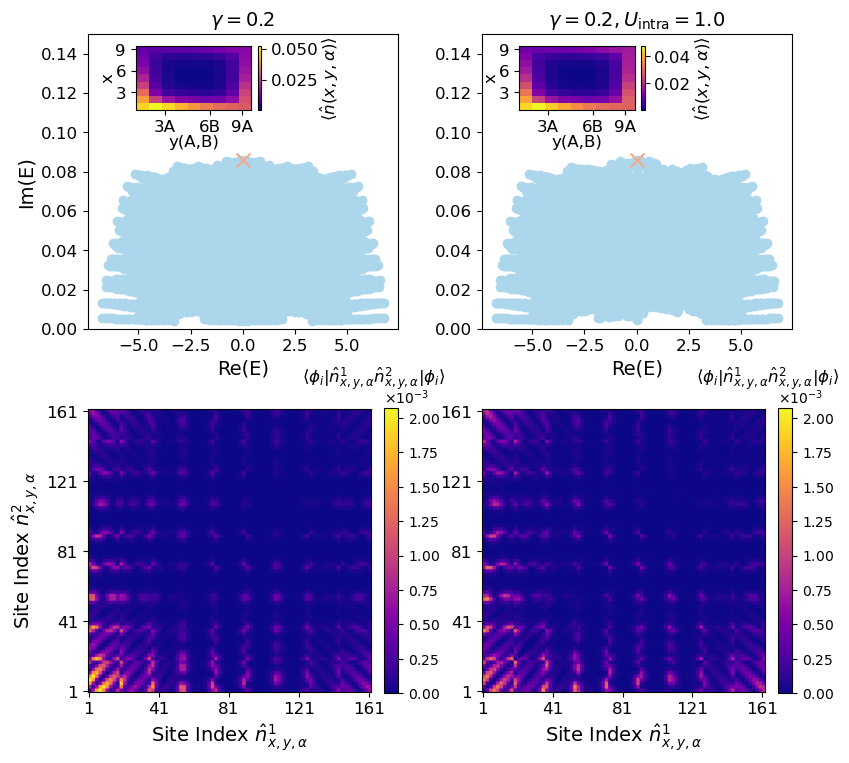

In [38]:
# intra interaction
# with np.load('TwoExcitationEig9.npz') as files:
#     eigval_NH = files['eigval_NH']
#     eigvec_NH = files['eigvec_NH']
#     eigval_NHMany_inter = files['eigval_NHMany']
#     eigvec_NHMany_inter = files['eigvec_NHMany']
with np.load('TwoExcitationEig9_intra.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany_intra = files['eigval_NHMany']
    eigvec_NHMany_intra = files['eigvec_NHMany']

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
color_r = '#F5A889'
color_b = '#ACD6EC'
# with np.load('TwoExcitationEig9_intra.npz') as files:
#     eigval_NH = files['eigval_NH']
#     eigvec_NH = files['eigvec_NH']
#     eigval_NHMany = files['eigval_NHMany']
#     eigvec_NHMany = files['eigvec_NHMany']
num_x, num_y = 9, 9
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
popu_indice = QWZ2.Calcu_Occup()
popu_NHMany_intra = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany_intra[k] = np.sum(np.abs(eigvec_NHMany_intra[popu_indice[k],-1])**2) 
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k],-1])**2) 
# popu_NHMany = np.zeros(QWZ2.total_mode)
# for k in range(2*num_x*num_y): # 应该要加2。
#     popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k],-1])**2) 

fontsize = 14
labelsize= 12
fig, ax = plt.subplots(2, 2, figsize=(8, 8), sharex='row')
ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[-1].real, eigval_NH[-1].imag, color=color_r, s=100, marker='x')
# ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
# ax[0, 1].scatter(eigval_NHMany[-1].real, eigval_NHMany[-1].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany_intra.real, eigval_NHMany_intra.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany_intra[-1].real, eigval_NHMany_intra[-1].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)
ax[0, 0].set_ylim(ymin=0, ymax=0.15)

basis_num = len(eigvec_NH[:,-1])
# ax[1, 0].plot(np.arange(1, basis_num+1), np.abs(eigvec_NH[:,-1])**2, color=color_b)
# ax[1, 1].plot(np.arange(1, basis_num+1), np.abs(eigvec_NHMany[:,-1])**2, color=color_b)
# ax[1, 2].plot(np.arange(1, basis_num+1), np.abs(eigvec_NHMany_intra[:,-1])**2, color=color_b)
# ax[1, 0].set_xlabel('Basis',fontsize=fontsize)
# ax[1, 1].set_xlabel('Basis',fontsize=fontsize)
# ax[1, 2].set_xlabel('Basis',fontsize=fontsize)
# ax[1, 0].set_ylabel(r'$\vert \phi_i\vert^2$',fontsize=fontsize)


# # 画双激发粒子
# new_ax = fig.add_axes([0.2, 0.49, 0.07, 0.07]) 
# ShowTwoExcitationPlot(new_ax,2)
# new_ax.set_title('basis 1', fontsize=14)
# new_ax = fig.add_axes([0.49, 0.49, 0.07, 0.07]) 
# ShowTwoExcitationPlot(new_ax,2)
# new_ax.set_title('basis 1', fontsize=14)
# new_ax = fig.add_axes([0.78, 0.49, 0.07, 0.07]) 
# ShowTwoExcitationPlot(new_ax,2)
# new_ax.set_title('basis 1', fontsize=14)


from scipy import ndimage
n_map1 = popu_NH.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
# 计算旋转后的坐标范围
n_map2 = popu_NHMany.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data2 = ndimage.rotate(n_map2, angle=90, reshape=True)
n_map3 = popu_NHMany_intra.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data3 = ndimage.rotate(n_map3, angle=90, reshape=True)
# 计算旋转后的坐标范围
color_string = 'plasma'

plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.35,
    top=0.92,
    hspace=0.3,
    wspace=0.35
)
pos1 = ax[0, 0].get_position()
# pos2 = ax[0, 1].get_position()
pos3 = ax[0, 1].get_position()
gap = -0.05
# ax3 = fig.add_axes([pos1.x0, pos1.y0 - gap + pos1.height, pos1.width/2, pos1.height/3])
# # ax4 = fig.add_axes([pos2.x0, pos2.y0 - gap - pos2.height/3, pos2.width, pos2.height/2])
# ax_inter = fig.add_axes([pos3.x0, pos3.y0 - gap + pos3.height, pos3.width/2, pos3.height/3])

# ax3 = inset_axes(ax[0, 0], width="40%", height="30%", bbox_to_anchor=(0.1, 0.3, 0.8, 0.8))
# ax_inter = inset_axes(ax[0, 1], width="40%", height="30%", loc='upper left')
ax3 = fig.add_axes([0.16, 0.805, 0.17, 0.08]) 
ax_inter = fig.add_axes([0.639, 0.805, 0.17, 0.08]) 

vmin, vmax = np.min([np.min(popu_NH), np.min(popu_NHMany_intra)]), np.max([np.max(popu_NH), np.max(popu_NHMany_intra)]) # 但是这样颜色会看不出来。

sm3 = ax3.imshow(n_map1, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
# sm4 = ax4.imshow(n_map2, 
#           aspect='auto',
#           origin='lower',
#           cmap=color_string)
sm_inter = ax_inter.imshow(n_map3, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
# vmin=vmin,vmax=vmax,
labelpad = 0
ax3.set_xlabel('y(A,B)', fontsize=labelsize, labelpad=labelpad)
# ax4.set_xlabel('y(A,B)', fontsize=fontsize)
ax_inter.set_xlabel('y(A,B)', fontsize=labelsize, labelpad=labelpad)
ax3.set_ylabel('x', fontsize=labelsize, labelpad=labelpad)
ax_inter.set_ylabel('x', fontsize=labelsize, labelpad=labelpad)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
# ax4.tick_params(axis='both', which='major', labelsize=labelsize)
ax_inter.tick_params(axis='both', which='major', labelsize=labelsize)
# ax3.set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax4.set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax3.set_yticks(ticks=[2,5], labels=[5,2])
# ax4.set_yticks(ticks=[2,5], labels=[5,2])
ax3.set_xticks(ticks=[4,11,16], labels=['3A','6B','9A'])
ax3.set_yticks(ticks=[2,5,8], labels=[3 ,6, 9])
# ax4.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
# ax4.set_yticks(ticks=[2,5,8], labels=[3 ,6, 9])
ax_inter.set_xticks(ticks=[4,11,16], labels=['3A','6B','9A'])
ax_inter.set_yticks(ticks=[2,5,8], labels=[3 ,6, 9])


cbar1 = plt.colorbar(sm3, ax=ax3, fraction=0.1)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.set_ylabel(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize=labelsize, labelpad=labelpad)
# cbar2 = plt.colorbar(sm4, ax=ax4, fraction=0.1)
# cbar2.ax.tick_params(axis='both', which='major', labelsize=labelsize)
# cbar2.ax.set_title(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize=labelsize)
cbar3 = plt.colorbar(sm_inter, ax=ax_inter, fraction=0.1)
cbar3.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar3.ax.set_ylabel(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize=labelsize, labelpad=labelpad)
# cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
# offset_text = cbar1.ax.get_yaxis().get_offset_text()
# # 设置字体大小为12
# offset_text.set_fontsize(labelsize)

# plot in the correlation function
from matplotlib.patches import Circle
from matplotlib.ticker import ScalarFormatter
sci_formatter = ScalarFormatter(useMathText=True)
sci_formatter.set_powerlimits((0, 0))

d_indice = np.tril_indices(2*num_x*num_y, k=-1)
d_NH = np.zeros((2*num_x*num_y, 2*num_x*num_y))
d_NH_inter = np.zeros((2*num_x*num_y, 2*num_x*num_y))
d_NH[d_indice] = np.abs(eigvec_NH[:,-1])**2
d_NH = d_NH + d_NH.T
d_NH_inter[d_indice] = np.abs(eigvec_NHMany_intra[:,-1])**2
d_NH_inter = d_NH_inter + d_NH_inter.T

data_matrices = [d_NH, d_NH_inter]
vmin, vmax = np.min([np.min(d_NH), np.min(d_NH_inter)]), np.max([np.max(d_NH), np.max(d_NH_inter)])
ys, xs = np.where(data_matrices[1] > 0.03)
radius = 10

for temp_ax, matrix in zip(ax[1], data_matrices):
    # 绘制矩阵（强制正方形）
    img = temp_ax.imshow(matrix, cmap=color_string, 
                        origin='lower', aspect='equal',  # 关键修改：保证正方形
                        vmin=vmin, vmax=vmax
                        )
    
    # 设置标题和标签（x和y相同）
    # temp_ax.set_title(title, pad=15)
    temp_ax.set_xlabel(r'Site Index $\hat{n}^1_{x,y,\alpha}$', fontsize=fontsize)
    # temp_ax.set_ylabel(r'Site Index $\hat{n}^2_{x,y,\alpha}$')
    
    # 设置刻度
    n = matrix.shape[0]
    step = max(1, n//4)  # 减少刻度密度
    temp_ax.set_xticks(np.arange(0, n, step), np.arange(1, n, step))
    temp_ax.set_yticks(np.arange(0, n, step), np.arange(1, n, step))
    
    # 添加colorbar（使用科学计数法）
    cbar = fig.colorbar(img, ax=temp_ax, fraction=0.046, pad=0.04)
    cbar.formatter = sci_formatter
    cbar.update_normal(img)
    cbar.ax.yaxis.set_offset_position('left')  # 科学计数法偏移位置
    # cbar.set_label(r'$\langle \phi_i \vert \hat{n}^1_{x,y,\alpha} \hat{n}^2_{x,y,\alpha} \vert \phi_i \rangle$', rotation=0, labelpad=-40)
    cbar.ax.set_title(r'$\langle \phi_i \vert \hat{n}^1_{x,y,\alpha} \hat{n}^2_{x,y,\alpha} \vert \phi_i \rangle$', pad = 18)
    current_pos = cbar.ax.title.get_position()
    cbar.ax.title.set_position((current_pos[0] - 1.2, current_pos[1]))  # 向左移动 0.03
ax[1, 0].set_ylabel(r'Site Index $\hat{n}^2_{x,y,\alpha}$', fontsize=fontsize)
# 添加多个圆圈
for x, y in zip(xs, ys):
    circle = Circle((x, y), radius=radius, edgecolor='white', facecolor='none', linewidth=2, alpha=0.8)
    ax[1, 1].add_patch(circle)

for row in range(2):
    for col in range(2):
        # ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
# for col in range(2):
#     ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
#     offset_text = ax[row, col].get_yaxis().get_offset_text()
#     # 设置字体大小为12
#     offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=0.2$', fontsize=fontsize)
# ax[0, 1].set_title(r'$\gamma=0.2, U_{\mathrm{intra}}=1.0$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=0.2, U_{\mathrm{intra}}=1.0$', fontsize=fontsize)


# cax = fig.add_axes([0.15, 0.1, 0.6, 0.01]) # [左，下，宽，高]
# cbar = plt.colorbar(
#     sm,
#     cax=cax,
#     orientation='horizontal'
# )
# cax.tick_params(axis='both', which='major', labelsize=labelsize)
# # cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
# cax.text(cax.get_xlim()[-1]+0.001, cax.get_ylim()[-1], r'$\langle \hat{n}(x,y,\alpha) \rangle$', va='top', ha='left', fontsize=fontsize)
fig.subplots_adjust(left=0.1, right=0.98, 
                   bottom=0.07, top=0.9,
                   wspace=0.27, hspace=0.25)
fig.savefig("DataPicture/Pic_TwoExcitation_intra.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()

## Correlation Function

C:\Users\18349\AppData\Local\Temp\ipykernel_31520\1995454181.py:96: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



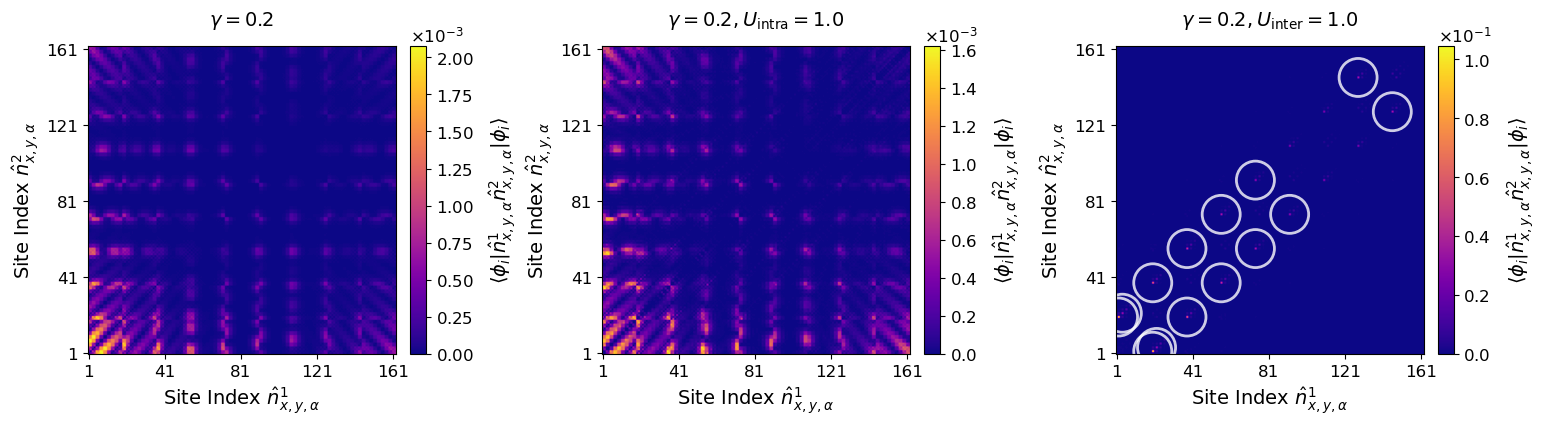

In [411]:
with np.load('TwoExcitationEig9.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany_inter = files['eigval_NHMany']
    eigvec_NHMany_inter = files['eigvec_NHMany']

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
color_r = '#F5A889'
color_b = '#ACD6EC'
color_string = 'plasma'
with np.load('TwoExcitationEig9_intra.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']
num_x, num_y = 9, 9

d_indice = np.tril_indices(2*num_x*num_y, k=-1)
d_NH = np.zeros((2*num_x*num_y, 2*num_x*num_y))
d_NH_intra = np.zeros((2*num_x*num_y, 2*num_x*num_y))
d_NH_inter = np.zeros((2*num_x*num_y, 2*num_x*num_y))
d_NH[d_indice] = np.abs(eigvec_NH[:,-1])**2
d_NH = d_NH + d_NH.T
d_NH_intra[d_indice] = np.abs(eigvec_NHMany[:,-1])**2
d_NH_intra = d_NH_intra + d_NH_intra.T
d_NH_inter[d_indice] = np.abs(eigvec_NHMany_inter[:,-1])**2
d_NH_inter = d_NH_inter + d_NH_inter.T

# 设置全局参数
plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 14,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12
})

# 创建画布
fig, axes = plt.subplots(1, 3, figsize=(18, 4), 
                        gridspec_kw={'wspace': 0.4, 'width_ratios': [1, 1, 1]})

# 子图标题和数据
titles = [
    r'$\gamma=0.2$',
    r'$\gamma=0.2, U_{\mathrm{intra}}=1.0$',
    r'$\gamma=0.2, U_{\mathrm{inter}}=1.0$'
]
data_matrices = [d_NH, d_NH_intra, d_NH_inter]

# 统一颜色范围
vmin = min(mat.min() for mat in data_matrices)
vmax = max(mat.max() for mat in data_matrices)

# 科学计数法格式化器
sci_formatter = ScalarFormatter(useMathText=True)
sci_formatter.set_powerlimits((0, 0))

from matplotlib.patches import Circle
# circle_positions = [(2, 3), (5, 5), (8, 1)]
ys, xs = np.where(data_matrices[2] > 0.03)
radius = 10

for ax, matrix, title in zip(axes, data_matrices, titles):
    # 绘制矩阵（强制正方形）
    img = ax.imshow(matrix, cmap=color_string, 
                   origin='lower', 
                   aspect='equal',  # 关键修改：保证正方形
                    )
    
    # 设置标题和标签（x和y相同）
    ax.set_title(title, pad=15)
    ax.set_xlabel(r'Site Index $\hat{n}^1_{x,y,\alpha}$')
    ax.set_ylabel(r'Site Index $\hat{n}^2_{x,y,\alpha}$')
    
    # 设置刻度
    n = matrix.shape[0]
    step = max(1, n//4)  # 减少刻度密度
    ax.set_xticks(np.arange(0, n, step), np.arange(1, n, step))
    ax.set_yticks(np.arange(0, n, step), np.arange(1, n, step))
    
    # 添加colorbar（使用科学计数法）
    cbar = fig.colorbar(img, ax=ax, fraction=0.046, pad=0.04)
    cbar.formatter = sci_formatter
    cbar.update_normal(img)
    cbar.ax.yaxis.set_offset_position('left')  # 科学计数法偏移位置
    cbar.set_label(r'$\langle \phi_i \vert \hat{n}^1_{x,y,\alpha} \hat{n}^2_{x,y,\alpha} \vert \phi_i \rangle$', rotation=90, labelpad=10)

# 添加多个圆圈
for x, y in zip(xs, ys):
    circle = Circle((x, y), radius=radius, edgecolor='white', facecolor='none', linewidth=2, alpha=0.8)
    axes[2].add_patch(circle)

fig.savefig("DataPicture/CorrelationMap_2P.pdf", bbox_inches='tight') 
plt.tight_layout()
plt.show()

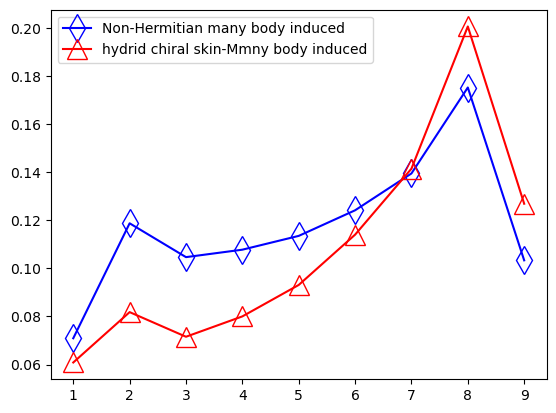

In [13]:
with np.load('TwoExcitationEig9_NotTopology.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany_Not = files['eigval_NHMany']
    eigvec_NHMany_Not = files['eigvec_NHMany']
num_x, num_y = 9, 9
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
popu_indice = QWZ2.Calcu_Occup()
popu_NHMany_Not = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany_Not[k] = np.sum(np.abs(eigvec_NHMany_Not[popu_indice[k],-1])**2)
n_map1 = popu_NHMany_Not.reshape(num_x, 2*num_y).T
# 旋转90度
rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)

with np.load('TwoExcitationEig9.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany_inter = files['eigval_NHMany']
    eigvec_NHMany_inter = files['eigvec_NHMany']
popu_NHMany_inter = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany_inter[k] = np.sum(np.abs(eigvec_NHMany_inter[popu_indice[k],-1])**2) 
n_map2 = popu_NHMany_inter.reshape(num_x, 2*num_y).T
# 旋转90度
rotated_data2 = ndimage.rotate(n_map2, angle=90, reshape=True)


# plt.scatter(np.arange(1,num_x+1, 1), rotated_data1[:,1], facecolors='none', edgecolors='blue', s=50, marker='D')
plt.plot(np.arange(1,num_x+1, 1),rotated_data1[:,1], 'bd-',label='Non-Hermitian many body induced',fillstyle='none', markersize=14)
# plt.plot(np.arange(1,2*num_x+1, 1),rotated_data1[-2], 'gs-',label='NotTopo2',fillstyle='none', markersize=14)

# plt.scatter(np.arange(1,num_x+1, 1), rotated_data2[:,1], facecolors='none', edgecolors='blue', s=50)
plt.plot(np.arange(1,num_x+1, 1),rotated_data2[:,1], 'r^-', label='hydrid chiral skin-Mmny body induced',fillstyle='none', markersize=14)
# plt.plot(np.arange(1,2*num_x+1, 1),rotated_data2[-2], 'k>-', label='inter2',fillstyle='none', markersize=14)
plt.legend()
plt.show()

[0.1573739  0.26281464 0.23494943 0.27639512 0.15883409]
[0.12517408 0.20989532 0.1852929  0.1932151  0.23250159 0.13558747]
[0.10010011 0.16837118 0.14935846 0.15594921 0.16777847 0.20575412
 0.12080973]
[0.08258346 0.13876703 0.12308141 0.12760182 0.13700591 0.15157889
 0.18880247 0.11121388]
[0.15528837 0.22625182 0.20027612 0.26509476 0.16548392]
[0.12511237 0.17421583 0.15104694 0.17073377 0.230683   0.14379365]
[0.09723412 0.13344645 0.11659224 0.13212167 0.15436701 0.21353463
 0.13424229]
[0.07606529 0.10335014 0.09049048 0.10163495 0.12089427 0.14670579
 0.20584477 0.12986851]


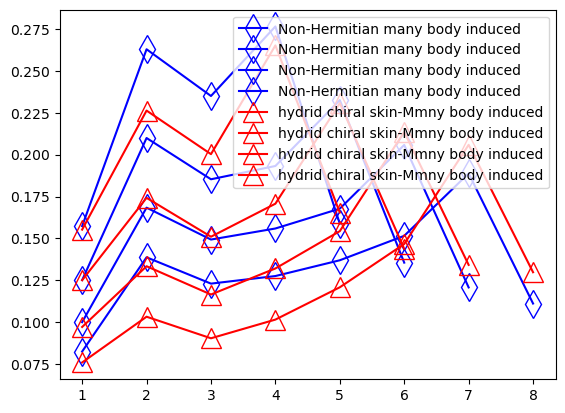

In [41]:
# 不同尺寸，上面的曲线如何变化。
L_list = [5,6,7,8]
data = []
for i in range(len(L_list)):
    num_x, num_y = L_list[i], L_list[i]
    from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
    QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
    QWZ2.add_xhopping_term()
    QWZ2.add_yhopping_term()
    QWZ2.add_onsite_term(-2.1)
    QWZ2.add_NH(0.2)
    QWZ2.add_interaction_inter(1.)
    ham = QWZ2.hamiltonian
    eigval, eigvec = np.linalg.eig(ham)
    eigvec = eigvec[:, np.argsort(np.imag(eigval))]
    eigval = eigval[np.argsort(np.imag(eigval))]

    popu_indice = QWZ2.Calcu_Occup()
    popu_NHMany_Not = np.zeros(QWZ2.total_mode)
    for k in range(2*num_x*num_y): # 应该要加2。
        popu_NHMany_Not[k] = np.sum(np.abs(eigvec[popu_indice[k],-1])**2)
    n_map1 = popu_NHMany_Not.reshape(num_x, 2*num_y).T
    # 旋转90度
    rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
    data.append(rotated_data1)

data1 = []
for i in range(len(L_list)):
    num_x, num_y = L_list[i], L_list[i]
    from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
    QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
    QWZ2.add_xhopping_term()
    QWZ2.add_yhopping_term()
    QWZ2.add_onsite_term(-1.5)
    QWZ2.add_NH(0.2)
    QWZ2.add_interaction_inter(1.)
    ham = QWZ2.hamiltonian
    eigval, eigvec = np.linalg.eig(ham)
    eigvec = eigvec[:, np.argsort(np.imag(eigval))]
    eigval = eigval[np.argsort(np.imag(eigval))]

    popu_indice = QWZ2.Calcu_Occup()
    popu_NHMany_Not = np.zeros(QWZ2.total_mode)
    for k in range(2*num_x*num_y): # 应该要加2。
        popu_NHMany_Not[k] = np.sum(np.abs(eigvec[popu_indice[k],-1])**2)
    n_map1 = popu_NHMany_Not.reshape(num_x, 2*num_y).T
    # 旋转90度
    rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
    data1.append(rotated_data1)

for i in range(len(L_list)):
    plt.plot(np.arange(1,L_list[i]+1, 1),data[i][:,1], 'bd-',label='Non-Hermitian many body induced',fillstyle='none', markersize=14)
    print(data[i][:,1])
# plt.plot(np.arange(1,2*num_x+1, 1),rotated_data1[-2], 'gs-',label='NotTopo2',fillstyle='none', markersize=14)

# plt.scatter(np.arange(1,num_x+1, 1), rotated_data2[:,1], facecolors='none', edgecolors='blue', s=50)
for i in range(len(L_list)):
    plt.plot(np.arange(1,L_list[i]+1, 1),data1[i][:,1], 'r^-', label='hydrid chiral skin-Mmny body induced',fillstyle='none', markersize=14)
    print(data1[i][:,1])
plt.legend()
plt.show()

## 当是耗散非厄米哈密顿量的时候

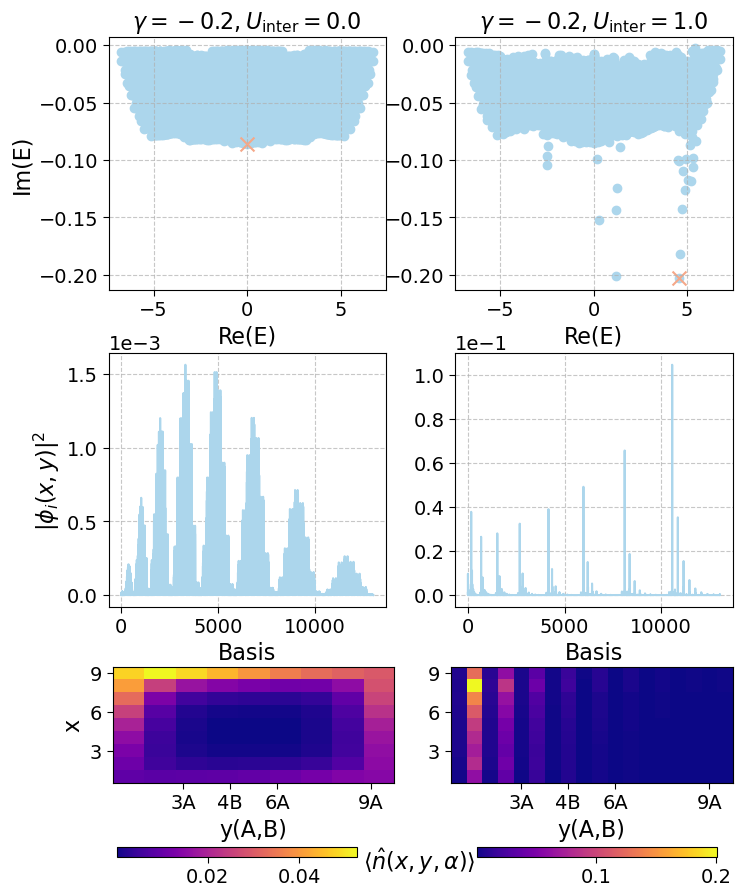

In [268]:
import numpy as np
import matplotlib.pyplot as plt
color_r = '#F5A889'
color_b = '#ACD6EC'
plot_which = 0
with np.load('TwoExcitationEig9_dissipative.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']
num_x, num_y = 9, 9
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem
QWZ2 = ParticleConservedSystem(num_x, num_y, 2)
popu_indice = QWZ2.Calcu_Occup()
popu_NH = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NH[k] = np.sum(np.abs(eigvec_NH[popu_indice[k], plot_which])**2) 
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*num_x*num_y): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(eigvec_NHMany[popu_indice[k], plot_which])**2) 

fontsize = 16
labelsize= 14
fig, ax = plt.subplots(2,2,figsize=(8, 10), sharex='row')
ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[plot_which].real, eigval_NH[plot_which].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany[plot_which].real, eigval_NHMany[plot_which].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)

ax[1, 0].plot(np.abs(eigvec_NH[:,-1])**2, color=color_b)
ax[1, 1].plot(np.abs(eigvec_NHMany[:,plot_which])**2, color=color_b)
ax[1, 0].set_xlabel('Basis',fontsize=fontsize)
ax[1, 1].set_xlabel('Basis',fontsize=fontsize)
ax[1, 0].set_ylabel(r'$\vert \phi_i(x,y)\vert^2$',fontsize=fontsize)
for row in range(2):
    for col in range(2):
        ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
for col in range(2):
    ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = ax[row, col].get_yaxis().get_offset_text()
    # 设置字体大小为12
    offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=-0.2, U_{\mathrm{inter}}=0.0$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=-0.2, U_{\mathrm{inter}}=1.0$', fontsize=fontsize)

from scipy import ndimage
n_map1 = popu_NH.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
# 计算旋转后的坐标范围
n_map2 = popu_NHMany.reshape(num_x, 2*num_y)
# 旋转90度
rotated_data2 = ndimage.rotate(n_map2, angle=90, reshape=True)
# 计算旋转后的坐标范围
color_string = 'plasma'
pos1 = ax[1, 0].get_position()
pos2 = ax[1, 1].get_position()
plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.35,
    top=0.92,
    hspace=0.25,
    wspace=0.25
)
gap = -0.18
ax3 = fig.add_axes([pos1.x0, pos1.y0 - gap - pos1.height/3, pos1.width, pos1.height/3])
ax4 = fig.add_axes([pos2.x0, pos2.y0 - gap - pos1.height/3, pos2.width, pos1.height/3])
vmin, vmax = np.min([np.min(popu_NH), np.min(popu_NHMany)]), np.max([np.max(popu_NH), np.max(popu_NHMany)]) # 但是这样颜色会看不出来。
sm  = ax3.imshow(n_map1, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
sm2 = ax4.imshow(n_map2, 
          aspect='auto',
          origin='lower',
          cmap=color_string)
# vmin=vmin,vmax=vmax,
ax3.set_xlabel('y(A,B)', fontsize=fontsize)
ax4.set_xlabel('y(A,B)', fontsize=fontsize)
ax3.set_ylabel('x', fontsize=fontsize)
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
# ax3.set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax4.set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax3.set_yticks(ticks=[2,5], labels=[5,2])
# ax4.set_yticks(ticks=[2,5], labels=[5,2])
ax3.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
ax4.set_xticks(ticks=[4,7,10,16], labels=['3A','4B','6A','9A'])
ax3.set_yticks(ticks=[2,5,8], labels=[3,6,9])
ax4.set_yticks(ticks=[2,5,8], labels=[3,6,9])

cax = fig.add_axes([0.13, 0.1, 0.3, 0.01]) # [左，下，宽，高]
cbar = plt.colorbar(
    sm,
    cax=cax,
    orientation='horizontal'
)
cax.tick_params(axis='both', which='major', labelsize=labelsize)
# cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
cax.text(cax.get_xlim()[-1]+0.0015, cax.get_ylim()[-1]+0.1, r'$\langle \hat{n}(x,y,\alpha) \rangle$', va='top', ha='left', fontsize=fontsize)

cax2 = fig.add_axes([0.58, 0.1, 0.3, 0.01]) # [左，下，宽，高]
cbar2 = plt.colorbar(
    sm2,
    cax=cax2,
    orientation='horizontal'
)
cax2.tick_params(axis='both', which='major', labelsize=labelsize)
# cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
# cax2.text(cax2.get_xlim()[-1]+0.007, cax2.get_ylim()[-1], r'$\langle \hat{n}(x,y) \rangle$', va='top', ha='left', fontsize=fontsize)
fig.savefig("DataPicture/SI_TwoExcitationSpectrum_loss.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()

## 3D system

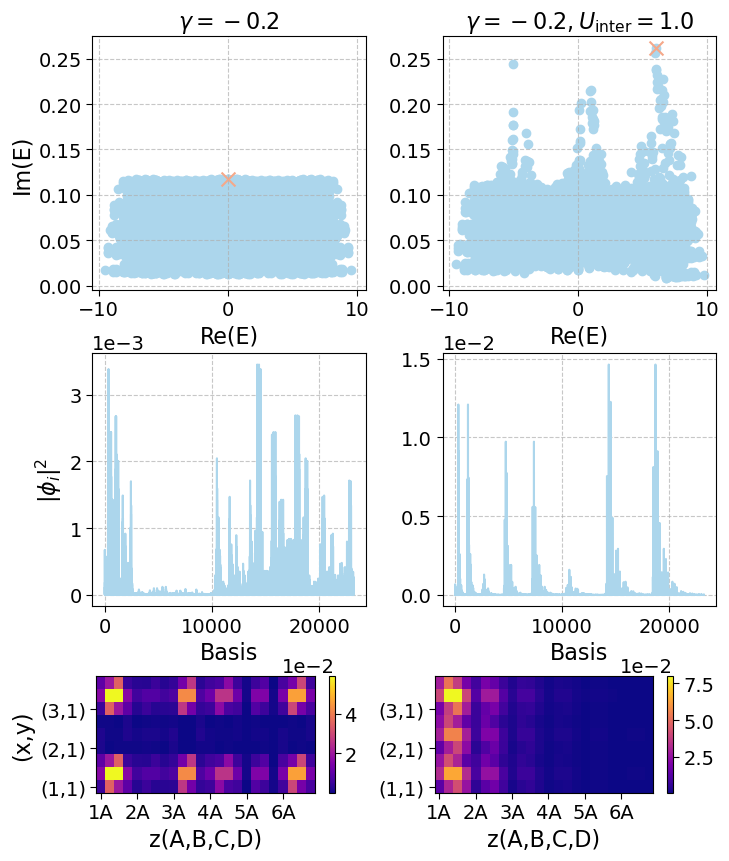

In [81]:
from MeasureNonhermitianSkin.Experimental.ManyBodyCSTI import ParticleConservedSystem_CSTI
num_x, num_y, num_z = 3,3,6
with np.load('3DCSTI_Spectrum_x3_y3_z6.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']

CSTI = ParticleConservedSystem_CSTI(num_x, num_y, num_z, 2)
eigen1 = CSTI.Calcu_Occup(eigvec_NH[:, -1]).reshape((num_x*num_y, 4*num_z))
eigen_non = CSTI.Calcu_Occup(eigvec_NHMany[:, -1]).reshape((num_x*num_y, 4*num_z))

plot_which = -1

fontsize = 16
labelsize= 14
fig, ax = plt.subplots(2, 2,figsize=(8, 10), sharex='row')
ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[plot_which].real, eigval_NH[plot_which].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany[plot_which].real, eigval_NHMany[plot_which].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)

ax[1, 0].plot(np.abs(eigvec_NH[:,-1])**2, color=color_b)
ax[1, 1].plot(np.abs(eigvec_NHMany[:,plot_which])**2, color=color_b)
ax[1, 0].set_xlabel('Basis',fontsize=fontsize)
ax[1, 1].set_xlabel('Basis',fontsize=fontsize)
ax[1, 0].set_ylabel(r'$\vert \phi_i\vert^2$',fontsize=fontsize)
for row in range(2):
    for col in range(2):
        ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
for col in range(2):
    ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = ax[row, col].get_yaxis().get_offset_text()
    # 设置字体大小为12
    offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=-0.2$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=-0.2, U_{\mathrm{inter}}=1.0$', fontsize=fontsize)

from scipy import ndimage
# n_map1 = popu_NH.reshape(num_x, 2*num_y).T
# # 旋转90度
# rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
# # 计算旋转后的坐标范围
# n_map2 = popu_NHMany.reshape(num_x, 2*num_y).T
# # 旋转90度
# rotated_data2 = ndimage.rotate(n_map2, angle=90, reshape=True)
# # 计算旋转后的坐标范围
color_string = 'plasma'
pos1 = ax[1, 0].get_position()
pos2 = ax[1, 1].get_position()
plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.35,
    top=0.92,
    hspace=0.25,
    wspace=0.28
)
gap = -0.17
ax3 = fig.add_axes([pos1.x0, pos1.y0 - gap - pos1.height/3, 0.97*pos1.width, pos1.height/3])
ax4 = fig.add_axes([pos2.x0, pos2.y0 - gap - pos1.height/3, 0.97*pos2.width, pos1.height/3])
vmin, vmax = np.min([np.min(popu_NH), np.min(popu_NHMany)]), np.max([np.max(popu_NH), np.max(popu_NHMany)]) # 但是这样颜色会看不出来。
ax3.sharex(ax4) # ：表示 ax3 和 ax4 共享 x 轴。
ax3.sharey(ax4) # ：表示 ax3 和 ax4 共享 y 轴。

im1 = ax3.imshow(eigen1, aspect='auto', origin='lower', cmap=color_string)  # aspect是auto的话，纵向是一样的。
im2 = ax4.imshow(eigen_non, aspect='auto', origin='lower', cmap=color_string)
ax3.set_xticks(ticks=[0,4,8,12,16,20], labels=['1A','2A','3A','4A','5A','6A'])
ax3.set_yticks(ticks=list(range(0,num_x*num_y,num_y)), labels=['(%d,1)'%x for x in range(1, num_x+1, 1)])
ax3.set_ylabel('(x,y)', fontsize=fontsize)
ax3.set_xlabel('z(A,B,C,D)', fontsize=fontsize)
ax4.set_xlabel('z(A,B,C,D)', fontsize=fontsize)
# ax4.set_ylabel('(x,y)' fontsize=fontsize)
ax4.set_xticks(ticks=[0,4,8,12,16,20], labels=['1A','2A','3A','4A','5A','6A'])
# ax4.set_yticks(ticks=list(range(0,num_x*num_y,num_y)), labels=['(%d,1)'%x for x in range(1, num_x+1, 1)])
cbar1 = plt.colorbar(im1, ax=ax3, fraction=0.15)  # 关联到第一个axes
cbar2 = plt.colorbar(im2, ax=ax4, fraction=0.15)  # 关联到第一个axes
ax3.tick_params(axis='both', which='major', labelsize=labelsize)
ax4.tick_params(axis='both', which='major', labelsize=labelsize)
cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
cbar2.ax.tick_params(axis='both', which='major', labelsize=labelsize)
# cbar用科学计数法，并加大字体
cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar1.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)
cbar2.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
offset_text = cbar2.ax.get_yaxis().get_offset_text()
offset_text.set_fontsize(labelsize)

# sm  = ax3.imshow(rotated_data1, 
#           aspect='auto',
#           origin='lower',
#           cmap=color_string)
# sm2 = ax4.imshow(rotated_data2, 
#           aspect='auto',
#           origin='lower',
#           cmap=color_string)

# ax3.set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax4.set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax3.set_yticks(ticks=[2,5], labels=[5,2])
# ax4.set_yticks(ticks=[2,5], labels=[5,2])


# cax = fig.add_axes([0.13, 0.1, 0.3, 0.01]) # [左，下，宽，高]
# cbar = plt.colorbar(
#     sm,
#     cax=cax,
#     orientation='horizontal'
# )
# cax.tick_params(axis='both', which='major', labelsize=labelsize)
# # cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
# cax.text(cax.get_xlim()[-1]+0.0015, cax.get_ylim()[-1]+0.1, r'$\langle \hat{n}(x,y,\alpha) \rangle$', va='top', ha='left', fontsize=fontsize)

# cax2 = fig.add_axes([0.58, 0.1, 0.3, 0.01]) # [左，下，宽，高]
# cbar2 = plt.colorbar(
#     sm2,
#     cax=cax2,
#     orientation='horizontal'
# )
# cax2.tick_params(axis='both', which='major', labelsize=labelsize)
# cax.set_label(r'$\langle \hat{n}(x,y) \rangle$')
# cax2.text(cax2.get_xlim()[-1]+0.007, cax2.get_ylim()[-1], r'$\langle \hat{n}(x,y) \rangle$', va='top', ha='left', fontsize=fontsize)
fig.savefig("DataPicture/SI_3DCSTISpetrum.pdf", bbox_inches='tight') # , bbox_extra_artists=[legend]
plt.show()

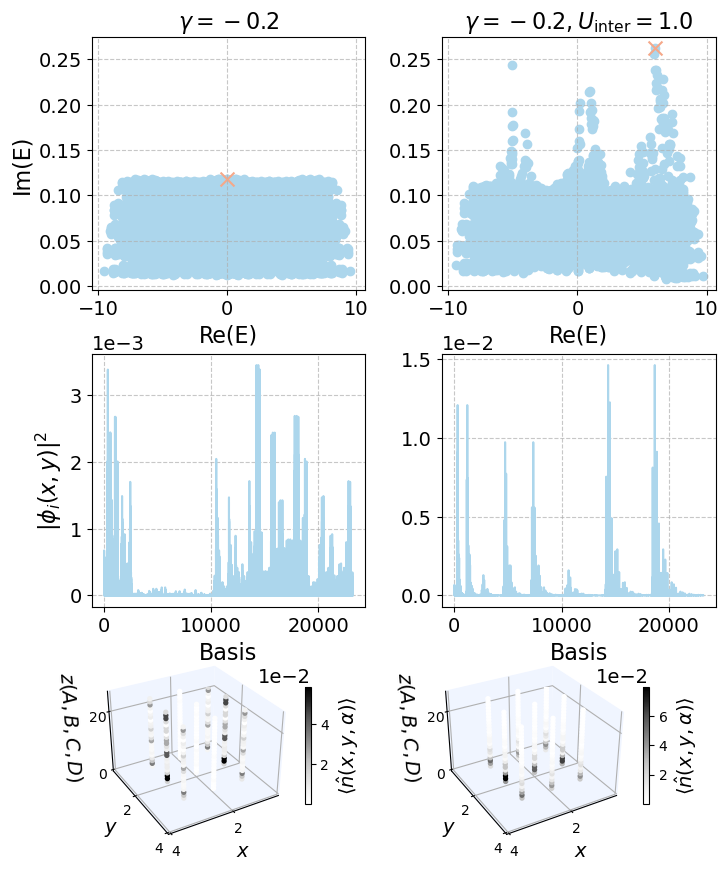

In [88]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from matplotlib.colors import Normalize
import matplotlib.colors as mcolors
from MeasureNonhermitianSkin.Experimental.ManyBodyCSTI import ParticleConservedSystem_CSTI

num_x, num_y, num_z = 3,3,6
with np.load('3DCSTI_Spectrum_x3_y3_z6.npz') as files:
    eigval_NH = files['eigval_NH']
    eigvec_NH = files['eigvec_NH']
    eigval_NHMany = files['eigval_NHMany']
    eigvec_NHMany = files['eigvec_NHMany']

CSTI = ParticleConservedSystem_CSTI(num_x, num_y, num_z, 2)
eigen1 = CSTI.Calcu_Occup(eigvec_NH[:, -1]).reshape((num_x*num_y, 4*num_z))
eigen_non = CSTI.Calcu_Occup(eigvec_NHMany[:, -1]).reshape((num_x*num_y, 4*num_z))

plot_which = -1

fontsize = 16
labelsize= 14
fig, ax = plt.subplots(2, 2,figsize=(8, 10), sharex='row')
ax[0, 1].get_shared_y_axes().join(ax[0,0], ax[0,1]) # 上面两个轴共享y轴
ax[0, 0].scatter(eigval_NH.real, eigval_NH.imag, color=color_b)
ax[0, 0].scatter(eigval_NH[plot_which].real, eigval_NH[plot_which].imag, color=color_r, s=100, marker='x')
ax[0, 1].scatter(eigval_NHMany.real, eigval_NHMany.imag, color=color_b)
ax[0, 1].scatter(eigval_NHMany[plot_which].real, eigval_NHMany[plot_which].imag, color=color_r, s=100, marker='x')
ax[0, 0].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 1].set_xlabel('Re(E)',fontsize=fontsize)
ax[0, 0].set_ylabel('Im(E)',fontsize=fontsize)

ax[1, 0].plot(np.abs(eigvec_NH[:,-1])**2, color=color_b)
ax[1, 1].plot(np.abs(eigvec_NHMany[:,plot_which])**2, color=color_b)
ax[1, 0].set_xlabel('Basis',fontsize=fontsize)
ax[1, 1].set_xlabel('Basis',fontsize=fontsize)
ax[1, 0].set_ylabel(r'$\vert \phi_i(x,y)\vert^2$',fontsize=fontsize)
for row in range(2):
    for col in range(2):
        ax[row, col].grid(True, linestyle='--', alpha=0.7)
        ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)

        # 设置y轴为科学计数法
        #ax[row, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        # 获取当前子图的y轴偏移文本
        offset_text = ax[row, col].get_yaxis().get_offset_text()
        # 设置字体大小为12
        offset_text.set_fontsize(labelsize)
for col in range(2):
    ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = ax[row, col].get_yaxis().get_offset_text()
    # 设置字体大小为12
    offset_text.set_fontsize(labelsize)
ax[0, 0].set_title(r'$\gamma=-0.2$', fontsize=fontsize)
ax[0, 1].set_title(r'$\gamma=-0.2, U_{\mathrm{inter}}=1.0$', fontsize=fontsize)

from scipy import ndimage
# n_map1 = popu_NH.reshape(num_x, 2*num_y).T
# # 旋转90度
# rotated_data1 = ndimage.rotate(n_map1, angle=90, reshape=True)
# # 计算旋转后的坐标范围
# n_map2 = popu_NHMany.reshape(num_x, 2*num_y).T
# # 旋转90度
# rotated_data2 = ndimage.rotate(n_map2, angle=90, reshape=True)
# # 计算旋转后的坐标范围
color_string = 'plasma'
pos1 = ax[1, 0].get_position()
pos2 = ax[1, 1].get_position()
plt.subplots_adjust(
    left=0.12,
    right=0.9,
    bottom=0.35,
    top=0.92,
    hspace=0.25,
    wspace=0.28
)
gap = -0.16
ax3 = fig.add_axes([pos1.x0-0.07, pos1.y0 - gap - pos1.height/3, 0.97*pos1.width, pos1.height/3], projection='3d')
ax4 = fig.add_axes([pos2.x0-0.07, pos2.y0 - gap - pos1.height/3, 0.97*pos2.width, pos1.height/3], projection='3d')
vmin, vmax = np.min([np.min(popu_NH), np.min(popu_NHMany)]), np.max([np.max(popu_NH), np.max(popu_NHMany)]) # 但是这样颜色会看不出来。
ax3.sharex(ax4) # ：表示 ax3 和 ax4 共享 x 轴。
ax3.sharey(ax4) # ：表示 ax3 和 ax4 共享 y 轴。

# ax1 = fig.add_subplot(1, 2, 1, projection='3d')
# ax2 = fig.add_subplot(1, 2, 2, projection='3d')

# im1 = ax3.imshow(eigen1, aspect='auto', origin='lower', cmap=color_string)  # aspect是auto的话，纵向是一样的。
# im2 = ax4.imshow(eigen_non, aspect='auto', origin='lower', cmap=color_string)

def set_axes_equal(ax):
    '''Make 3D axes have equal scale (for better spatial perspective)'''
    x_limits = ax.get_xlim3d()
    y_limits = ax.get_ylim3d()
    z_limits = ax.get_zlim3d()
    x_range = abs(x_limits[1] - x_limits[0])
    y_range = abs(y_limits[1] - y_limits[0])
    z_range = abs(z_limits[1] - z_limits[0])
    max_range = max(x_range, y_range, z_range)
    x_middle = np.mean(x_limits)
    y_middle = np.mean(y_limits)
    z_middle = np.mean(z_limits)
    ax.set_xlim3d([0.5, 4])
    ax.set_ylim3d([0.5, 4])
    ax.set_zlim3d([0,26])

    ax.set_xlabel(r'$x$', labelpad=-10, fontsize=labelsize)
    ax.set_ylabel(r'$y$', labelpad=-10, fontsize=labelsize)
    ax.set_zlabel(r'$z(A,B,C,D)$', labelpad=-10, fontsize=labelsize)
    ax.tick_params(axis='x', pad=-5)
    ax.tick_params(axis='y', pad=-5)
    ax.tick_params(axis='z', pad=-5)

    # 背景颜色
    bgcolor = (240/255, 245/255, 255/255)  # rgba(240,246,255,1)
    ax.w_xaxis.set_pane_color(bgcolor + (1.0,))
    ax.w_yaxis.set_pane_color(bgcolor + (1.0,))
    ax.w_zaxis.set_pane_color(bgcolor + (1.0,))
    #设置视角，模拟 Plotly 默认视角 和距离
    ax.view_init(elev=30, azim=60)
    ax.dist = 6  # 默认为10，尝试调整到7
labelsize = 14

color_string = 'Greys'
def PlotData1(ax, coordinate, data_c):
    # 对 ax1 的数据
    norm1 = Normalize(vmin=np.min(data_c), vmax=np.max(data_c))
    cmap = cm.get_cmap(color_string)
    rgb1 = cmap(norm1(data_c))
    # rgb1[:, 3] = norm1(data_c)*(1-alpha)+alpha # norm1(data_c)

    perceived_rgb = rgb1
    perceived_cmap = mcolors.ListedColormap(perceived_rgb)
    mappable1 = cm.ScalarMappable(norm=norm1, cmap=color_string)

    x1, y1, z1 = coordinate[0], coordinate[1], coordinate[2]
    # 第一个子图
    p1 = ax.scatter(x1, y1, z1, c=data_c, cmap=color_string, s=8, depthshade=False) # 'inferno_r'
    cb1 = fig.colorbar(mappable1, ax=ax, fraction=0.03, pad=0.2)
    cb1.set_label(r'$\langle \hat{n}(x,y,\alpha) \rangle$', fontsize=labelsize)
    cb1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
    offset_text = cb1.ax.get_yaxis().get_offset_text()
    offset_text.set_fontsize(labelsize)

# plot the data and set the axis. 
x1, y1, z1 = np.where(eigen1.reshape((3,3,4*6))>0)
PlotData1(ax3, [x1+1,y1+1,z1+1], eigen1.reshape((3,3,4*6)))
PlotData1(ax4, [x1+1,y1+1,z1+1], eigen_non.reshape((3,3,4*6)))
set_axes_equal(ax3)
set_axes_equal(ax4)

# ax3.set_xticks(ticks=[0,4,8,12,16,20], labels=['1A','2A','3A','4A','5A','6A'])
# ax3.set_yticks(ticks=list(range(0,num_x*num_y,num_y)), labels=['(%d,1)'%x for x in range(1, num_x+1, 1)])
# ax3.set_ylabel('(x,y)', fontsize=fontsize)
# ax3.set_xlabel('z(A,B,C,D)', fontsize=fontsize)
# ax4.set_xlabel('z(A,B,C,D)', fontsize=fontsize)
# # ax4.set_ylabel('(x,y)' fontsize=fontsize)
# ax4.set_xticks(ticks=[0,4,8,12,16,20], labels=['1A','2A','3A','4A','5A','6A'])
# # ax4.set_yticks(ticks=list(range(0,num_x*num_y,num_y)), labels=['(%d,1)'%x for x in range(1, num_x+1, 1)])
# cbar1 = plt.colorbar(im1, ax=ax3, fraction=0.15)  # 关联到第一个axes
# cbar2 = plt.colorbar(im2, ax=ax4, fraction=0.15)  # 关联到第一个axes
# ax3.tick_params(axis='both', which='major', labelsize=labelsize)
# ax4.tick_params(axis='both', which='major', labelsize=labelsize)
# cbar1.ax.tick_params(axis='both', which='major', labelsize=labelsize)
# cbar2.ax.tick_params(axis='both', which='major', labelsize=labelsize)
# # cbar用科学计数法，并加大字体
# cbar1.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
# offset_text = cbar1.ax.get_yaxis().get_offset_text()
# offset_text.set_fontsize(labelsize)
# cbar2.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
# offset_text = cbar2.ax.get_yaxis().get_offset_text()
# offset_text.set_fontsize(labelsize)
fig.savefig("DataPicture/SI_3DCSTISpetrum2.pdf", bbox_inches='tight') # , 
plt.show()


[ 25   2  49  26 169 170 146 193 146 193 169 170] [  2  25  26  49 146 146 169 169 170 170 193 193]


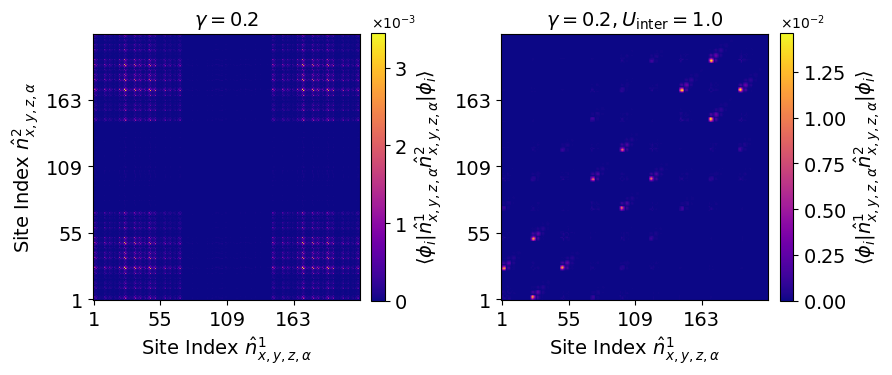

In [106]:
# with np.load('3DCSTI_Spectrum_x3_y3_z6.npz') as files:
#     eigval_NH = files['eigval_NH']
#     eigvec_NH = files['eigvec_NH']
#     eigval_NHMany = files['eigval_NHMany']
#     eigvec_NHMany = files['eigvec_NHMany']

num_x, num_y, num_z = 3,3,6
d_indice = np.tril_indices(4*num_x*num_y*num_z, k=-1)
d_NH = np.zeros((4*num_x*num_y*num_z, 4*num_x*num_y*num_z))
d_NH_inter = np.zeros((4*num_x*num_y*num_z, 4*num_x*num_y*num_z))
d_NH[d_indice] = np.abs(eigvec_NH[:,-1])**2
d_NH = d_NH + d_NH.T
d_NH_inter[d_indice] = np.abs(eigvec_NHMany[:,-1])**2
d_NH_inter = d_NH_inter + d_NH_inter.T

data_matrices = [d_NH, d_NH_inter]
vmin, vmax = np.min([np.min(d_NH), np.min(d_NH_inter)]), np.max([np.max(d_NH), np.max(d_NH_inter)])
ys, xs = np.where(data_matrices[1] > 0.01)
radius = 10
color_string = 'plasma'
print(xs, ys)

fig, ax = plt.subplots(1, 2, figsize=(10, 8))
fontsize = 14

for temp_ax, matrix in zip(ax, data_matrices):
    # 绘制矩阵（强制正方形）
    img = temp_ax.imshow(matrix, cmap=color_string, 
                        origin='lower', aspect='equal',  # 关键修改：保证正方形
                        #vmin=vmin, vmax=vmax
                        )
    
    # 设置标题和标签（x和y相同）
    # temp_ax.set_title(title, pad=15)
    temp_ax.set_xlabel(r'Site Index $\hat{n}^1_{x,y,z,\alpha}$', fontsize=fontsize)
    # temp_ax.set_ylabel(r'Site Index $\hat{n}^2_{x,y,\alpha}$')
    
    # 设置刻度
    n = matrix.shape[0]
    step = max(1, n//4)  # 减少刻度密度
    temp_ax.set_xticks(np.arange(0, n, step), np.arange(1, n, step))
    temp_ax.set_yticks(np.arange(0, n, step), np.arange(1, n, step))
    temp_ax.tick_params(axis='both', labelsize=fontsize)
    
    # 添加colorbar（使用科学计数法）
    cbar = fig.colorbar(img, ax=temp_ax, fraction=0.046, pad=0.04)
    cbar.formatter = sci_formatter
    cbar.update_normal(img)
    cbar.ax.yaxis.set_offset_position('left')  # 科学计数法偏移位置
    # cbar.set_label(r'$\langle \phi_i \vert \hat{n}^1_{x,y,\alpha} \hat{n}^2_{x,y,\alpha} \vert \phi_i \rangle$', rotation=0, labelpad=-40)
    # cbar.ax.set_title(r'$\langle \phi_i \vert \hat{n}^1_{x,y,z,\alpha} \hat{n}^2_{x,y,z,\alpha} \vert \phi_i \rangle$', pad=18, fontsize=fontsize)
    cbar.ax.set_ylabel(r'$\langle \phi_i \vert \hat{n}^1_{x,y,z,\alpha} \hat{n}^2_{x,y,z,\alpha} \vert \phi_i \rangle$', fontsize=fontsize)
    current_pos = cbar.ax.title.get_position()
    cbar.ax.title.set_position((current_pos[0] - 1.2, current_pos[1]))  # 向左移动 0.03
    cbar.ax.tick_params(axis='both', labelsize=fontsize)
ax[0].set_ylabel(r'Site Index $\hat{n}^2_{x,y,z,\alpha}$', fontsize=fontsize)
ax[0].set_title(r'$\gamma=0.2$', fontsize=fontsize)
ax[1].set_title(r'$\gamma=0.2,U_{\mathrm{inter}}=1.0$', fontsize=fontsize)
# # 添加多个圆圈
# for x, y in zip(xs, ys):
#     circle = Circle((x, y), radius=radius, edgecolor='white', facecolor='none', linewidth=2, alpha=0.8)
#     ax[1, 1].add_patch(circle)

# for row in range(2):
#     for col in range(2):
#         # ax[row, col].grid(True, linestyle='--', alpha=0.7)
#         ax[row, col].tick_params(axis='both', which='major', labelsize=labelsize)
fig.subplots_adjust(left=0.2, right=0.9, 
                   bottom=0.07, top=0.9,
                   wspace=0.4, hspace=0.25)
fig.savefig("DataPicture/3D_correlation.pdf", bbox_inches='tight') # , 
plt.show()

## 更大系统的，双激发的本征态，Lanzcos方法。

eigval_NHMany10 /eigval_NHMany10
eigval_NHMany12 /eigval_NHMany12
eigval_NHMany14 /eigval_NHMany14
eigval_NHMany16 /eigval_NHMany16
eigval_NHMany18 /eigval_NHMany18
eigvec_NHMany10 /eigvec_NHMany10
eigvec_NHMany12 /eigvec_NHMany12
eigvec_NHMany14 /eigvec_NHMany14
eigvec_NHMany16 /eigvec_NHMany16
eigvec_NHMany18 /eigvec_NHMany18
[1.16168417+0.2011912j  4.54151434+0.20232384j]
[1.16070008+0.19982402j 4.54412165+0.20072271j]
[4.5460644 +0.19972829j 1.16085505+0.20010302j]
[4.547446  +0.19912235j 1.16014039+0.20032199j]
[1.17150218+0.19442355j 4.54841625+0.1987394j ]


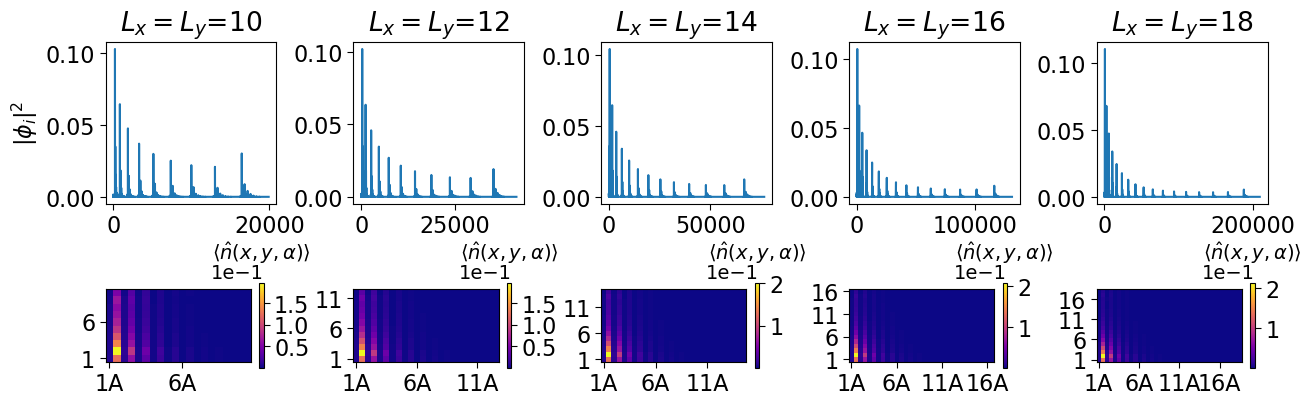

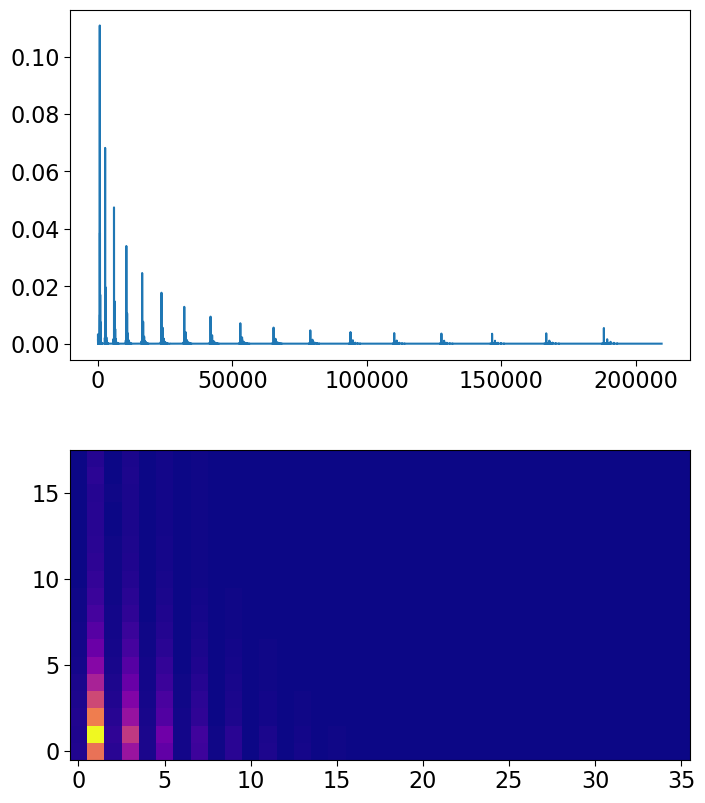

In [289]:
import h5py
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem_Coo
fig, ax = plt.subplots(2, 5, figsize=(14, 5))
L_list = [10, 12, 14, 16, 18]
plot_which = [-1, -1, -2, -2, -1] # imaginary unstable.
color_string = 'plasma'

plt.subplots_adjust(
    left=0.12,
    right=0.95,
    bottom=0.15,
    top=0.92,
    hspace=-0.1,
    wspace=0.45
)

with h5py.File('TwoExcitationLargerSpectrum.h5', 'r') as files:
    for key in files.keys():
        print(key, files[key].name)
    for i in range(len(L_list)):
        eigval = files['eigval_NHMany%d'%(L_list[i])][:]
        print(eigval)
        # ax[0].scatter(eigval.real, eigval.imag)
        # ax[1].plot(np.abs(files['eigvec_NHMany%d'%(L_list[i])][:][:,-1])**2)   # eigenstate
        ax[0, i].plot(np.abs(files['eigvec_NHMany%d'%(L_list[i])][:][:,plot_which[i]])**2)
        # 画粒子数算符的
        ax[0, i].set_title(r'$L_x=L_y$'+'=%d'%L_list[i])

        pos = ax[0, i].get_position()
        new_pos = [pos.x0, pos.y0 + 0.08, pos.width, pos.height - 0.08]  # y方向增加0.02
        ax[0, i].set_position(new_pos)
        pos = ax[1, i].get_position()
        new_pos = [pos.x0, pos.y0 - 0.2, pos.width, pos.height + 0.1]
        ax[1, i].set_position(new_pos)

        QWZ2 = ParticleConservedSystem_Coo(L_list[i], L_list[i], 2)
        popu_indice = QWZ2.Calcu_Occup()
        popu_NHMany = np.zeros(QWZ2.total_mode)
        for k in range(2*L_list[i]**2): # 应该要加2。
            popu_NHMany[k] = np.sum(np.abs(files['eigvec_NHMany%d'%(L_list[i])][:][popu_indice[k], plot_which[i]])**2)
        im1 = ax[1,i].imshow(popu_NHMany.reshape(L_list[i], 2*L_list[i]), origin='lower', cmap=color_string)

        cbar = plt.colorbar(im1, ax=ax[1,i], fraction=0.1, shrink=0.42)
        # cbar2.ax.tick_params(axis='both', which='major', labelsize=labelsize)

        cbar.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        offset_text = cbar.ax.get_yaxis().get_offset_text()
        offset_text.set_fontsize(labelsize)
        cbar.ax.set_title(r'$\langle \hat{n}(x,y,\alpha)\rangle$', pad=17, fontsize=14)
ax[0,0].set_ylabel(r'$\vert \phi_i \vert^2$')

ax[1,0].set_xticks(ticks=[0,10], labels=['1A','6A'])
ax[1,0].set_yticks(ticks=[0,5], labels=['1','6'])

ax[1,1].set_xticks(ticks=[0,10,20], labels=['1A','6A','11A'])
ax[1,1].set_yticks(ticks=[0,5,10], labels=['1','6','11'])

ax[1,2].set_xticks(ticks=[0,10,20], labels=['1A','6A','11A'])
ax[1,2].set_yticks(ticks=[0,5,10], labels=['1','6','11'])

ax[1,3].set_xticks(ticks=[0,10,20,30], labels=['1A','6A','11A','16A'])
ax[1,3].set_yticks(ticks=[0,5,10,15], labels=['1','6','11','16'])

ax[1,4].set_xticks(ticks=[0,10,20,30], labels=['1A','6A','11A','16A'])
ax[1,4].set_yticks(ticks=[0,5,10,15], labels=['1','6','11','16'])

# for i in range(len(L_list)):
#     pos = ax[0, i].get_position()
#     new_pos = [pos.x0, pos.y0 + 0.05, pos.width, pos.height - 0.05]  # y方向增加0.02
#     ax[0, i].set_position(new_pos)

#     pos = ax[1, i].get_position()
#     new_pos = [pos.x0, pos.y0, pos.width, pos.height + 0.05]
#     ax[1, i].set_position(new_pos)

plt.show()
fig.savefig('DataPicture/LargeTwoExcitation.pdf', bbox_inches='tight')

files = h5py.File('TwoExcitationLargerSpectrum.h5', 'r')
fig , ax = plt.subplots(2, 1, figsize=(8,10))
ax[0].plot(np.abs(files['eigvec_NHMany18'][:][:,-1])**2)
QWZ2 = ParticleConservedSystem_Coo(L_list[i], L_list[i], 2)
popu_indice = QWZ2.Calcu_Occup()
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*L_list[i]**2): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(files['eigvec_NHMany%d'%(L_list[i])][:][popu_indice[k], -1])**2)
im1 = ax[1].imshow(popu_NHMany.reshape(L_list[i], 2*L_list[i]), origin='lower', cmap=color_string)
# fig.savefig('DataPicture/Fig_SI.pdf')
files.close()

Processing interaction:


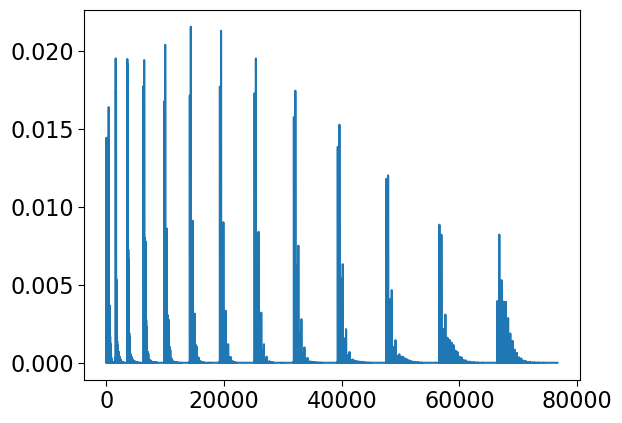

In [38]:
with h5py.File('TwoExcitationLargerSpectrum.h5', 'r') as files:
    eigvec = files['eigvec_NHMany%d'%(L_list[i])][:][:,-2]

from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem_Coo
num_x = 14 # 19600 for 5 and 4960 for 4. 3h for 5.
num_y = 14
QWZ2 = ParticleConservedSystem_Coo(num_x, num_y, 2)
QWZ2.add_onsite_term(-1.5)
QWZ2.add_NH(0.2)
QWZ2.add_xhopping_term()
QWZ2.add_yhopping_term()
QWZ2.add_interaction_inter(1.)
popu_indice = QWZ2.Calcu_Occup()
import scipy
hamiltonian_sparse = scipy.sparse.coo_matrix((QWZ2.data, (QWZ2.row, QWZ2.col)), shape=(QWZ2.dimension, QWZ2.dimension))
print('Processing interaction:')
# eigval2, eigvec2 = np.linalg.eig(hamiltonian)  # 大概40min
import scipy
# hamiltonian_sparse = scipy.sparse.coo_matrix(hamiltonian)
eigval2, eigvec2 = scipy.sparse.linalg.eigs(hamiltonian_sparse,k=2, which='LI', v0=eigvec)
eigvec2 = eigvec2[:, np.argsort(np.imag(eigval2))]
eigval2 = eigval2[np.argsort(np.imag(eigval2))]
plt.plot(np.abs(eigvec2[:,-1])**2)
plt.show()
print(eigval)
# 一次的结果是对的，一次不对

(76636,)
Processing interaction:


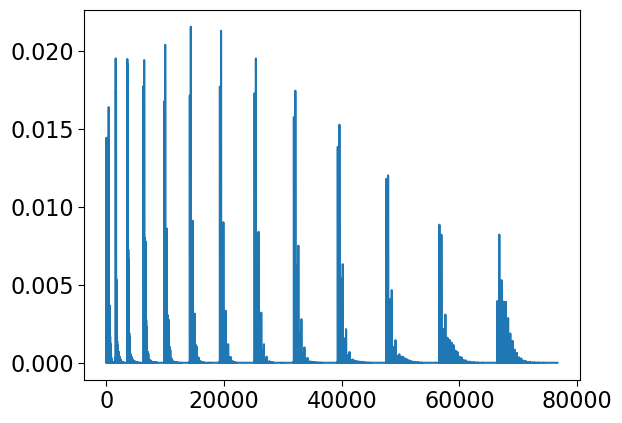

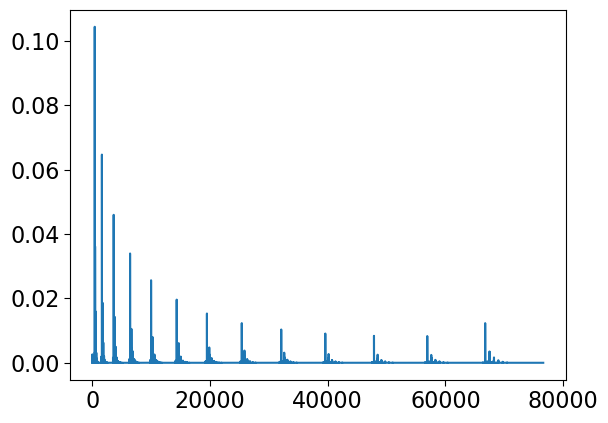

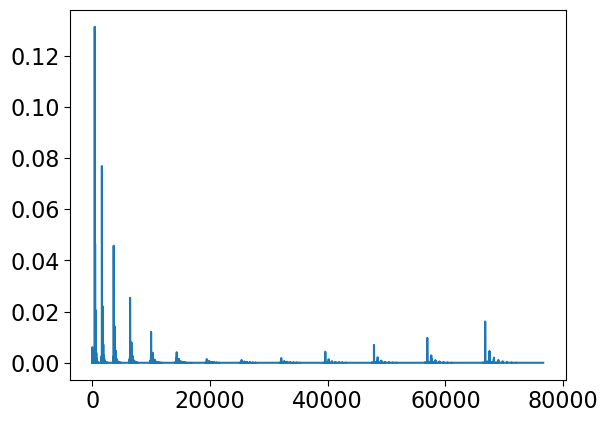

[4.56180275+0.19107287j 4.5460644 +0.19972829j 1.16085505+0.20010302j]


In [43]:
with h5py.File('TwoExcitationLargerSpectrum.h5', 'r') as files:
    eigvec = files['eigvec_NHMany14'][:][:,-2]

print(np.shape(eigvec))
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem_Coo
num_x = 14 # 19600 for 5 and 4960 for 4. 3h for 5.
num_y = 14
QWZ2 = ParticleConservedSystem_Coo(num_x, num_y, 2)
QWZ2.add_onsite_term(-1.5)
QWZ2.add_NH(0.2)
QWZ2.add_xhopping_term()
QWZ2.add_yhopping_term()
QWZ2.add_interaction_inter(1.)
popu_indice = QWZ2.Calcu_Occup()
import scipy
hamiltonian_sparse = scipy.sparse.coo_matrix((QWZ2.data, (QWZ2.row, QWZ2.col)), shape=(QWZ2.dimension, QWZ2.dimension))
print('Processing interaction:')
# eigval2, eigvec2 = np.linalg.eig(hamiltonian)  # 大概40min
import scipy
# hamiltonian_sparse = scipy.sparse.coo_matrix(hamiltonian)
eigval2, eigvec2 = scipy.sparse.linalg.eigs(hamiltonian_sparse,k=3, which='LI', v0=eigvec)
eigvec2 = eigvec2[:, np.argsort(np.imag(eigval2))]
eigval2 = eigval2[np.argsort(np.imag(eigval2))]
plt.plot(np.abs(eigvec2[:,-1])**2)
plt.show()
plt.plot(np.abs(eigvec2[:,-2])**2)
plt.show()
plt.plot(np.abs(eigvec2[:,-3])**2)
plt.show()
print(eigval2)

eigval_NHMany10 /eigval_NHMany10
eigval_NHMany12 /eigval_NHMany12
eigval_NHMany14 /eigval_NHMany14
eigval_NHMany16 /eigval_NHMany16
eigval_NHMany18 /eigval_NHMany18
eigvec_NHMany10 /eigvec_NHMany10
eigvec_NHMany12 /eigvec_NHMany12
eigvec_NHMany14 /eigvec_NHMany14
eigvec_NHMany16 /eigvec_NHMany16
eigvec_NHMany18 /eigvec_NHMany18
[5.77648958+0.1769929j  5.66482037+0.20285688j 5.62726715+0.21586354j]
[1.17013567+0.18837184j 5.65337182+0.20656616j 5.62849445+0.21579166j]
[5.70757767+0.19091898j 5.64660484+0.20884362j 5.62929057+0.2157078j ]
[5.68986038+0.19565566j 5.64245148+0.21034749j 5.62987667+0.21563076j]
[5.67763952+0.19922997j 5.6397493 +0.211399j   5.63032381+0.21556936j]


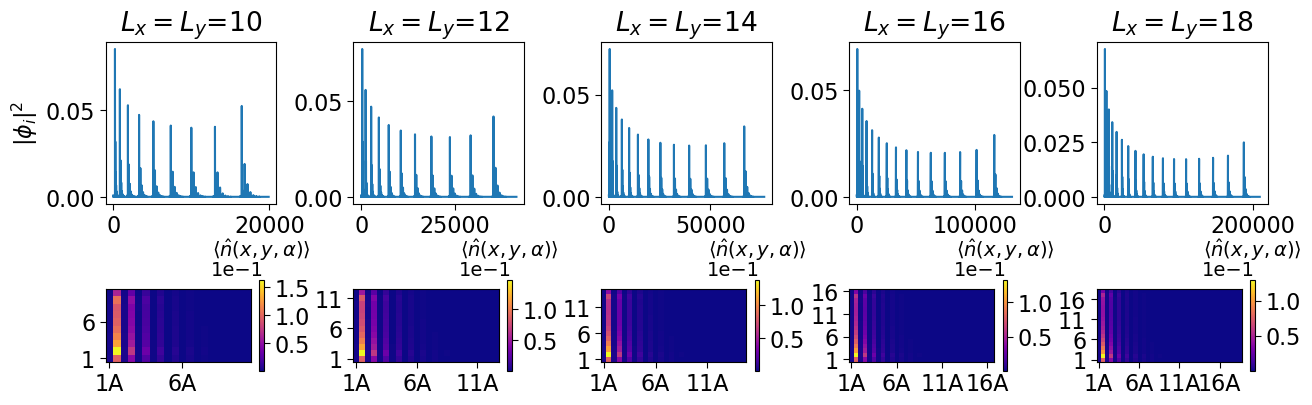

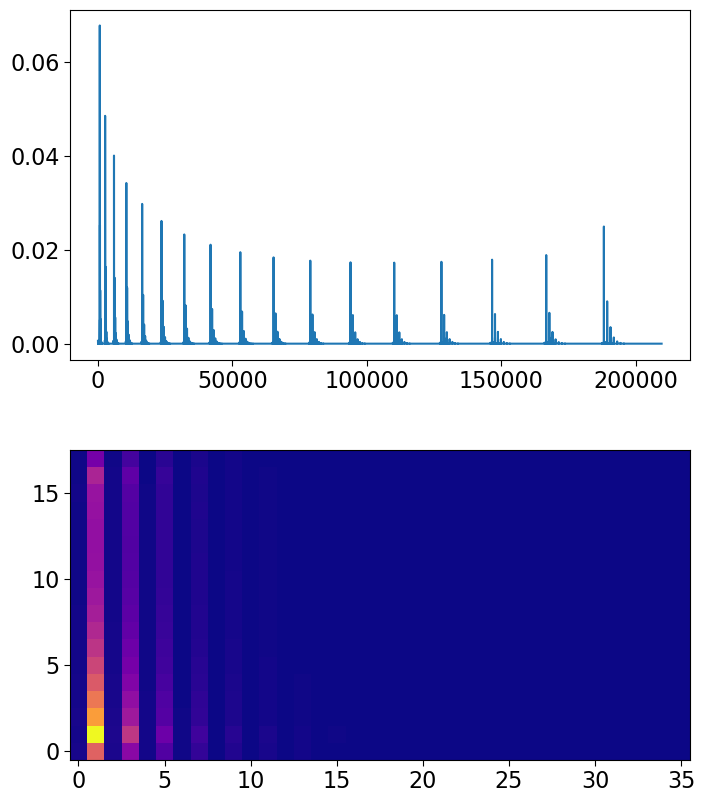

In [288]:
import h5py
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem_Coo
fig, ax = plt.subplots(2, 5, figsize=(14, 5))
L_list = [10, 12, 14, 16, 18]
plot_which = [-1, -1, -1, -1, -1] # imaginary unstable.
color_string = 'plasma'
plt.subplots_adjust(
    left=0.12,
    right=0.95,
    bottom=0.15,
    top=0.92,
    hspace=-0.1,
    wspace=0.45
)

with h5py.File('TwoExcitationLargerSpectrum_NotTopo_u-2.1.h5', 'r') as files:
    for key in files.keys():
        print(key, files[key].name)
    for i in range(len(L_list)):
        eigval = files['eigval_NHMany%d'%(L_list[i])][:]
        print(eigval)
        # ax[0].scatter(eigval.real, eigval.imag)
        # ax[1].plot(np.abs(files['eigvec_NHMany%d'%(L_list[i])][:][:,-1])**2)   # eigenstate
        ax[0, i].plot(np.abs(files['eigvec_NHMany%d'%(L_list[i])][:][:,plot_which[i]])**2)
        # 画粒子数算符的
        ax[0, i].set_title(r'$L_x=L_y$'+'=%d'%L_list[i])

        pos = ax[0, i].get_position()
        new_pos = [pos.x0, pos.y0 + 0.08, pos.width, pos.height - 0.08]  # y方向增加0.02
        ax[0, i].set_position(new_pos)
        pos = ax[1, i].get_position()
        new_pos = [pos.x0, pos.y0 - 0.2, pos.width, pos.height + 0.1]
        ax[1, i].set_position(new_pos)

        QWZ2 = ParticleConservedSystem_Coo(L_list[i], L_list[i], 2)
        popu_indice = QWZ2.Calcu_Occup()
        popu_NHMany = np.zeros(QWZ2.total_mode)
        for k in range(2*L_list[i]**2): # 应该要加2。
            popu_NHMany[k] = np.sum(np.abs(files['eigvec_NHMany%d'%(L_list[i])][:][popu_indice[k], plot_which[i]])**2)
        im1 = ax[1,i].imshow(popu_NHMany.reshape(L_list[i], 2*L_list[i]), origin='lower', cmap=color_string)
        cbar = plt.colorbar(im1, ax=ax[1,i], fraction=0.1, shrink=0.45)
        # cbar2.ax.tick_params(axis='both', which='major', labelsize=labelsize)

        cbar.ax.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
        offset_text = cbar.ax.get_yaxis().get_offset_text()
        offset_text.set_fontsize(labelsize)
        cbar.ax.set_title(r'$\langle \hat{n}(x,y,\alpha)\rangle$', pad=17, fontsize=14)

ax[0,0].set_ylabel(r'$\vert \phi_i \vert^2$')

ax[1,0].set_xticks(ticks=[0,10], labels=['1A','6A'])
ax[1,0].set_yticks(ticks=[0,5], labels=['1','6'])

ax[1,1].set_xticks(ticks=[0,10,20], labels=['1A','6A','11A'])
ax[1,1].set_yticks(ticks=[0,5,10], labels=['1','6','11'])

ax[1,2].set_xticks(ticks=[0,10,20], labels=['1A','6A','11A'])
ax[1,2].set_yticks(ticks=[0,5,10], labels=['1','6','11'])

ax[1,3].set_xticks(ticks=[0,10,20,30], labels=['1A','6A','11A','16A'])
ax[1,3].set_yticks(ticks=[0,5,10,15], labels=['1','6','11','16'])

ax[1,4].set_xticks(ticks=[0,10,20,30], labels=['1A','6A','11A','16A'])
ax[1,4].set_yticks(ticks=[0,5,10,15], labels=['1','6','11','16'])
# plt.subplots_adjust(
#     left=0.12,
#     right=0.95,
#     bottom=0.15,
#     top=0.92,
#     hspace=0.1,
#     wspace=0.3
# )
plt.show()
fig.savefig('DataPicture/LargeTwoExcitation_NotTopo.pdf', bbox_inches='tight')

files = h5py.File('TwoExcitationLargerSpectrum_NotTopo_u-2.1.h5', 'r')
fig , ax = plt.subplots(2, 1, figsize=(8,10))
ax[0].plot(np.abs(files['eigvec_NHMany18'][:][:,-1])**2)
QWZ2 = ParticleConservedSystem_Coo(L_list[i], L_list[i], 2)
popu_indice = QWZ2.Calcu_Occup()
popu_NHMany = np.zeros(QWZ2.total_mode)
for k in range(2*L_list[i]**2): # 应该要加2。
    popu_NHMany[k] = np.sum(np.abs(files['eigvec_NHMany%d'%(L_list[i])][:][popu_indice[k], -1])**2)
im1 = ax[1].imshow(popu_NHMany.reshape(L_list[i], 2*L_list[i]), origin='lower', cmap=color_string)
# fig.savefig('DataPicture/Fig_SI.pdf')
files.close()

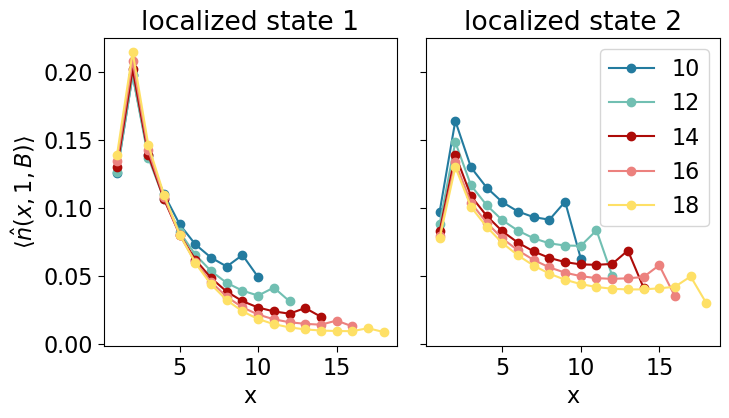

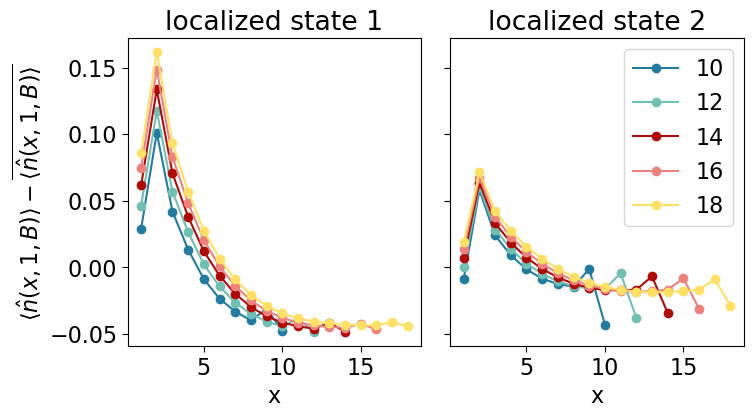

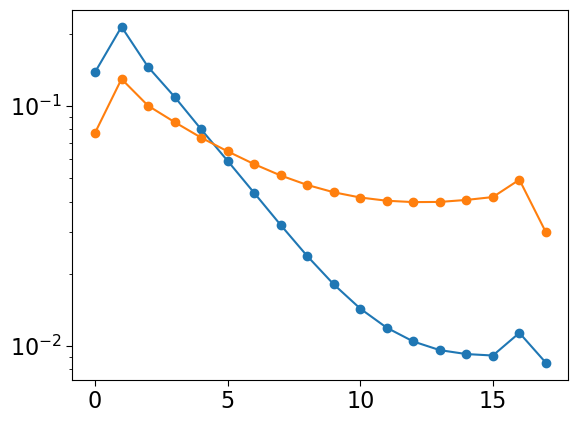

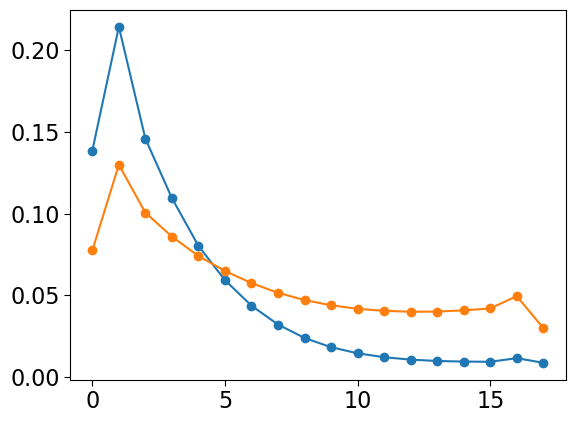

In [276]:
files = h5py.File('TwoExcitationLargerSpectrum.h5', 'r')
files2 = h5py.File('TwoExcitationLargerSpectrum_NotTopo_u-2.1.h5', 'r')
fig, ax = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8, 4))
L_list = [10, 12, 14, 16, 18]
plot_which = [-1, -1, -2, -2, -1] # imaginary unstable.

# color_string = ['#80D0C3', '#9EAAC4', '#A6DDEA', '#F3A59A', '#F9CDBF']
color_string = ['#237B9F', '#71BFB2', '#AD0B08', '#EC817E', '#FEE066']

results1 = []
results2 = []
for i in range(len(L_list)):
    QWZ2 = ParticleConservedSystem_Coo(L_list[i], L_list[i], 2)
    popu_indice = QWZ2.Calcu_Occup()
    popu_NHMany = np.zeros(QWZ2.total_mode)
    for k in range(2*L_list[i]**2): # 应该要加2。
        popu_NHMany[k] = np.sum(np.abs(files['eigvec_NHMany%d'%(L_list[i])][:][popu_indice[k], plot_which[i]])**2)
    nmap1 = popu_NHMany.reshape(L_list[i], 2*L_list[i])
    ax[0].plot(np.arange(1, L_list[i]+1,1), nmap1[:,1], 'o-', label=L_list[i], color=color_string[i])
    results1.append(nmap1[:,1])

    popu_NHMany2 = np.zeros(QWZ2.total_mode)
    for k in range(2*L_list[i]**2): # 应该要加2。
        popu_NHMany2[k] = np.sum(np.abs(files2['eigvec_NHMany%d'%(L_list[i])][:][popu_indice[k], -1])**2)
    nmap2 = popu_NHMany2.reshape(L_list[i], 2*L_list[i])
    ax[1].plot(np.arange(1, L_list[i]+1,1), nmap2[:,1], 'o-', label=L_list[i], color=color_string[i])
    results2.append(nmap2[:,1])
plt.legend()
ax[0].set_xlabel('x')
ax[1].set_xlabel('x')
ax[0].set_title('localized state 1')
ax[1].set_title('localized state 2')
ax[0].set_ylabel(r'$\langle \hat{n}(x,1,B) \rangle$')
plt.subplots_adjust(
    left=0.18,
    right=0.95,
    bottom=0.15,
    top=0.92,
    hspace=-0.1,
    wspace=0.1
)
fig.savefig('DataPicture/SI_Comp1.pdf')
plt.show()

fig, ax = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8, 4))
for i in range(len(L_list)):
    ax[0].plot(np.arange(1, L_list[i]+1,1), results1[i]-np.average(results1[i]), 'o-', color=color_string[i],label=L_list[i])
    ax[1].plot(np.arange(1, L_list[i]+1,1), results2[i]-np.average(results2[i]), 'o-', color=color_string[i],label=L_list[i])
plt.legend()
ax[0].set_xlabel('x')
ax[1].set_xlabel('x')
ax[0].set_title('localized state 1')
ax[1].set_title('localized state 2')
ax[0].set_ylabel(r'$\langle \hat{n}(x,1,B)\rangle - \overline{\langle \hat{n}(x,1,B)\rangle}$')
plt.subplots_adjust(
    left=0.18,
    right=0.95,
    bottom=0.15,
    top=0.92,
    hspace=-0.1,
    wspace=0.1
)
fig.savefig('DataPicture/SI_Comp2.pdf')
plt.show()

# im1 = ax[1].imshow(popu_NHMany.reshape(L_list[i], 2*L_list[i]), origin='lower', cmap=color_string)
nmap1 = popu_NHMany.reshape(L_list[i], 2*L_list[i])
nmap2 = popu_NHMany2.reshape(L_list[i], 2*L_list[i])
plt.plot(nmap1[:,1], 'o-')
plt.plot(nmap2[:,1], 'o-')
plt.yscale('log')
plt.show()
plt.plot(nmap1[:,1], 'o-')
plt.plot(nmap2[:,1], 'o-')
plt.show()
# fig.savefig('DataPicture/Fig_SI.pdf')
files.close()

## 不同系统尺寸的Hybrid chiral skin correlated state

eigval_NHMany6 /eigval_NHMany6
eigval_NHMany7 /eigval_NHMany7
eigval_NHMany8 /eigval_NHMany8
eigval_NHMany9 /eigval_NHMany9
eigvec_NHMany6 /eigvec_NHMany6
eigvec_NHMany7 /eigvec_NHMany7
eigvec_NHMany8 /eigvec_NHMany8
eigvec_NHMany9 /eigvec_NHMany9
[4.26449026+0.25250979j 7.78089435+0.25429289j 7.74883989+0.32708296j]
[3.8851463 +0.2245703j  2.05997771+0.23074392j 7.75437372+0.32218173j]
[5.07275063+0.2421562j  7.73538179+0.29346567j 7.76659546+0.31809839j]
[4.4736556 +0.23717169j 7.755993  +0.30006843j 7.77509982+0.30858918j]


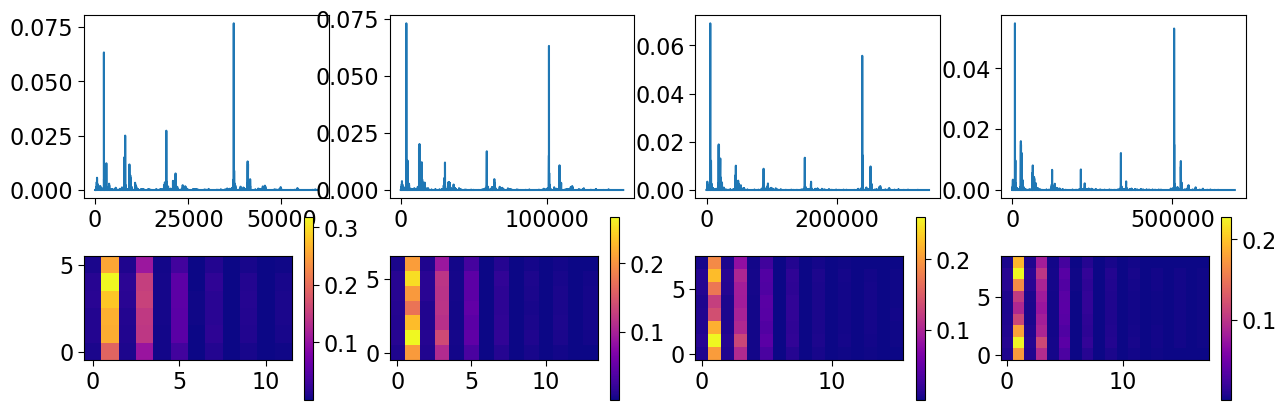

In [88]:
# files = h5py.File('TwoExcitationLargerSpectrum.h5', 'r')
import h5py
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem_Coo
fig, ax = plt.subplots(2, 4, figsize=(14, 5))
L_list = [6,7,8,9]
plot_which = [-1] * 4#[-1, -1, -1, -1] # imaginary unstable.
color_string = 'plasma'
with h5py.File('ThreeExcitationLargerSpectrum.h5', 'r') as files:
    for key in files.keys():
        print(key, files[key].name)
    for i in range(len(L_list)):
        eigval = files['eigval_NHMany%d'%(L_list[i])][:]
        print(eigval)
        # ax[0].scatter(eigval.real, eigval.imag)
        # ax[1].plot(np.abs(files['eigvec_NHMany%d'%(L_list[i])][:][:,-1])**2)   # eigenstate
        ax[0, i].plot(np.abs(files['eigvec_NHMany%d'%(L_list[i])][:][:,plot_which[i]])**2)
        # 画粒子数算符的
        QWZ2 = ParticleConservedSystem_Coo(L_list[i], L_list[i], 3)
        popu_indice = QWZ2.Calcu_Occup()
        popu_NHMany = np.zeros(QWZ2.total_mode)
        for k in range(2*L_list[i]**2): # 应该要加2。
            popu_NHMany[k] = np.sum(np.abs(files['eigvec_NHMany%d'%(L_list[i])][:][popu_indice[k], plot_which[i]])**2)
        im1 = ax[1,i].imshow(popu_NHMany.reshape(L_list[i], 2*L_list[i]), origin='lower', cmap=color_string)
        cbar = plt.colorbar(im1, ax=ax[1,i], fraction=0.1)
        # cbar2.ax.tick_params(axis='both', which='major', labelsize=labelsize)

plt.subplots_adjust(
    left=0.12,
    right=0.95,
    bottom=0.15,
    top=0.92,
    hspace=0.1,
    wspace=0.25
)
plt.show()
fig.savefig('DataPicture/LargeThreeExcitation.pdf', bbox_inches='tight')

eigval_NHMany6 /eigval_NHMany6
eigval_NHMany7 /eigval_NHMany7
eigval_NHMany8 /eigval_NHMany8
eigval_NHMany9 /eigval_NHMany9
eigvec_NHMany6 /eigvec_NHMany6
eigvec_NHMany7 /eigvec_NHMany7
eigvec_NHMany8 /eigvec_NHMany8
eigvec_NHMany9 /eigvec_NHMany9
[5.07275063+0.2421562j  7.73538179+0.29346567j 7.76659546+0.31809839j]


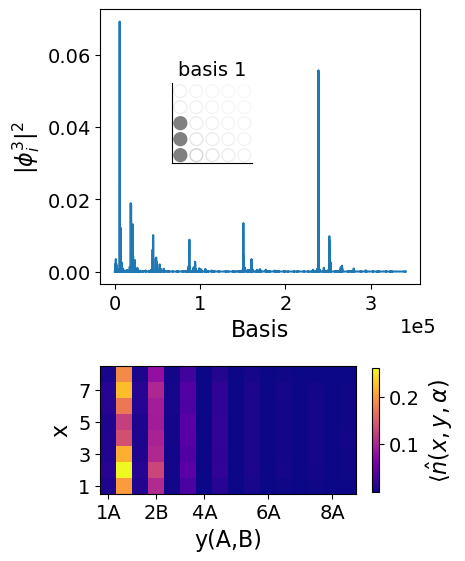

In [ ]:
### 不能动，数据用图。
import h5py
from MeasureNonhermitianSkin.Experimental.ManyBodyQWZ import ParticleConservedSystem_Coo
L_site = 8
fontsize = 16
fig, ax = plt.subplots(2, 1, figsize=(4, 6))
plot_which = [-1]
i=0
labelsize=14
with h5py.File('ThreeExcitationLargerSpectrum.h5', 'r') as files:
    for key in files.keys():
        print(key, files[key].name)
    eigval = files['eigval_NHMany%d'%(L_site)][:]
    print(eigval)
    # ax[0].scatter(eigval.real, eigval.imag)
    # ax[1].plot(np.abs(files['eigvec_NHMany%d'%(L_site)][:][:,-1])**2)   # eigenstate
    ax[0].plot(np.abs(files['eigvec_NHMany%d'%(L_site)][:][:,-1])**2)
    # 画粒子数算符的
    QWZ2 = ParticleConservedSystem_Coo(L_site, L_site, 3)
    popu_indice = QWZ2.Calcu_Occup()
    popu_NHMany = np.zeros(QWZ2.total_mode)
    for k in range(2*L_site**2): # 应该要加2。
        popu_NHMany[k] = np.sum(np.abs(files['eigvec_NHMany%d'%(L_site)][:][popu_indice[k], plot_which[i]])**2)
    im1 = ax[1].imshow(popu_NHMany.reshape(L_site, 2*L_site), origin='lower', cmap=color_string)
    cbar = fig.colorbar(im1, ax=ax[1], shrink=0.45)
    cbar.ax.set_ylabel(r'$\langle \hat{n}(x,y,\alpha)$', fontsize=fontsize)
    cbar.ax.tick_params(axis='both', which='major', labelsize=labelsize)

ax[0].set_xlabel('Basis', fontsize=fontsize)
ax[0].set_ylabel(r'$\vert \phi_i^3 \vert^2$', fontsize=fontsize)

ax[1].set_xlabel('y(A,B)', fontsize=fontsize)
ax[1].set_ylabel('x', fontsize=fontsize)
ax[0].tick_params(axis='both', which='major', labelsize=labelsize)
ax[1].tick_params(axis='both', which='major', labelsize=labelsize)
# ax[1].set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax4.set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
# ax[1].set_yticks(ticks=[2,5], labels=[5,2])
# ax4.set_yticks(ticks=[2,5], labels=[5,2])
# ax[1].set_xticks(ticks=[4,7,10], labels=['3A','4B','6A'])
ax[1].set_xticks(ticks=[0,3,6,10,14], labels=['1A','2B','4A','6A', '8A'])
ax[1].set_yticks(ticks=[0,2,4,6], labels=[1,3,5,7])

# 画双激发粒子
new_ax = fig.add_axes([0.3, 0.69, 0.2, 0.2]) 
ShowTwoExcitationPlot(new_ax,3)
new_ax.set_title('basis 1', fontsize=14)

ax[0].ticklabel_format(style='sci', axis='x', scilimits=(0,0))
offset_text = ax[0].get_xaxis().get_offset_text()
# 设置字体大小为12
offset_text.set_fontsize(labelsize)
offset_text.set_x(1.05)
# offset_text.set_x(2)

# for col in range(2):
#     ax[1, col].ticklabel_format(style='sci', axis='y', scilimits=(0,0))
#     offset_text = ax[row, col].get_yaxis().get_offset_text()
#     # 设置字体大小为12
#     offset_text.set_fontsize(labelsize)

plt.subplots_adjust(
    left=0.12,
    right=0.92,
    bottom=0.05,
    top=0.98,
    hspace=0.03,
    wspace=0.25
)
plt.show()
fig.savefig('DataPicture/SI_ThreeExcitationSize8.pdf',bbox_inches='tight')